In [1]:
import os
from datetime import datetime
import pickle
import random
import math
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler, MaxAbsScaler, MinMaxScaler

import torch
import torch.nn as nn
import torch.nn.functional as F

os.makedirs("models", exist_ok=True)

def set_all_seeds(seed):
    np.random.seed(seed)
    random.seed(seed)
    torch.manual_seed(seed)

seed = 0
set_all_seeds(seed)

In [2]:
df = pd.read_csv(f"BTCUSDT-15m-data.csv")
print(df)

                  timestamp      open_time      open      high       low  \
0       2017-08-17 04:00:00  1502942400000   4261.48   4280.56   4261.48   
1       2017-08-17 04:15:00  1502943300000   4261.48   4270.41   4261.32   
2       2017-08-17 04:30:00  1502944200000   4280.00   4310.07   4267.99   
3       2017-08-17 04:45:00  1502945100000   4310.07   4313.62   4291.37   
4       2017-08-17 05:00:00  1502946000000   4308.83   4328.69   4304.31   
...                     ...            ...       ...       ...       ...   
315235  2026-08-19 18:00:00  1787162400000  68187.39  68236.82  68042.42   
315236  2026-08-19 18:15:00  1787163300000  68238.57  68322.74  68221.64   
315237  2026-08-19 18:30:00  1787164200000  68272.37  68424.05  68236.25   
315238  2026-08-19 18:45:00  1787165100000  68423.58  68444.43  68336.57   
315239  2026-08-19 19:00:00  1787166000000  68397.33  68452.53  68108.45   

           close     volume     close_time      quote_av  trades  tb_base_av  \
0      

**Check missing values**

In [3]:
print(df.isnull())
print(f"Counts how many missing values there are in each column: {df.isnull().sum()}")
print(f"Total missing values: {df.isnull().sum().sum()}")

        timestamp  open_time   open   high    low  close  volume  close_time  \
0           False      False  False  False  False  False   False       False   
1           False      False  False  False  False  False   False       False   
2           False      False  False  False  False  False   False       False   
3           False      False  False  False  False  False   False       False   
4           False      False  False  False  False  False   False       False   
...           ...        ...    ...    ...    ...    ...     ...         ...   
315235      False      False  False  False  False  False   False       False   
315236      False      False  False  False  False  False   False       False   
315237      False      False  False  False  False  False   False       False   
315238      False      False  False  False  False  False   False       False   
315239      False      False  False  False  False  False   False       False   

        quote_av  trades  tb_base_av  t

**Split data**

In [4]:
train_end_idx = 252_000
val_end_idx = 283_500

# 3-way split, chronological, no shuffling across the boundaries:
#   df_train -> fit the model
#   df_val   -> checked every epoch to decide when to stop / which checkpoint
#               to keep (this replaces the old df_test in that role)
#   df_test  -> touched exactly once, in the final cell, after training is
#               completely finished. No epoch/checkpoint decision may look at
#               df_test's performance.
df_train = df.iloc[:train_end_idx].copy()
df_val = df.iloc[train_end_idx:val_end_idx].copy()
df_test = df.iloc[val_end_idx:].copy()

df_val.reset_index(drop=True, inplace=True)
df_test.reset_index(drop=True, inplace=True)

print(f"Length of df_train: {len(df_train)}")
print(f"Length of df_val:   {len(df_val)}")
print(f"Length of df_test:  {len(df_test)}")

Length of df_train: 252000
Length of df_val:   31500
Length of df_test:  31740


**Building Meaningful Features**

In [5]:
def build_features(opens, highs, lows, closes, volumes, train_scalers=None):

    # Build features
    feature1 = (closes - opens) / opens
    feature2 = (highs - opens) / opens
    feature3 = (highs - closes) / closes
    feature4 = (lows - opens) / opens
    feature5 = (lows - closes) / closes
    feature6 = (highs - lows) / opens
    feature7 = (highs - lows) / closes
    feature8 = volumes

    # Stack features
    features = [
        feature1,
        feature2,
        feature3,
        feature4,
        feature5,
        feature6,
        feature7,
        feature8,
    ]
    num_features = len(features)
    scaled_fts = []

    if train_scalers is None:
        train_scalers = [MaxAbsScaler() for _ in range(num_features)]
        is_train = True
    else:
        is_train = False

    for i in range(num_features):
        # Get train scaler
        scaler = train_scalers[i]
        if is_train:
            # Scaler -> Fit -> Train dataset
            scaled_ft = scaler.fit_transform(features[i].reshape(-1, 1))
            # Save the train scaler in a list
        elif not is_train:
            # Scaler -> NOT Fit -> Test dataset
            scaled_ft = scaler.transform(features[i].reshape(-1, 1))

        # Update list of SCALED features
        scaled_fts.append(scaled_ft.flatten())

    # Stack features
    scaled_features = np.stack(scaled_fts, axis=-1)

    # Get num. features
    num_features = scaled_features.shape[-1]
    return scaled_features, num_features, train_scalers

**Example of how the scaler works**

In [6]:
import numpy as np
from sklearn.preprocessing import MaxAbsScaler

# Suppose we have a simple 1D array (e.g. daily returns)
X = np.array([ -2, -1, 0, 1, 2 ])

print("Original data:", X)

# Step 1: reshape into 2D (because sklearn expects shape (n_samples, n_features))
X_2d = X.reshape(-1, 1)

# Step 2: create the scaler and fit_transform
scaler = MaxAbsScaler()
X_scaled = scaler.fit_transform(X_2d)

# Step 3: flatten back to 1D for convenience
X_scaled = X_scaled.flatten()

print("Scaled data:", X_scaled)


Original data: [-2 -1  0  1  2]
Scaled data: [-1.  -0.5  0.   0.5  1. ]


**Preprocess data**

In [7]:
def preprocess_data(seq_len, df, train_scalers=None):
    m = len(df)

    opens = np.array(df['open'].values)
    highs = np.array(df['high'].values)
    lows = np.array(df['low'].values)
    closes = np.array(df['close'].values)
    volumes = np.array(df['volume'].values)

    # Build features
    features, num_features, train_scalers = build_features(opens, highs, lows, closes, volumes, train_scalers)

    # Calculate number of samples
    num_samples = m - seq_len

    # Create storage for inputs & targets
    X = np.zeros([num_samples, seq_len, num_features], dtype=np.float32)
    Y = np.zeros([num_samples, num_features], dtype=np.float32)

    # Create samples (X, Y)
    for i in range(num_samples):
        X[i] = features[i : i+seq_len]
        Y[i] = features[i+seq_len : i+seq_len+1]

    # Fix alignment
    opens = np.array(opens[seq_len:])
    closes = np.array(closes[seq_len:])

    return X, Y, num_features, opens, closes, train_scalers

In [8]:
# Sequence Length
seq_len = 96

# Preprocess data. df_val is what the training loop is allowed to check every
# epoch; df_test is preprocessed here but not looked at again until the final
# one-time evaluation cell at the end of this notebook.
X_train, Y_train, num_features, _, _, train_scalers = preprocess_data(seq_len, df_train)
X_val, Y_val, num_features, backtest_opens_val, backtest_closes_val, _ = preprocess_data(seq_len, df_val, train_scalers)
X_test, Y_test, num_features, backtest_opens_test, backtest_closes_test, _ = preprocess_data(seq_len, df_test, train_scalers)

In [9]:
m_train = X_train.shape[0]
m_val = X_val.shape[0]
m_test = X_test.shape[0]
print(f"m_train: {m_train}")
print(f"m_val: {m_val}")
print(f"m_test: {m_test}")
print(f"X_train shape: {X_train.shape}")
print(f"Y_train shape: {Y_train.shape}")
print(f"X_val shape: {X_val.shape}")
print(f"Y_val shape: {Y_val.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"Y_test shape: {Y_test.shape}")

m_train: 251904
m_val: 31404
m_test: 31644
X_train shape: (251904, 96, 8)
Y_train shape: (251904, 8)
X_val shape: (31404, 96, 8)
Y_val shape: (31404, 8)
X_test shape: (31644, 96, 8)
Y_test shape: (31644, 8)


**Transform data to Torch Tensor**

In [10]:
device = torch.device("cuda:0" if torch.cuda.is_available() else 'cpu')
print("my deive: ", device)

X_train = torch.from_numpy(X_train.astype(np.float32)).to(device, dtype=torch.float32)
Y_train = torch.from_numpy(Y_train.astype(np.float32)).to(device, dtype=torch.float32)

X_val = torch.from_numpy(X_val.astype(np.float32)).to(device, dtype=torch.float32)
Y_val = torch.from_numpy(Y_val.astype(np.float32)).to(device, dtype=torch.float32)

# X_test/Y_test are kept on CPU and are not touched anywhere in the training
# loop below -- only in the final one-time evaluation cell at the end.
X_test = torch.from_numpy(X_test.astype(np.float32))
Y_test = torch.from_numpy(Y_test.astype(np.float32))

Y_pred_val = torch.zeros([m_val, num_features], device=device, dtype=torch.float32)

my deive:  cpu


**Build model**

In [11]:
class Model(nn.Module):
    def __init__(self):
        super().__init__()

        # Conv1 block #1
        self.conv1 = nn.Conv1d(
            in_channels=num_features,
            out_channels=32,
            kernel_size=3,
            padding=1,
            stride=1,
        )
        self.act1 = nn.GELU()

        # Conv1 block #2
        self.conv2 = nn.Conv1d(
            in_channels=32, 
            out_channels=64,
            kernel_size=3,
            padding=1
        )
        self.act2 = nn.GELU()

        # Output layer
        self.fc_out = nn.Linear(64, num_features)

    def forward(self, x):
        x = x.permute(0, 2, 1) # (batch, num_features, seq_len)

        # Conv block #1
        x = self.conv1(x)
        x = self.act1(x)

        # Conv block #2
        x = self.conv2(x)
        x = self.act2(x)

        x = x.permute(0, 2, 1) # (batch, seq_len, num_features)
        x = x[:, -1, :] # get last hidden

        # Output layer
        x = self.fc_out(x)
        return x



**Initialization**

In [12]:
# Initialize model
model = Model()

# Transfer model to device
model.to(device)

# Initialize criterion
criterion = nn.MSELoss()

# Choose learning rate
lr = 1e-4

# Create optimizer
optimizer = torch.optim.Adam(model.parameters(), lr=lr)

# Choose batch size
batch_size = 32

# Lists of train/validation losses
train_losses = []
val_losses = []

val_equity_epochs = []
val_accuracy_epochs = []

# Tracks the single best checkpoint seen so far, by validation equity --
# this is the file the final held-out test cell evaluates.
best_val_equity = -float("inf")

# Set epoch
num_epochs = 200

In [13]:
def create_minibatches(X, Y, batch_size, seed, shuffle=True):

    mini_batches = []
    m = len(X)
    if shuffle:
        permutation = list(np.random.permutation(m))
        X = X[permutation]
        Y = Y[permutation]
    num_batches = m // batch_size
    for k in range(num_batches):
        mb_X = X[k * batch_size : k * batch_size + batch_size]
        mb_Y = Y[k * batch_size : k * batch_size + batch_size]
        mb_pair = (mb_X, mb_Y)
        mini_batches.append(mb_pair)

    seed += 1
    set_all_seeds(seed)

    return mini_batches, seed

**Load model (if available)**

In [14]:
def load_training_data(model, optimizer):
    checkpoint = torch.load('training_process', weights_only=False)
    epoch = checkpoint['epoch']
    train_losses = checkpoint['train_losses']
    val_losses = checkpoint['val_losses']
    val_equity_epochs = checkpoint['val_equity_epochs']
    val_accuracy_epochs = checkpoint['val_accuracy_epochs']
    best_val_equity = checkpoint['best_val_equity']
    seed = checkpoint['seed']

    # Load model's weights & optimizer's state
    model.load_state_dict(checkpoint['model_state_dict'])
    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
    return model, optimizer, epoch, train_losses, val_losses, val_equity_epochs, val_accuracy_epochs, best_val_equity, seed


if os.path.exists("training_process"):
    model, optimizer, epoch, train_losses, val_losses, val_equity_epochs, val_accuracy_epochs, best_val_equity, seed = load_training_data(model, optimizer)
    print(f"Loaded model!")
else:
    print(f"No training process to load.")
    epoch = 0

No training process to load.


**Train model**

Epoch: 0, Val Equity: 1505.00, Val Accuracy: 50.45 train_losses: 0.00032427390189559074, val_losses: 9.63946949923411e-05, Duration: 0:01:09.739003


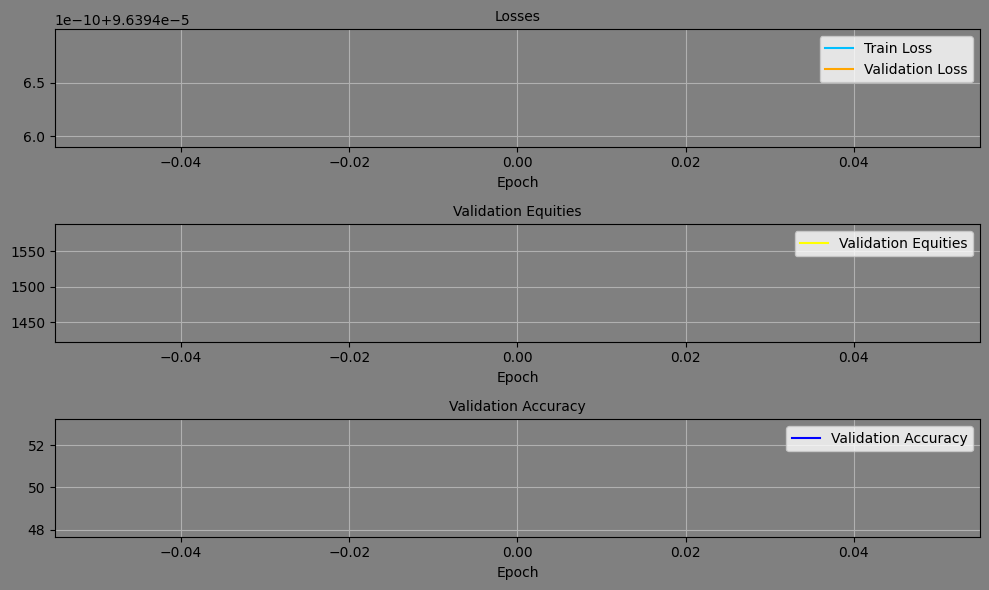

Epoch: 1, Val Equity: 1059.06, Val Accuracy: 50.15 train_losses: 0.00029074068273147774, val_losses: 9.244035754818469e-05, Duration: 0:01:10.458680


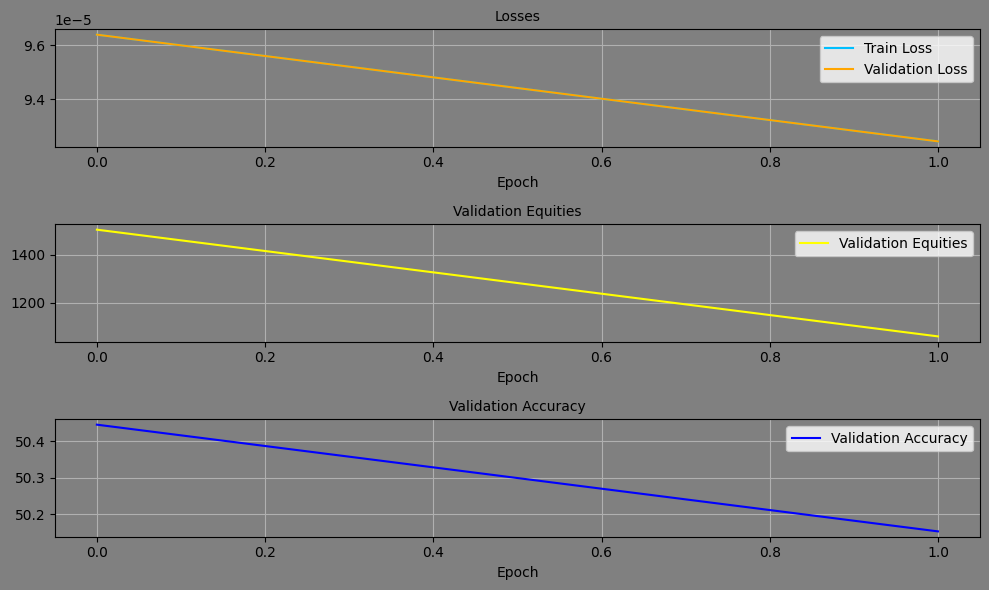

Epoch: 2, Val Equity: 1056.57, Val Accuracy: 50.17 train_losses: 0.00028998443506927615, val_losses: 9.327566658612341e-05, Duration: 0:01:07.689499


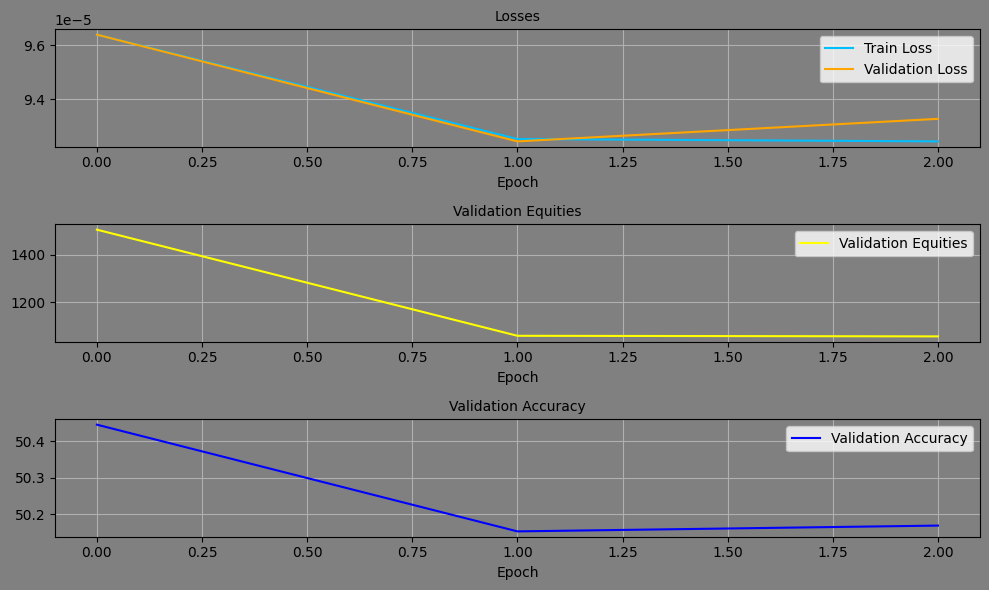

Epoch: 3, Val Equity: 1192.04, Val Accuracy: 49.17 train_losses: 0.00028975610451667543, val_losses: 9.266035340260714e-05, Duration: 0:01:07.908448


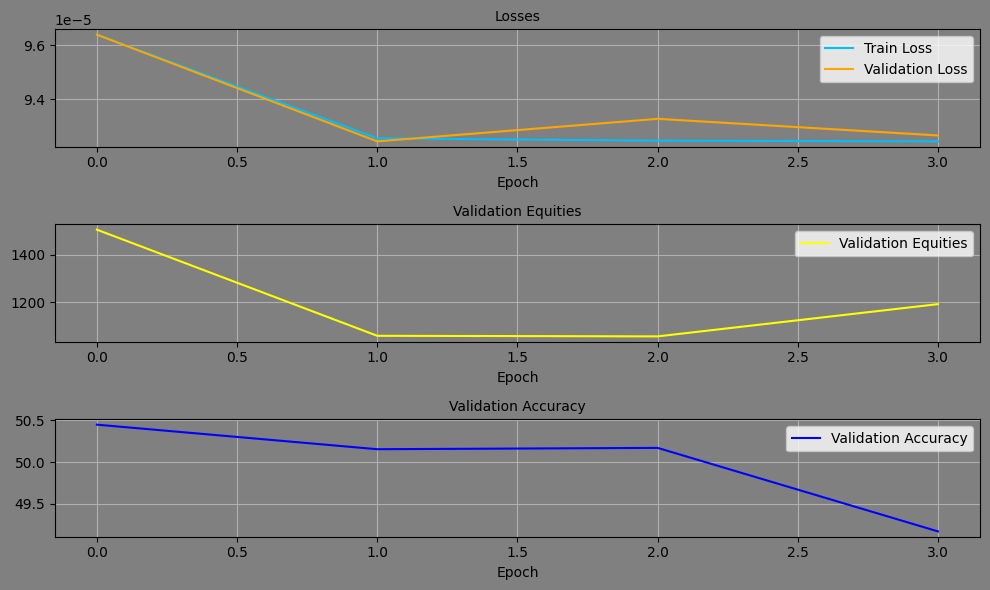

Epoch: 4, Val Equity: 1084.22, Val Accuracy: 50.21 train_losses: 0.00028957048254728133, val_losses: 9.141210466623306e-05, Duration: 0:01:07.613716


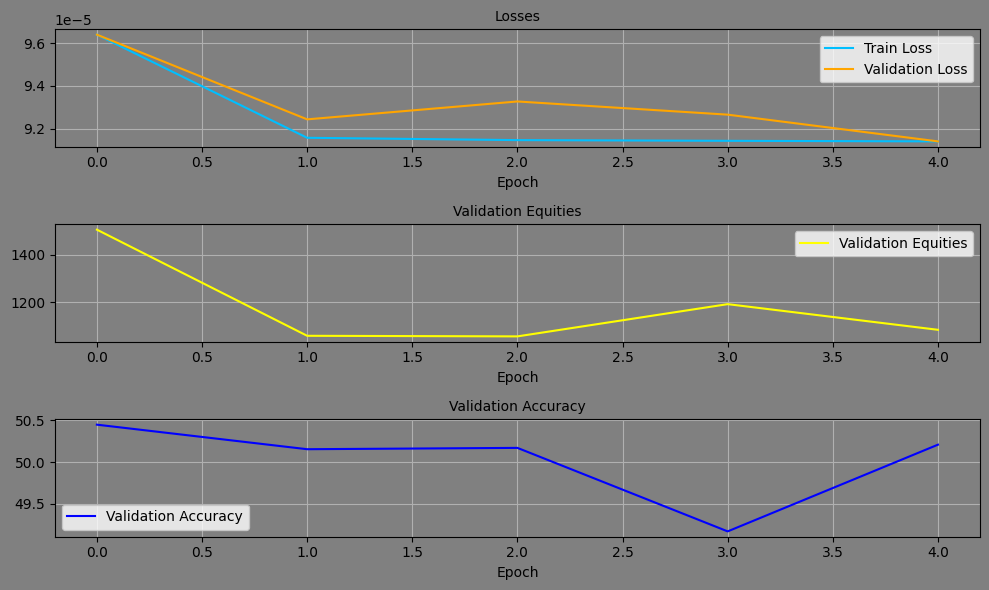

Epoch: 5, Val Equity: 1098.48, Val Accuracy: 48.94 train_losses: 0.00028924201347343677, val_losses: 9.208960545947775e-05, Duration: 0:01:07.501265


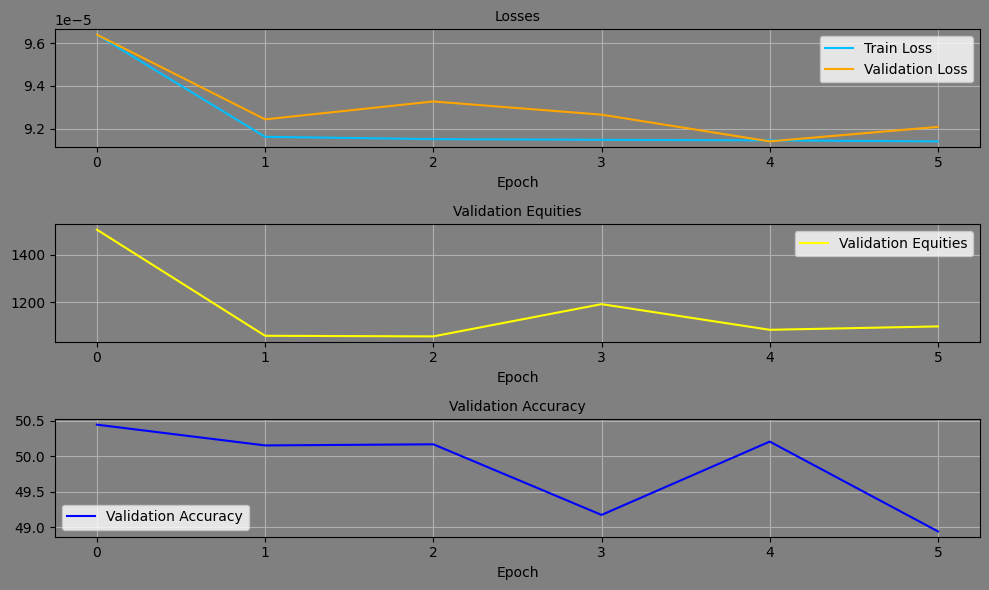

Epoch: 6, Val Equity: 1442.57, Val Accuracy: 48.94 train_losses: 0.0002893181733799157, val_losses: 9.104356286115944e-05, Duration: 0:01:07.885491


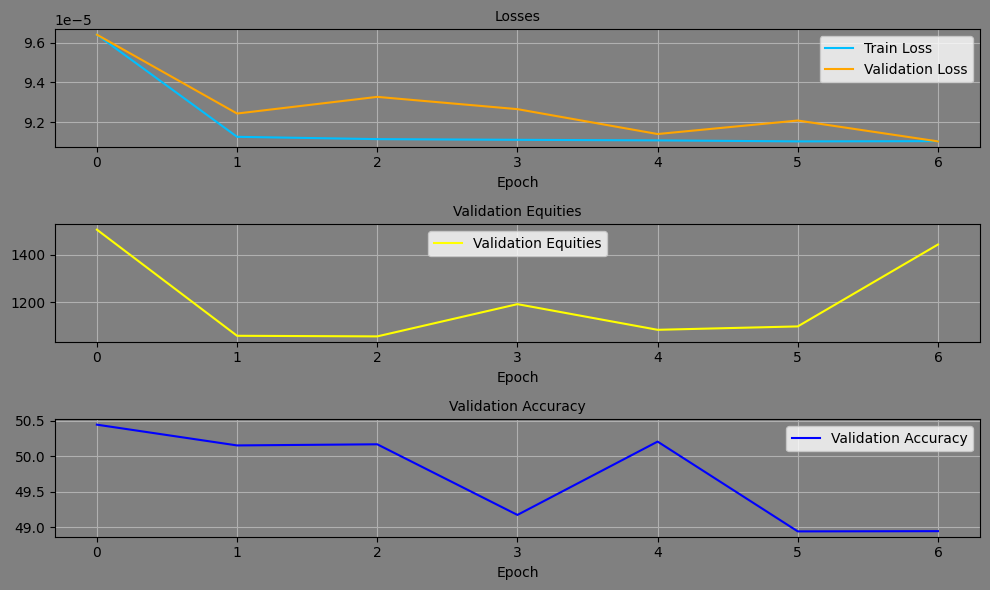

Epoch: 7, Val Equity: 1480.95, Val Accuracy: 50.57 train_losses: 0.0002890950084420405, val_losses: 9.063713514478877e-05, Duration: 0:01:07.874640


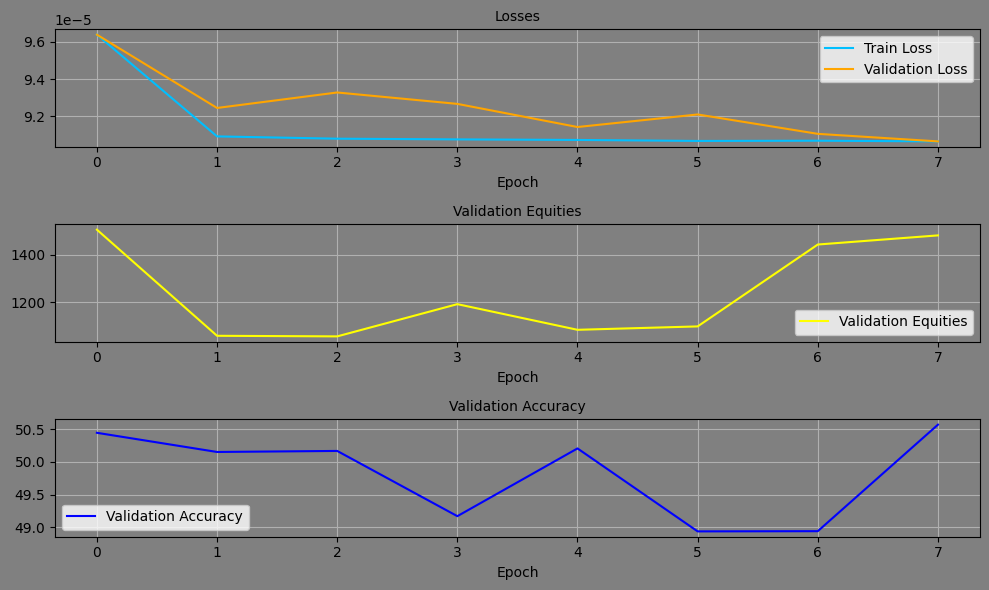

Epoch: 8, Val Equity: 1574.17, Val Accuracy: 50.53 train_losses: 0.00028886896236359253, val_losses: 9.09941372810863e-05, Duration: 0:01:08.030620


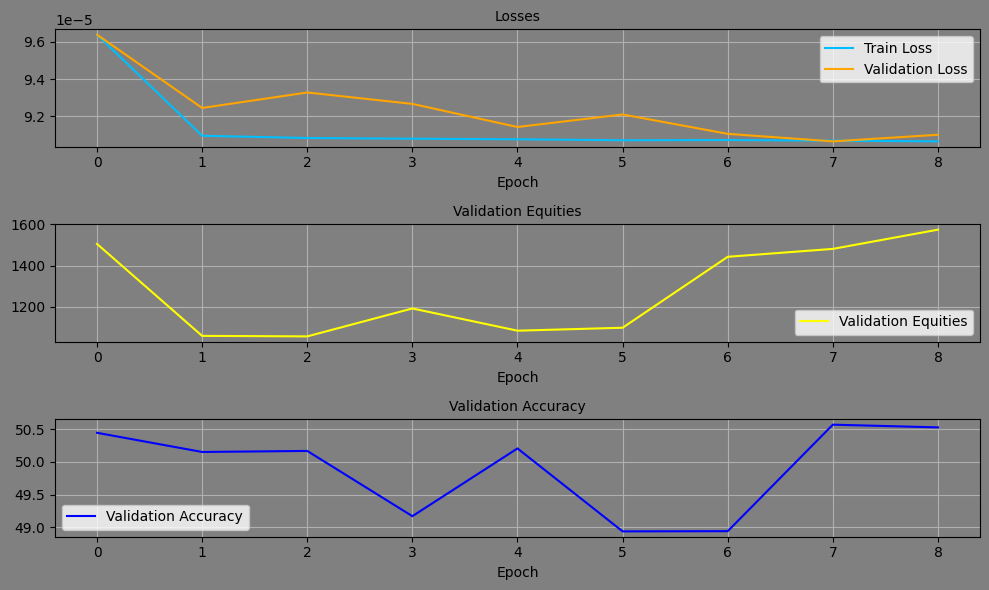

Epoch: 9, Val Equity: 915.27, Val Accuracy: 49.61 train_losses: 0.0002887540823908276, val_losses: 9.107289224630222e-05, Duration: 0:01:08.016141


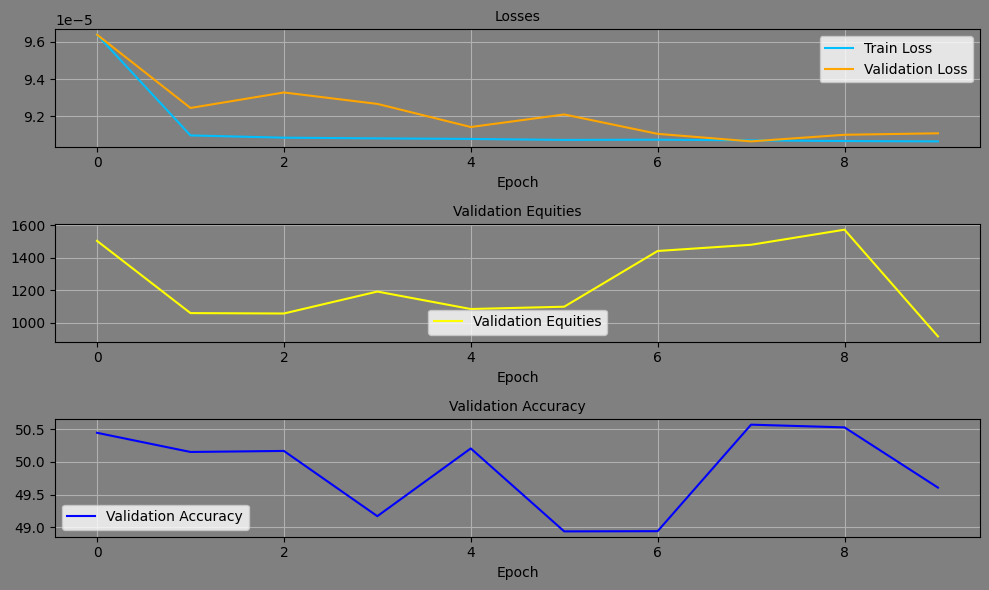

Epoch: 10, Val Equity: 1291.49, Val Accuracy: 49.24 train_losses: 0.0002887856496912038, val_losses: 9.125861106440425e-05, Duration: 0:01:08.164954


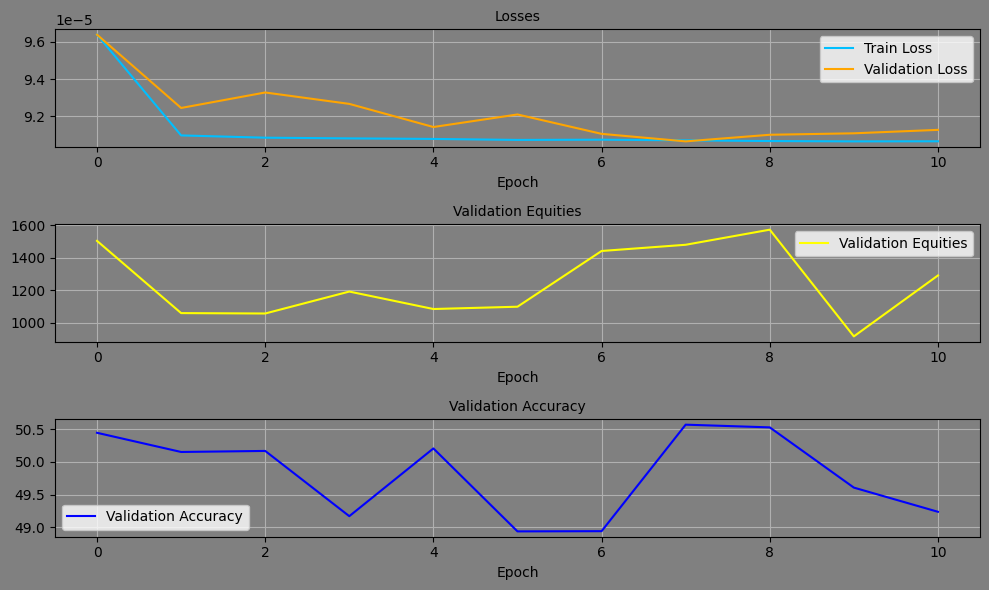

Epoch: 11, Val Equity: 1323.82, Val Accuracy: 48.89 train_losses: 0.0002885145038464351, val_losses: 9.11373645067215e-05, Duration: 0:01:07.765781


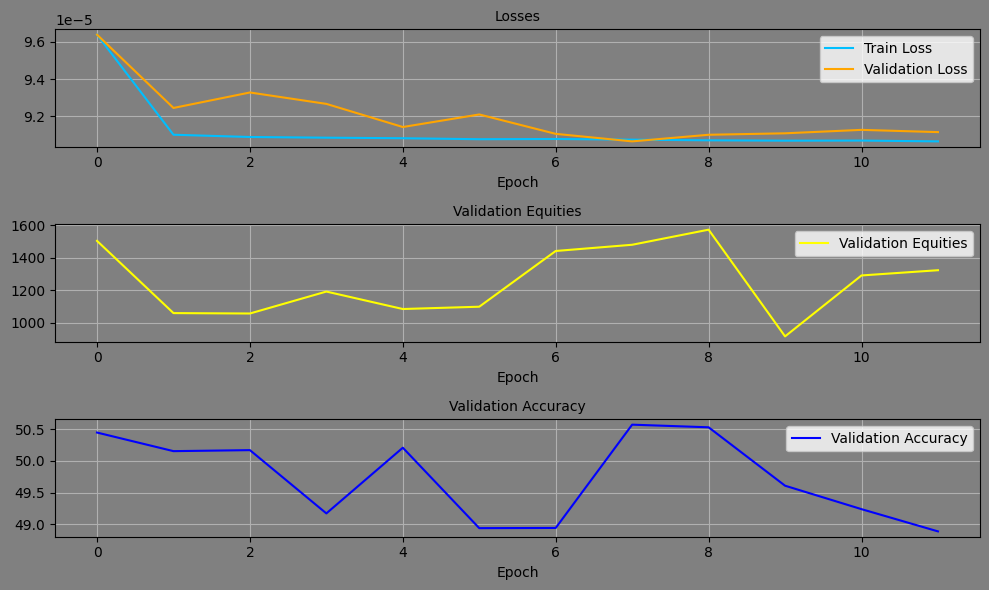

Epoch: 12, Val Equity: 685.22, Val Accuracy: 50.10 train_losses: 0.00028846283356411673, val_losses: 9.18332880246453e-05, Duration: 0:01:08.124539


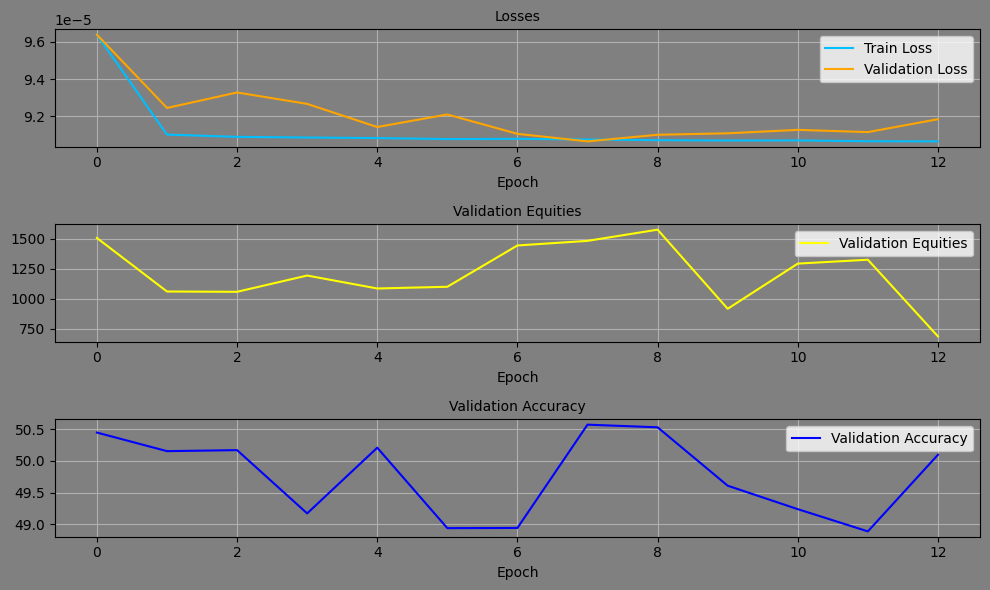

Epoch: 13, Val Equity: 1197.70, Val Accuracy: 49.83 train_losses: 0.00028836440352220013, val_losses: 9.591131674824283e-05, Duration: 0:01:07.895480


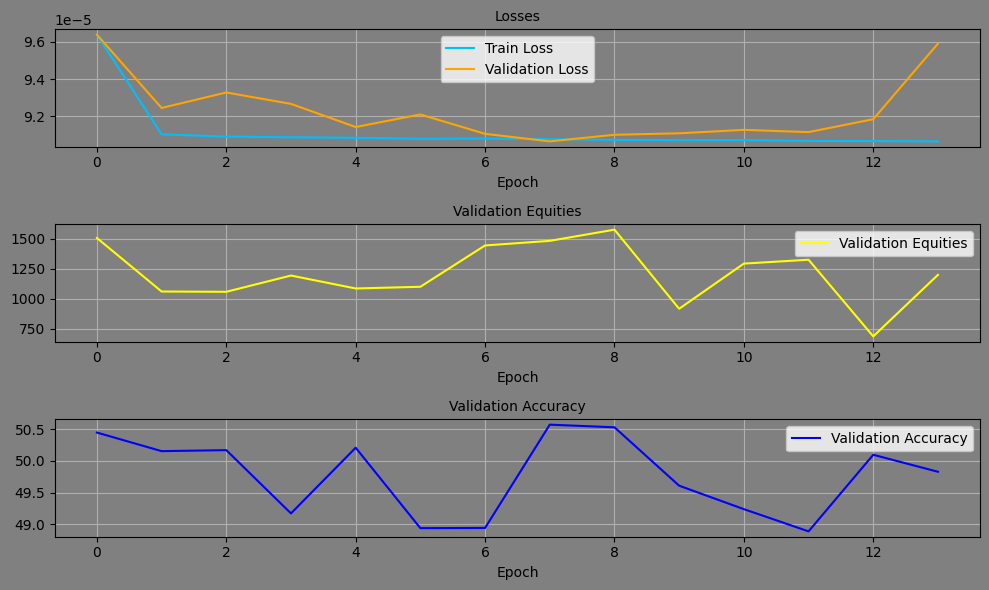

Epoch: 14, Val Equity: 773.34, Val Accuracy: 50.11 train_losses: 0.00028841806914439017, val_losses: 9.345260332338512e-05, Duration: 0:01:07.715017


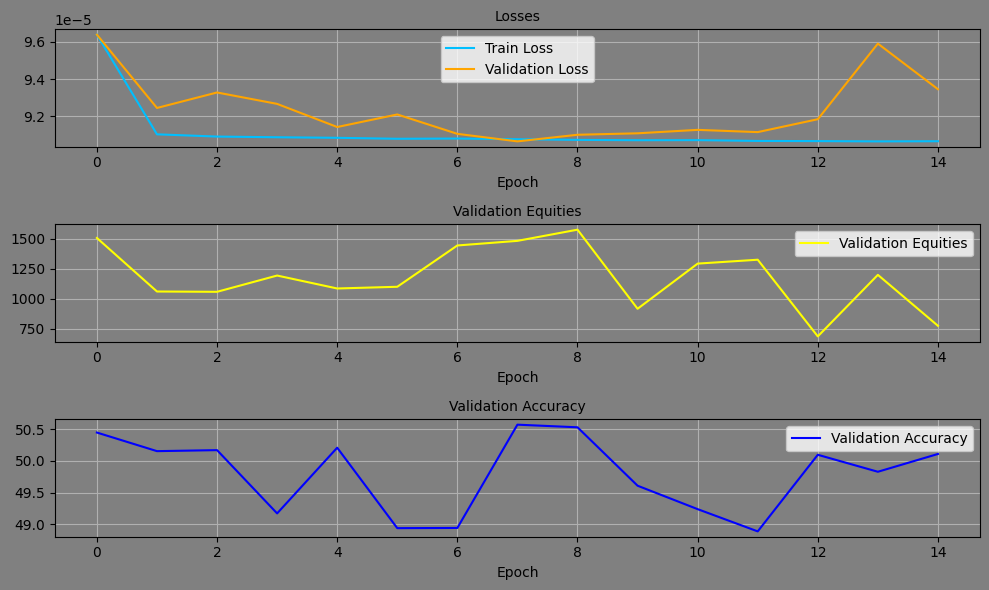

Epoch: 15, Val Equity: 920.89, Val Accuracy: 49.87 train_losses: 0.00028828380701322124, val_losses: 9.111214603763074e-05, Duration: 0:01:08.096608


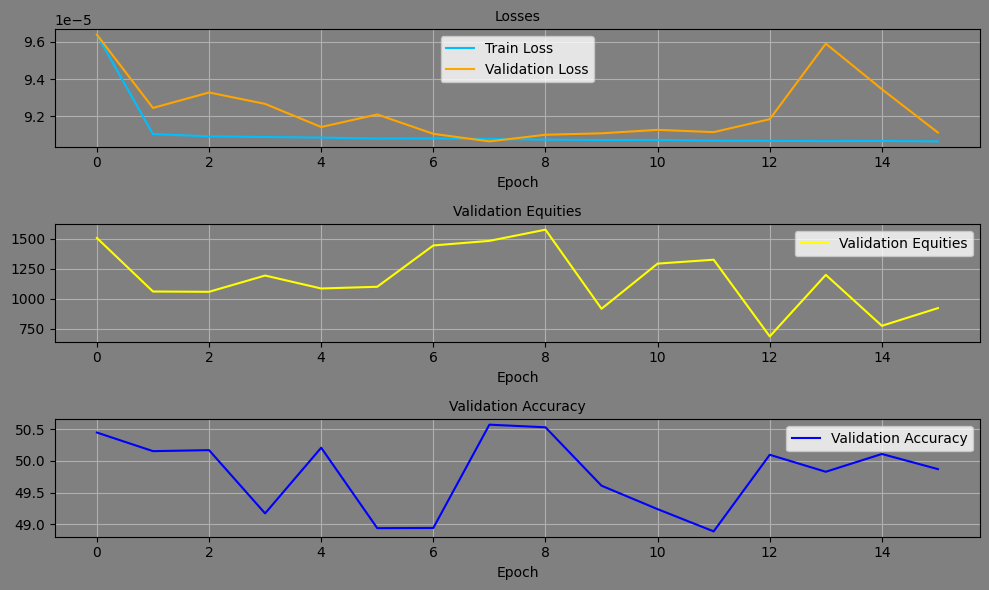

Epoch: 16, Val Equity: 1755.56, Val Accuracy: 49.15 train_losses: 0.00028812048900294756, val_losses: 9.349216998089105e-05, Duration: 0:01:08.148074


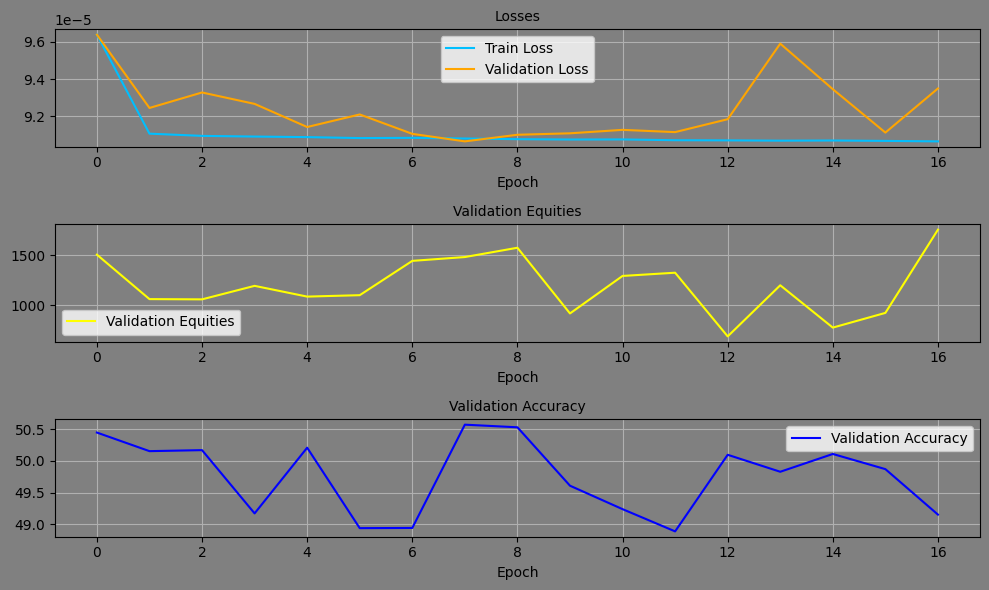

Epoch: 17, Val Equity: 2465.85, Val Accuracy: 51.21 train_losses: 0.0002881209029889457, val_losses: 9.098301234189421e-05, Duration: 0:01:07.935683


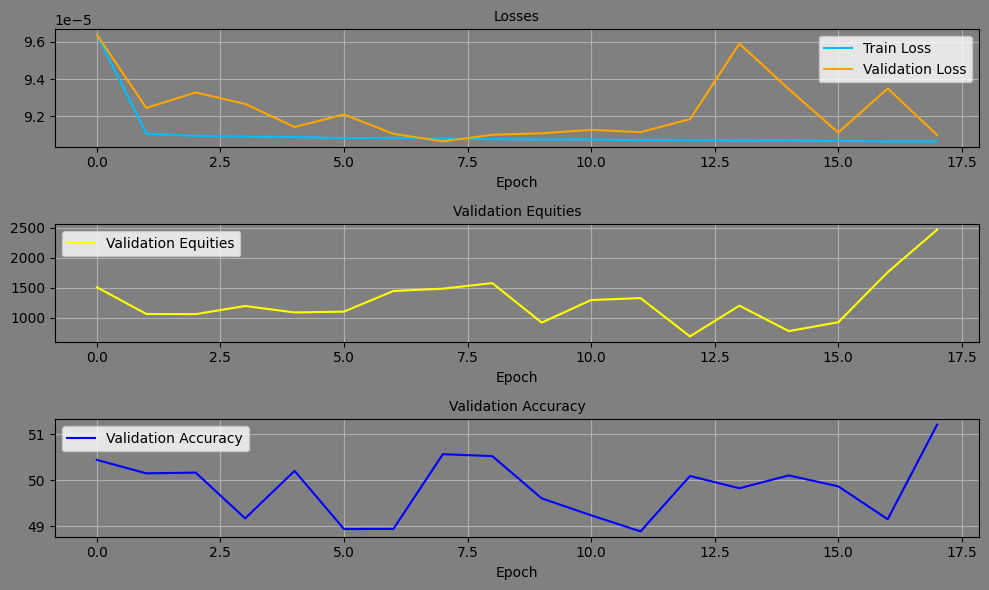

Epoch: 18, Val Equity: 2347.90, Val Accuracy: 50.80 train_losses: 0.00028799424342797073, val_losses: 9.047913044923916e-05, Duration: 0:01:07.825580


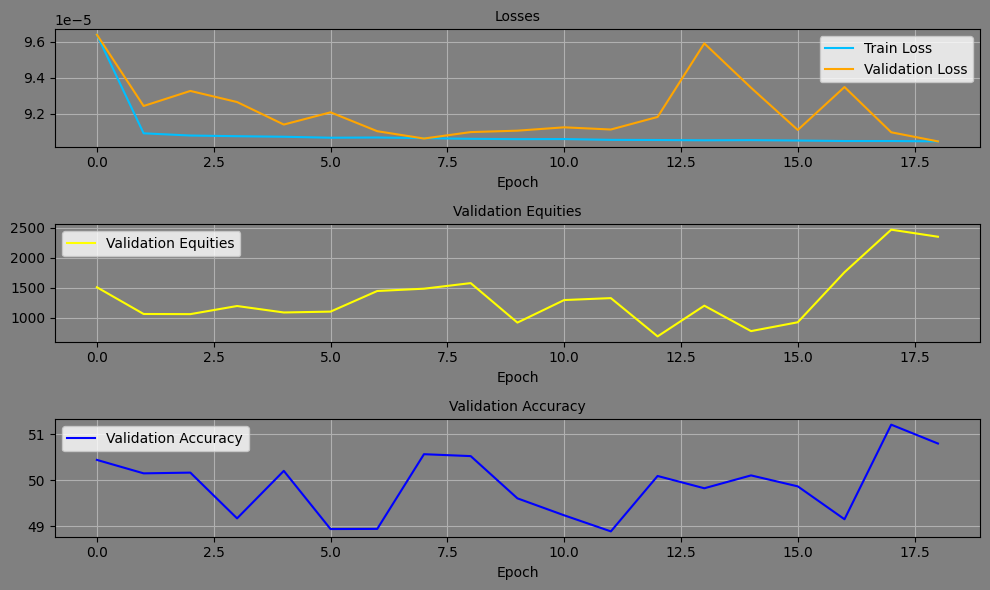

Epoch: 19, Val Equity: 1799.64, Val Accuracy: 49.26 train_losses: 0.00028794392678987345, val_losses: 9.212575241690502e-05, Duration: 0:01:08.068012


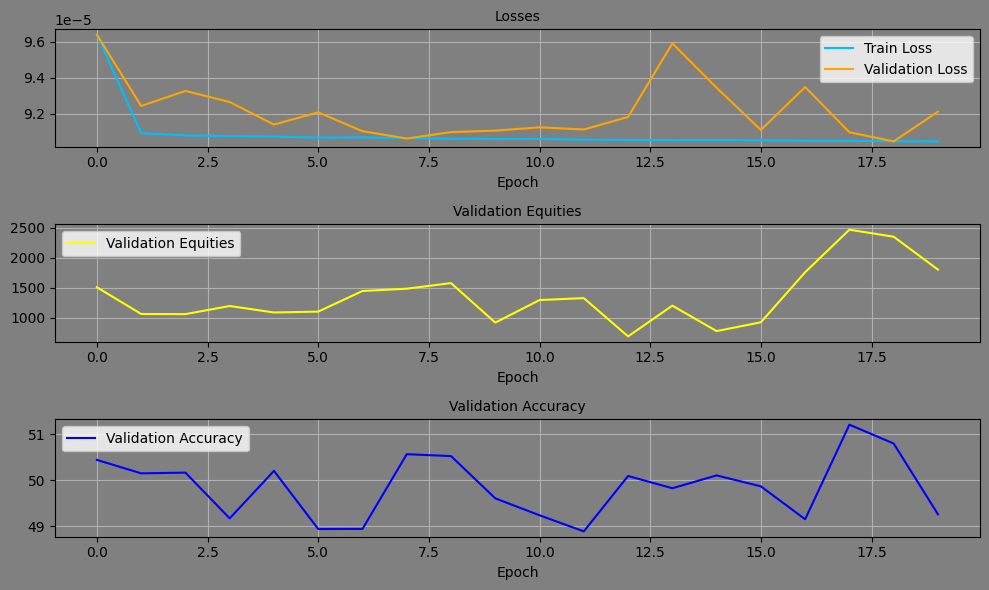

Epoch: 20, Val Equity: 1168.56, Val Accuracy: 49.94 train_losses: 0.00028778926029018274, val_losses: 9.077171853277832e-05, Duration: 0:01:07.811679


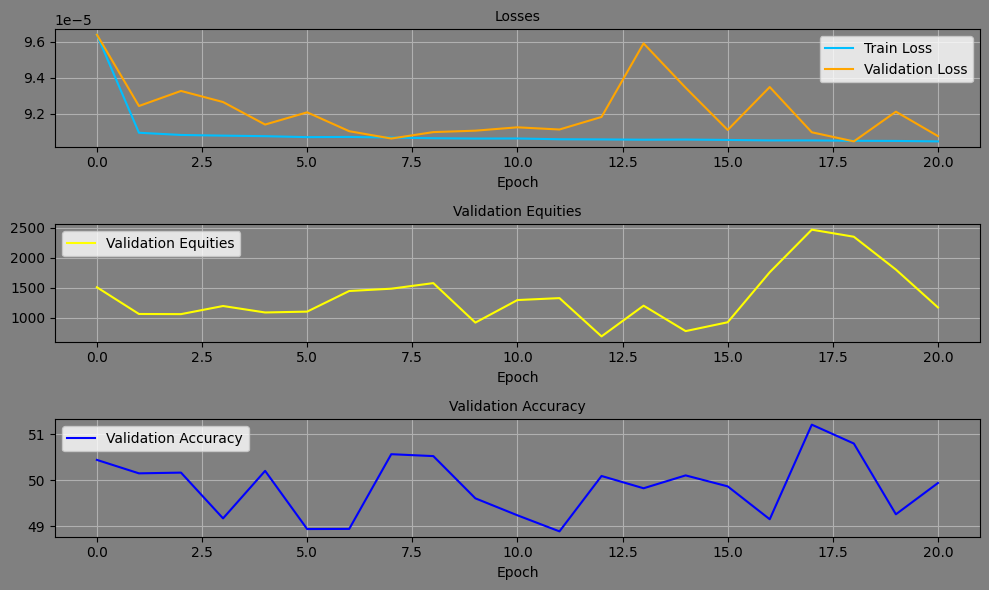

Epoch: 21, Val Equity: 2288.91, Val Accuracy: 50.60 train_losses: 0.00028763991796230905, val_losses: 9.287185093853623e-05, Duration: 0:01:07.876582


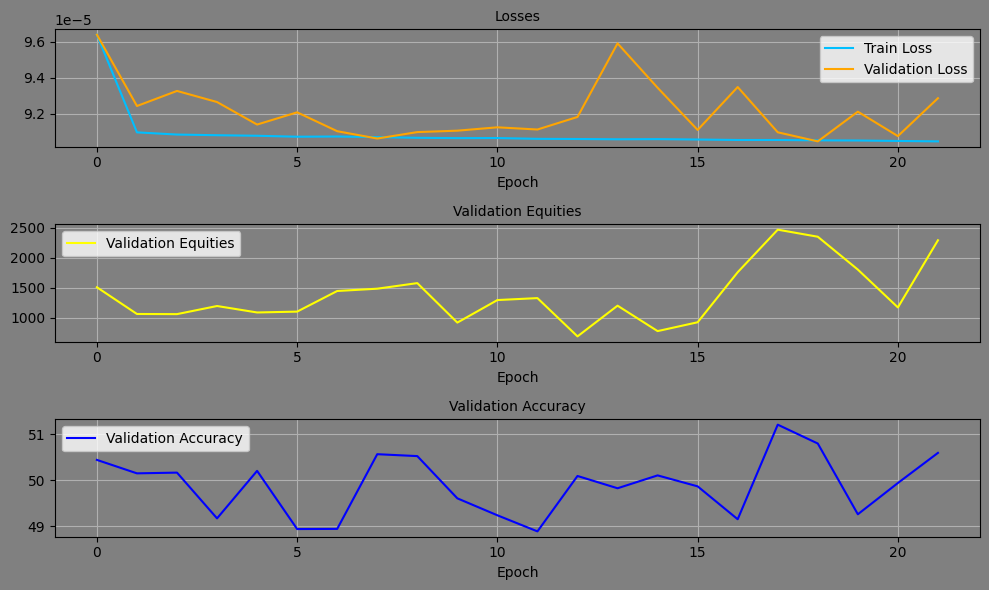

Epoch: 22, Val Equity: 1520.53, Val Accuracy: 49.82 train_losses: 0.0002877070121471439, val_losses: 9.1275927843526e-05, Duration: 0:01:07.713299


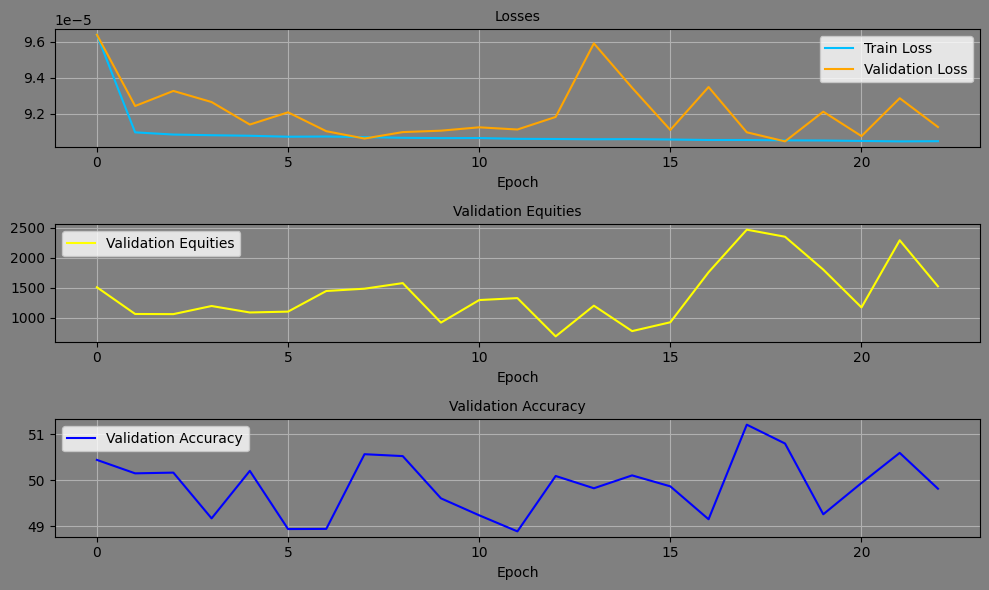

Epoch: 23, Val Equity: 2356.60, Val Accuracy: 50.81 train_losses: 0.0002876340471804791, val_losses: 9.053631220012903e-05, Duration: 0:01:08.433897


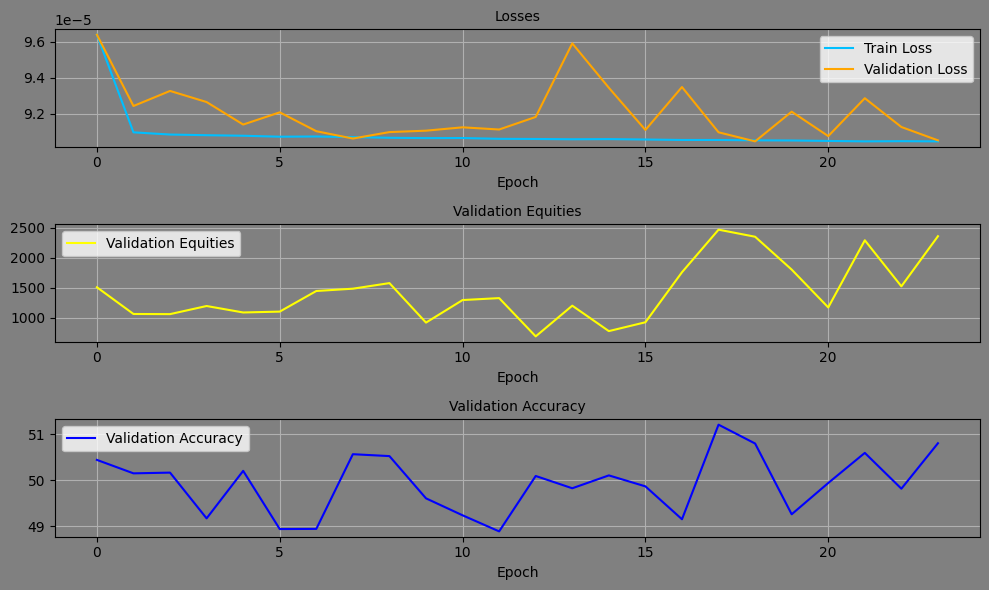

Epoch: 24, Val Equity: 722.88, Val Accuracy: 49.50 train_losses: 0.00028752173762090083, val_losses: 9.092219261219725e-05, Duration: 0:01:08.041828


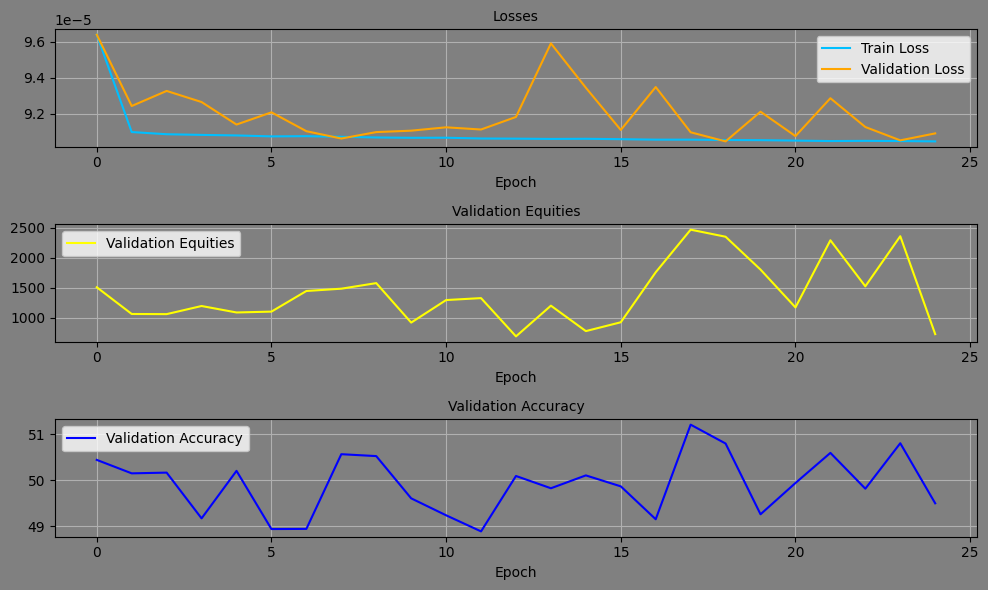

Epoch: 25, Val Equity: 2277.14, Val Accuracy: 49.89 train_losses: 0.0002874680473979883, val_losses: 9.161079651676118e-05, Duration: 0:01:08.084283


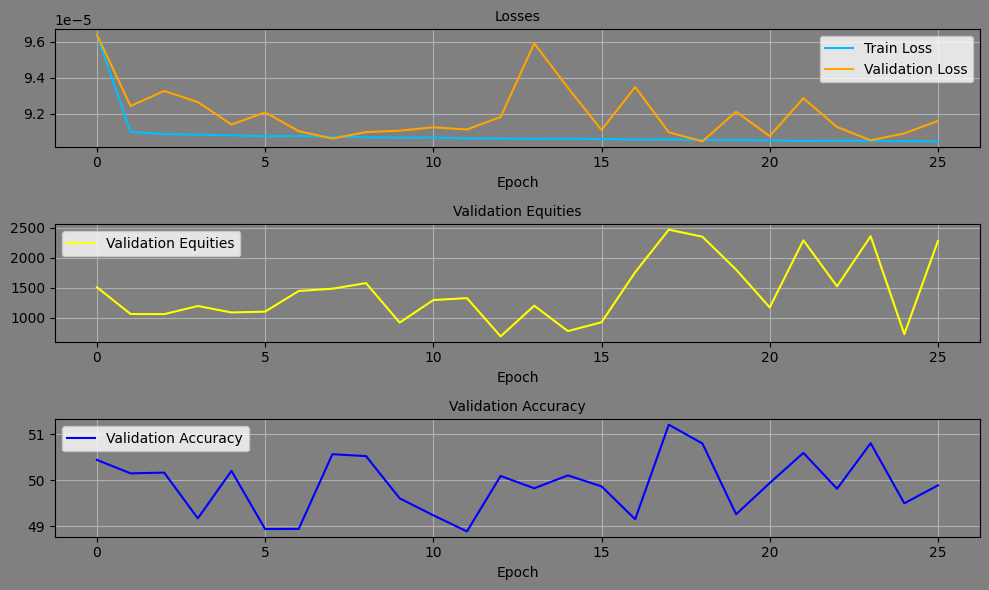

Epoch: 26, Val Equity: 1582.66, Val Accuracy: 49.00 train_losses: 0.0002873681075883968, val_losses: 9.28178196772933e-05, Duration: 0:01:08.325782


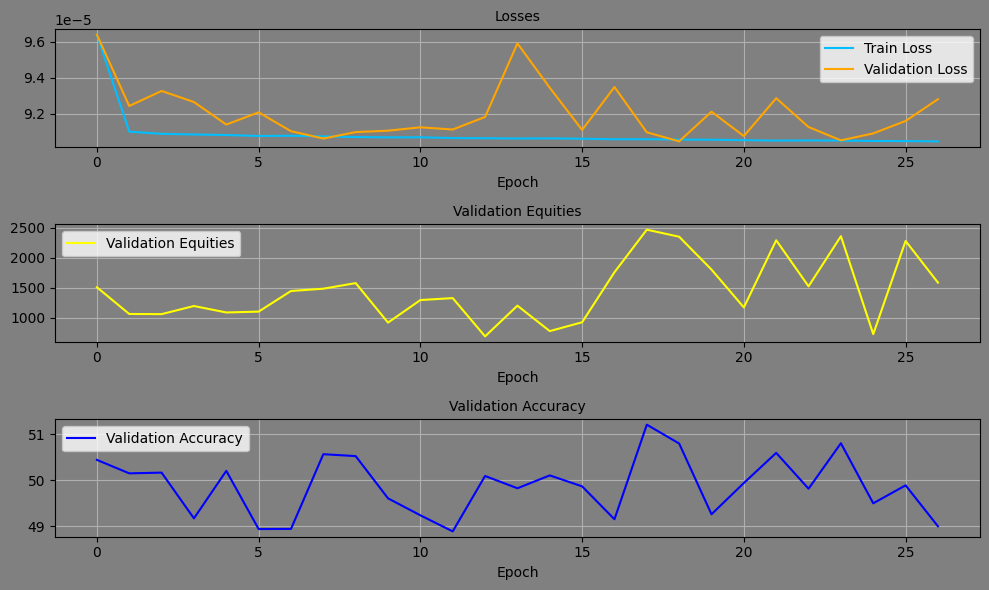

Epoch: 27, Val Equity: 2140.74, Val Accuracy: 49.41 train_losses: 0.0002872615048876306, val_losses: 9.344293357571587e-05, Duration: 0:01:07.792542


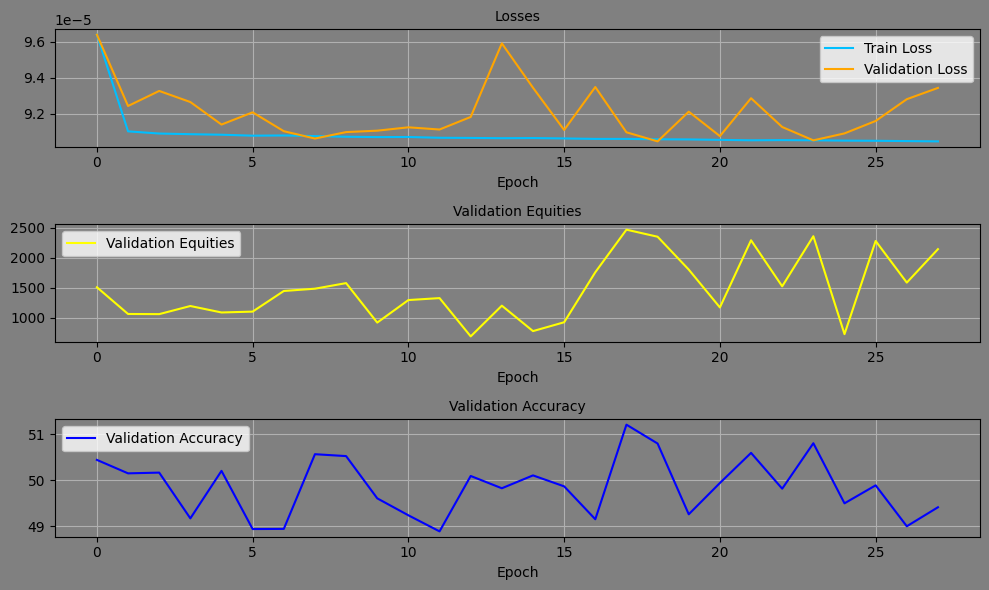

Epoch: 28, Val Equity: 728.42, Val Accuracy: 50.09 train_losses: 0.0002869812877713592, val_losses: 9.079671872314066e-05, Duration: 0:01:08.152398


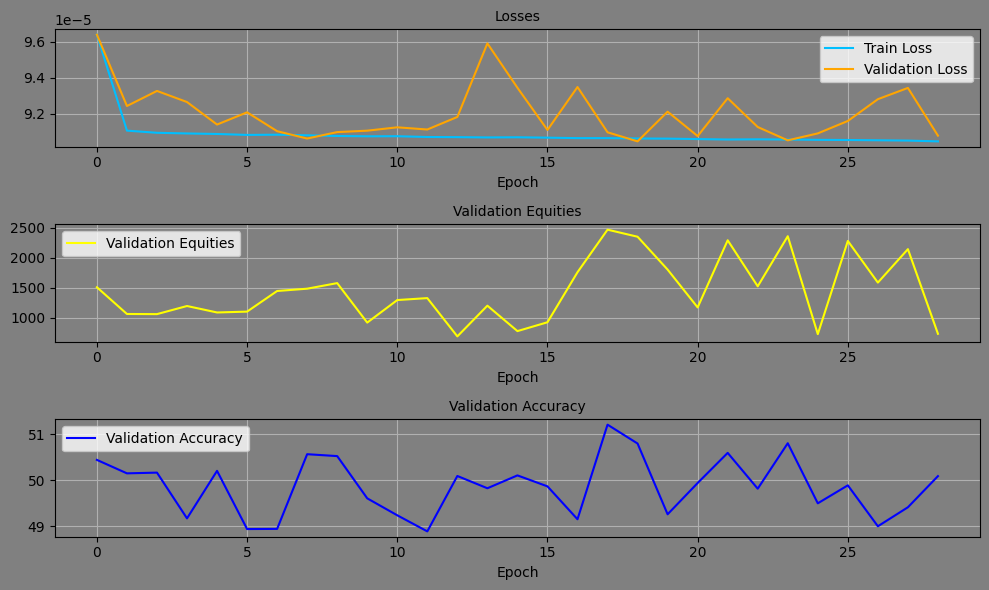

Epoch: 29, Val Equity: 1334.28, Val Accuracy: 50.22 train_losses: 0.00028722638514392843, val_losses: 9.078672883333638e-05, Duration: 0:01:08.159520


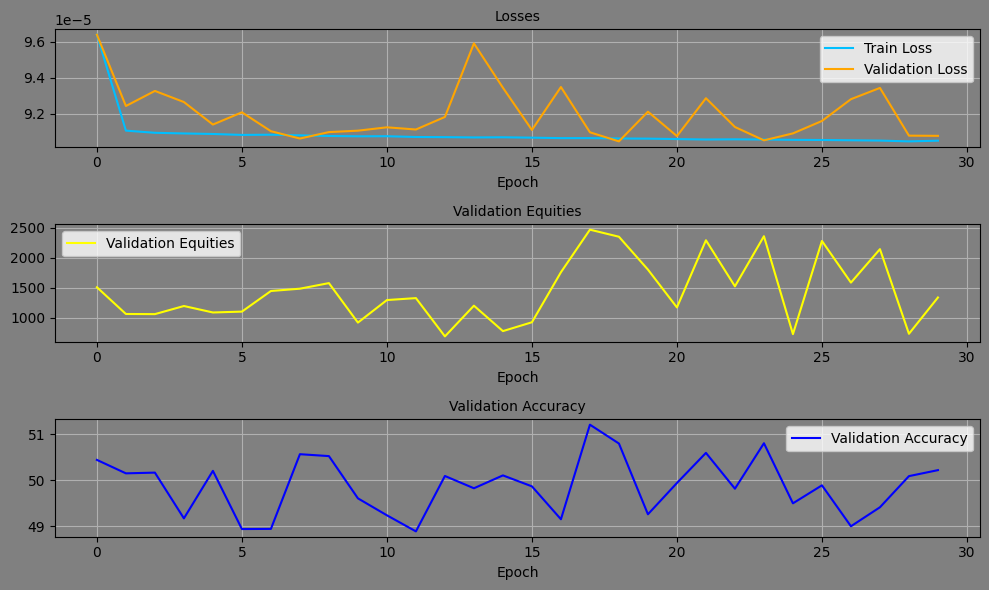

Epoch: 30, Val Equity: 1531.27, Val Accuracy: 50.35 train_losses: 0.0002870885804800605, val_losses: 9.278704965254292e-05, Duration: 0:01:08.237155


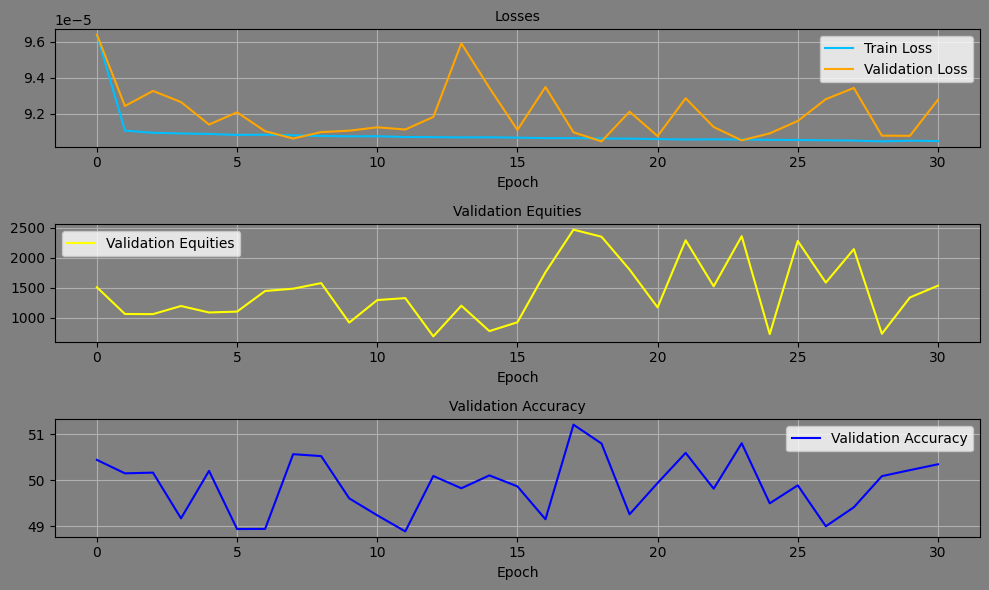

Epoch: 31, Val Equity: 2152.25, Val Accuracy: 49.30 train_losses: 0.00028692093440910193, val_losses: 9.033261449076235e-05, Duration: 0:01:08.037863


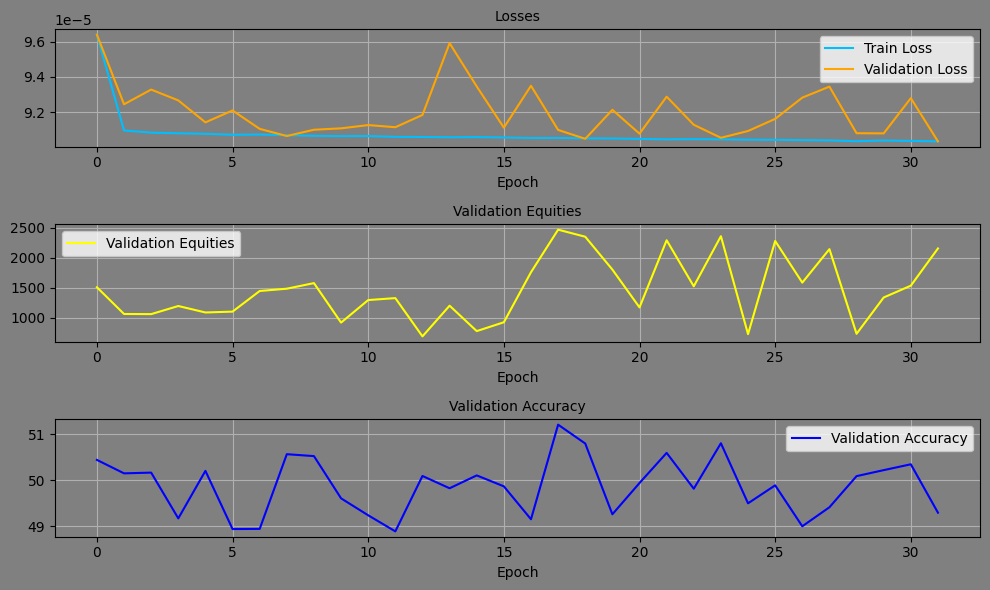

Epoch: 32, Val Equity: 1643.11, Val Accuracy: 50.35 train_losses: 0.0002867741582371664, val_losses: 9.270865120925009e-05, Duration: 0:01:08.176243


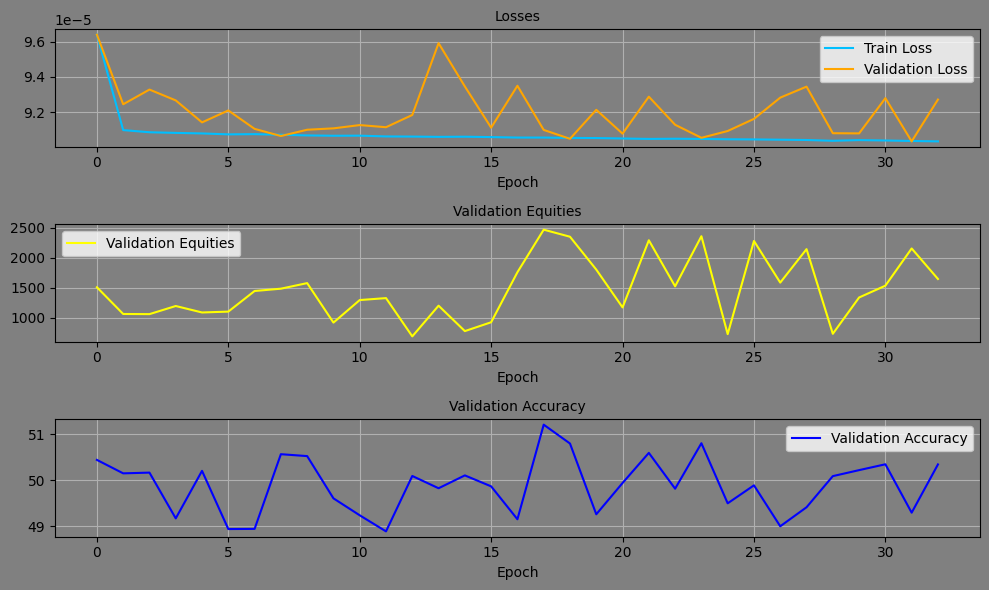

Epoch: 33, Val Equity: 978.59, Val Accuracy: 49.62 train_losses: 0.000286768944413676, val_losses: 9.846372995525599e-05, Duration: 0:01:07.892970


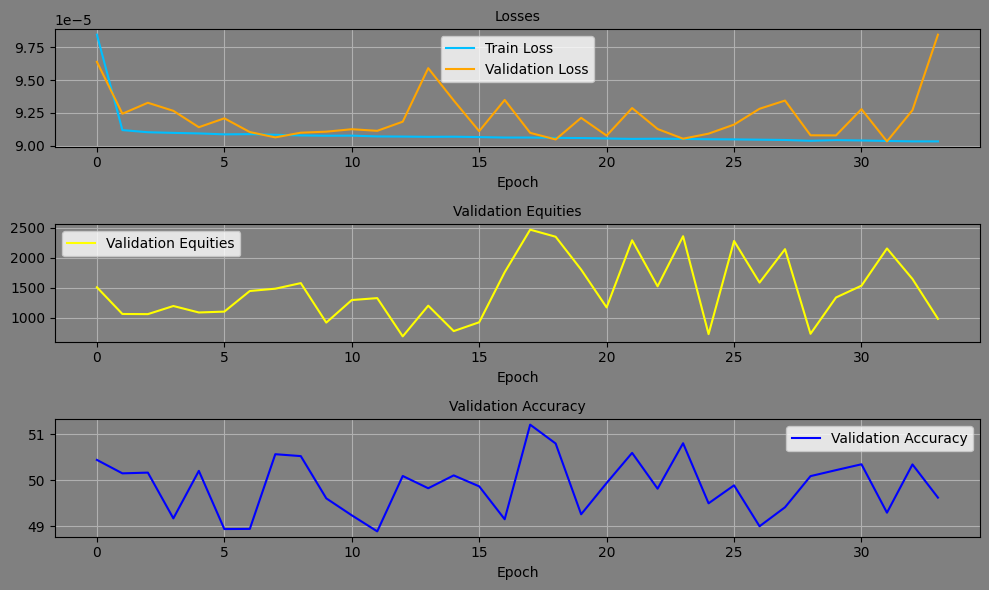

Epoch: 34, Val Equity: 1638.68, Val Accuracy: 48.97 train_losses: 0.0002866679289495994, val_losses: 9.073554974747822e-05, Duration: 0:01:08.167075


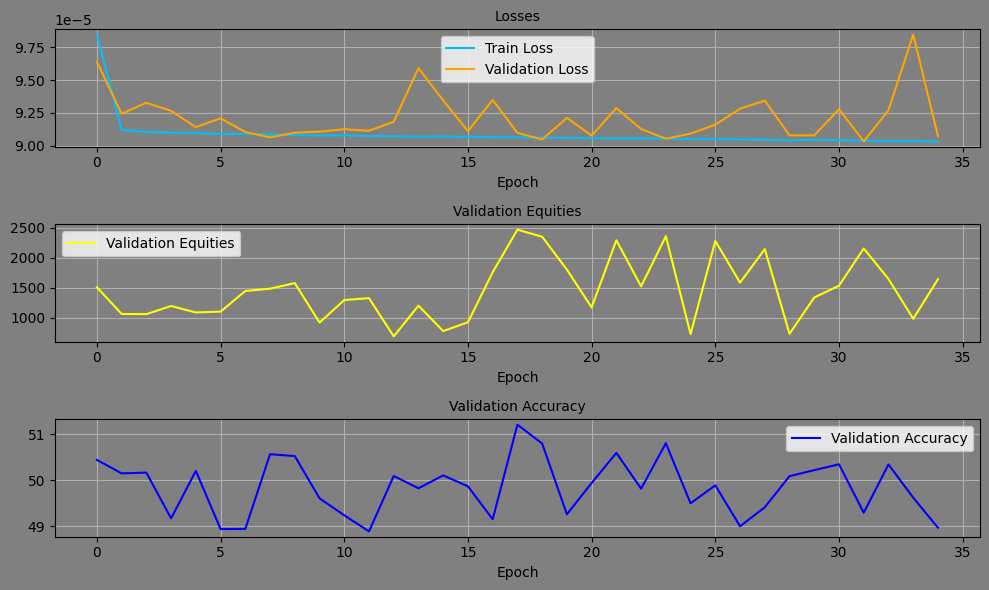

Epoch: 35, Val Equity: 692.80, Val Accuracy: 50.08 train_losses: 0.0002866321638089545, val_losses: 9.266704728361219e-05, Duration: 0:01:07.680636


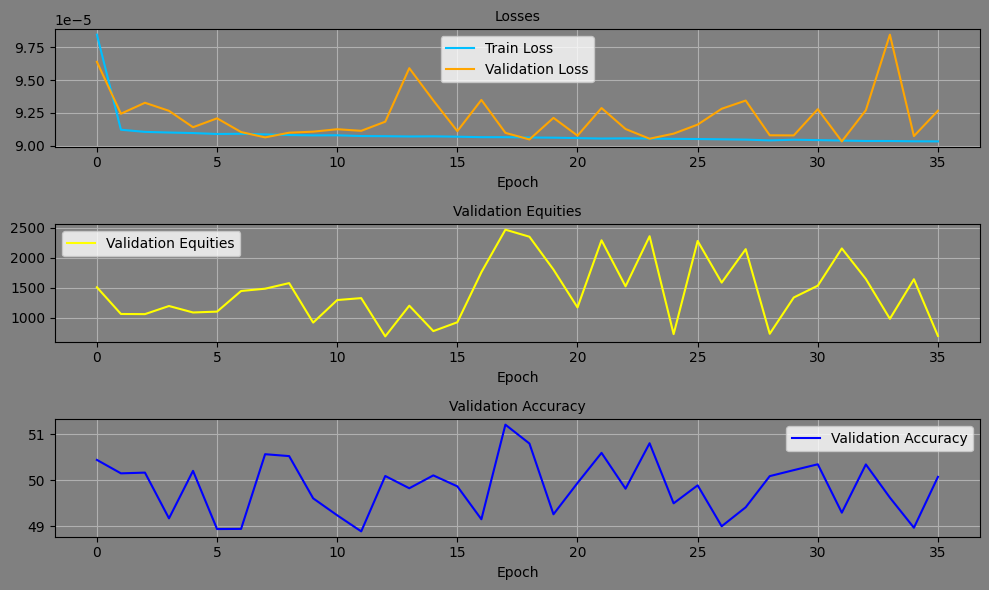

Epoch: 36, Val Equity: 1507.10, Val Accuracy: 49.00 train_losses: 0.0002865574296962459, val_losses: 9.36605574679561e-05, Duration: 0:01:08.111446


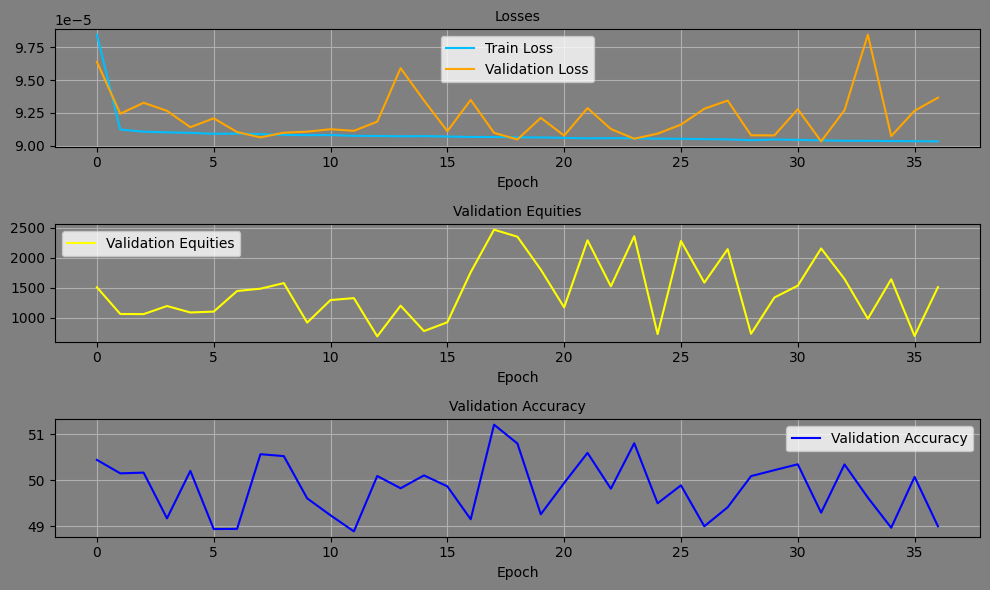

Epoch: 37, Val Equity: 702.07, Val Accuracy: 49.22 train_losses: 0.0002864624381067284, val_losses: 9.06220666365698e-05, Duration: 0:01:08.060910


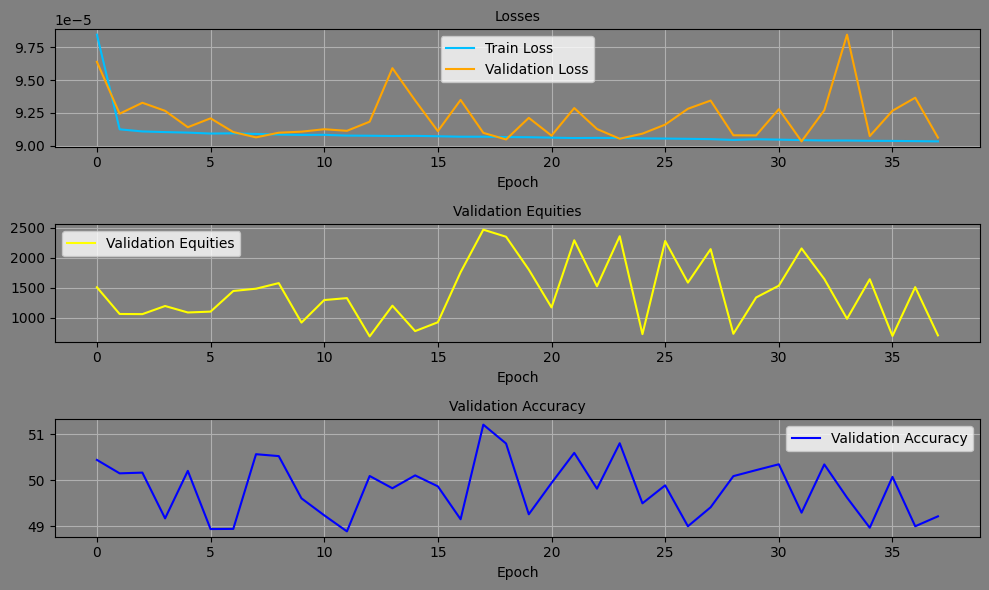

Epoch: 38, Val Equity: 1320.19, Val Accuracy: 49.81 train_losses: 0.0002863846815869219, val_losses: 9.142963244812563e-05, Duration: 0:01:08.104253


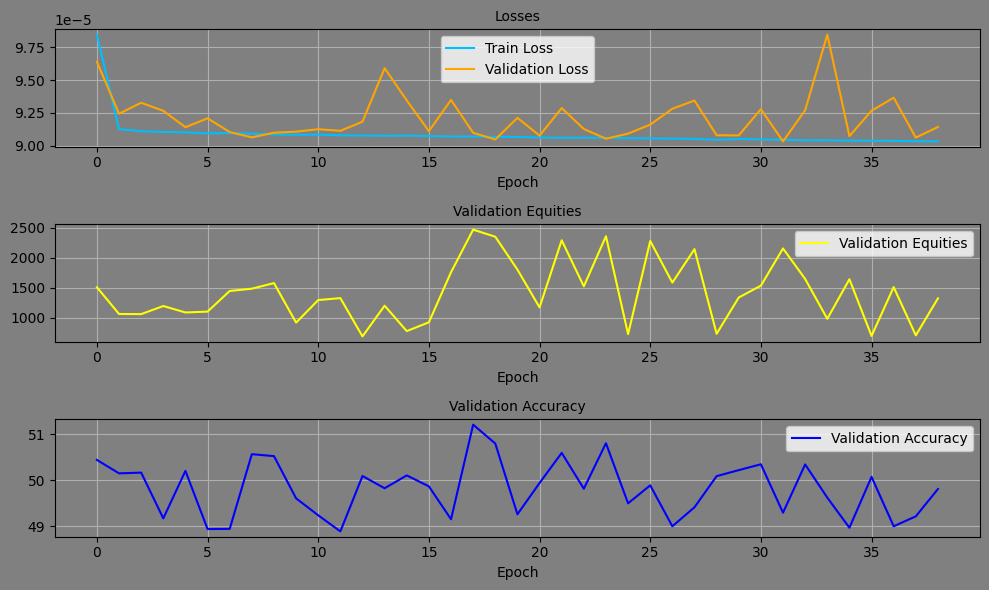

Epoch: 39, Val Equity: 1291.10, Val Accuracy: 49.39 train_losses: 0.000286353783709769, val_losses: 9.276848140871152e-05, Duration: 0:01:07.886387


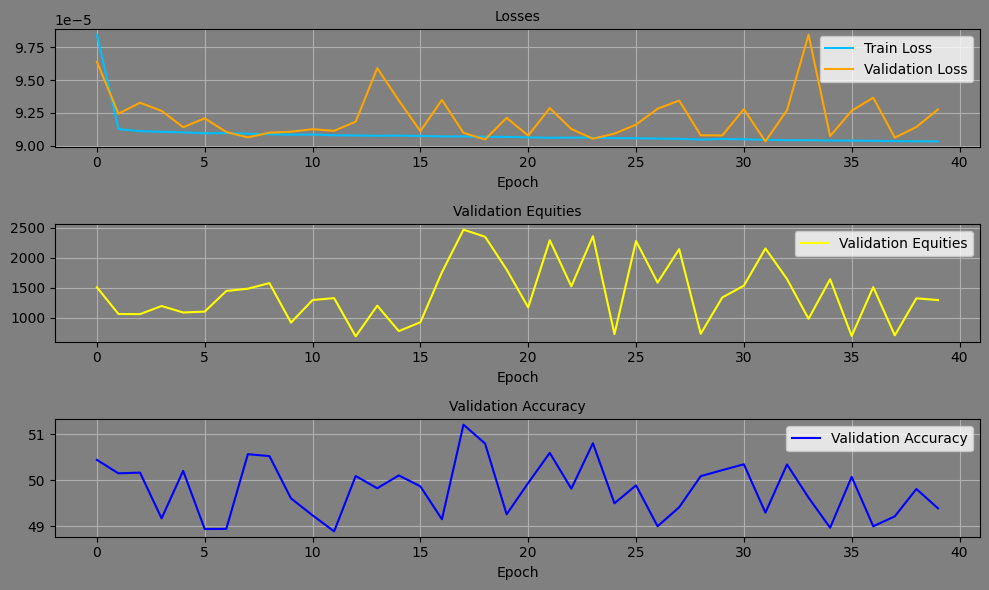

Epoch: 40, Val Equity: 2078.40, Val Accuracy: 49.18 train_losses: 0.0002862505423706345, val_losses: 9.180356573779136e-05, Duration: 0:01:07.952100


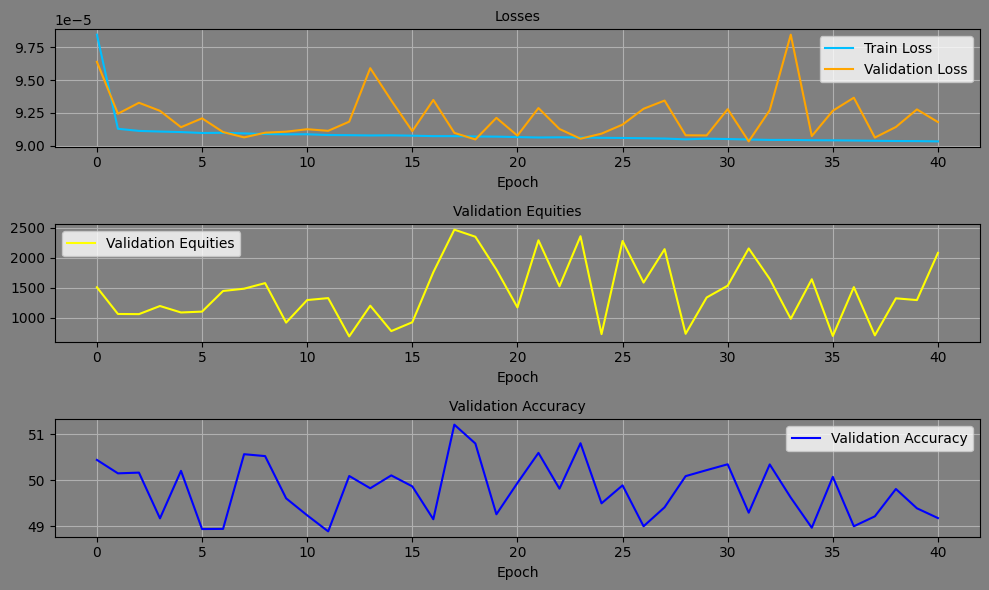

Epoch: 41, Val Equity: 1832.26, Val Accuracy: 49.05 train_losses: 0.0002862559998629137, val_losses: 9.297336509916931e-05, Duration: 0:01:08.651032


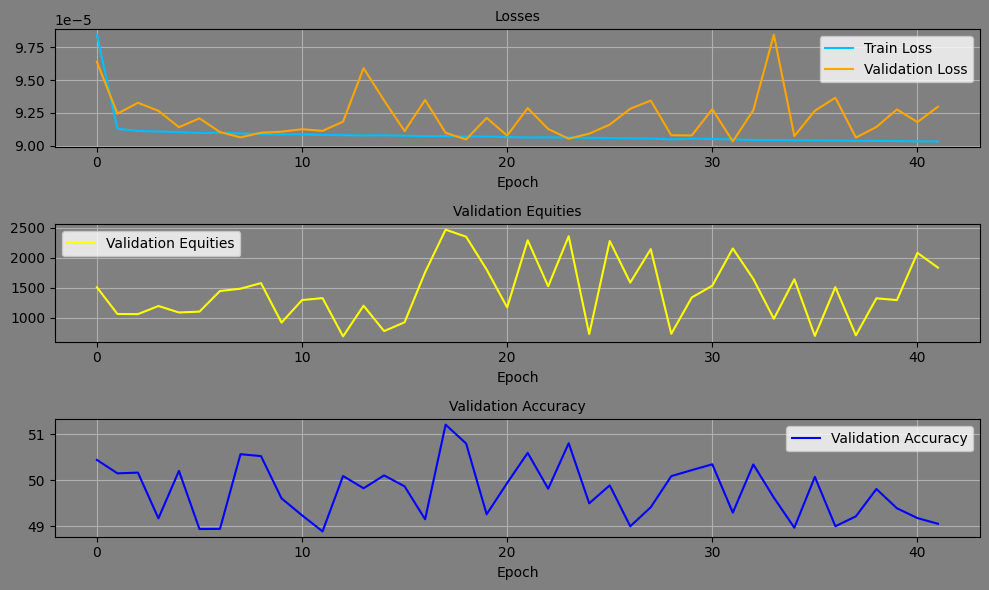

Epoch: 42, Val Equity: 1498.07, Val Accuracy: 48.87 train_losses: 0.00028612778831624074, val_losses: 9.325300197815523e-05, Duration: 0:01:08.331163


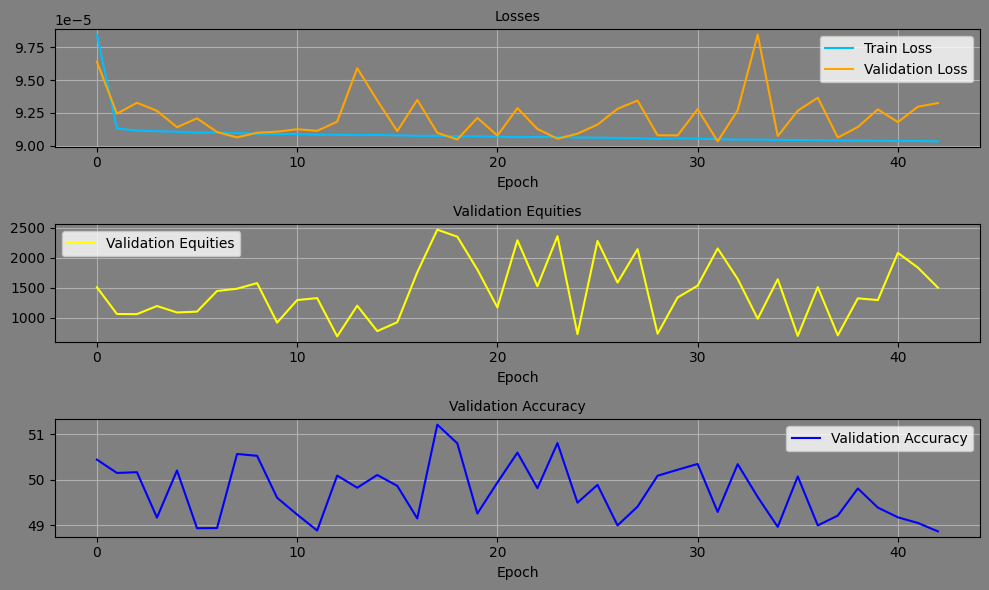

Epoch: 43, Val Equity: 812.29, Val Accuracy: 49.22 train_losses: 0.00028607949466656163, val_losses: 9.370564657729119e-05, Duration: 0:01:07.983360


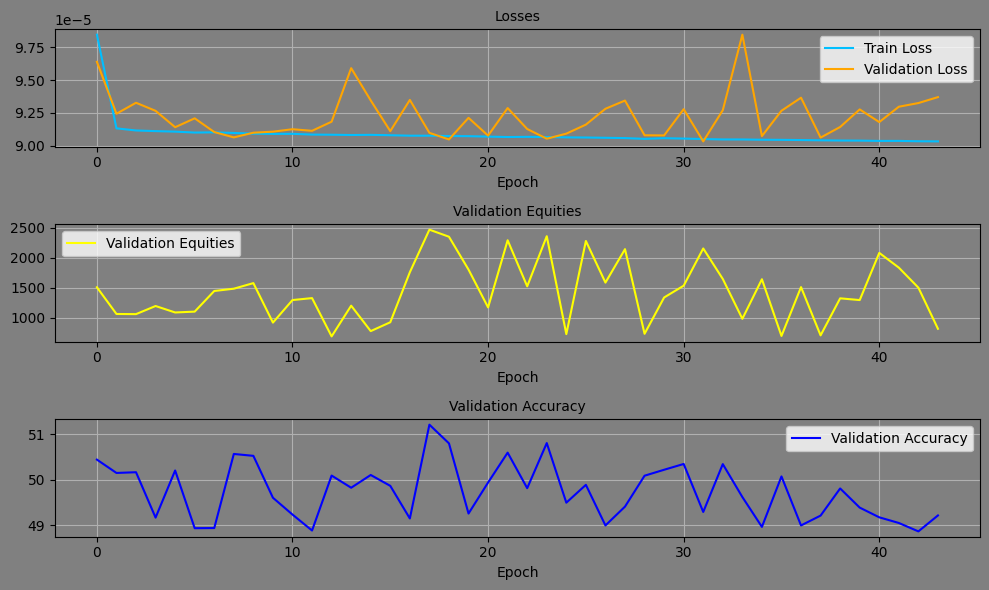

Epoch: 44, Val Equity: 2006.84, Val Accuracy: 48.93 train_losses: 0.0002860282063147124, val_losses: 9.086528734769672e-05, Duration: 0:01:08.207882


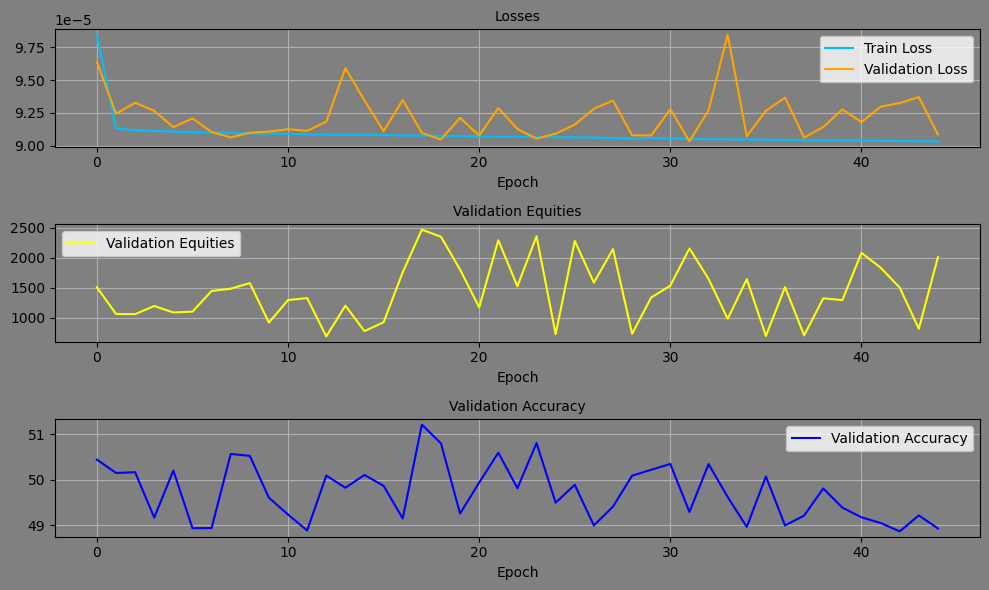

Epoch: 45, Val Equity: 880.62, Val Accuracy: 49.18 train_losses: 0.0002860071709759227, val_losses: 9.077049617189914e-05, Duration: 0:01:08.327654


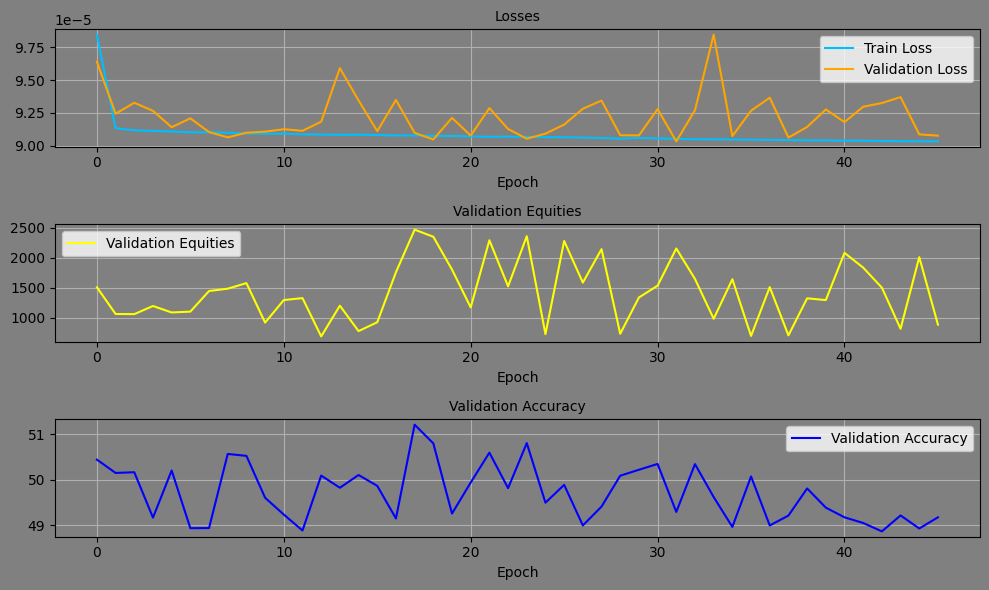

Epoch: 46, Val Equity: 1021.25, Val Accuracy: 49.47 train_losses: 0.0002859887021133353, val_losses: 9.049687650986016e-05, Duration: 0:01:07.871287


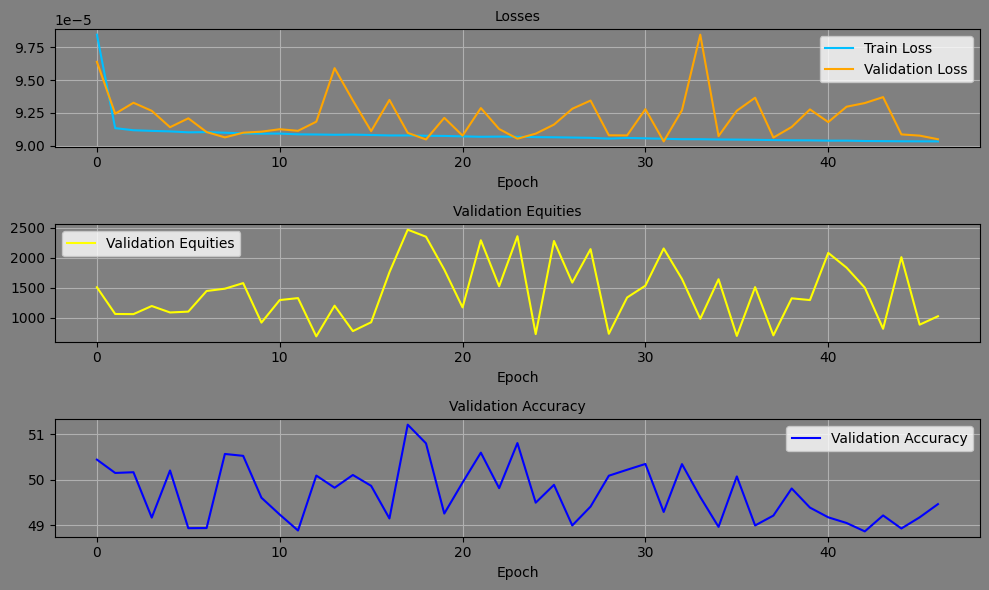

Epoch: 47, Val Equity: 1048.47, Val Accuracy: 50.11 train_losses: 0.00028586496381052253, val_losses: 9.109883103519678e-05, Duration: 0:01:07.757410


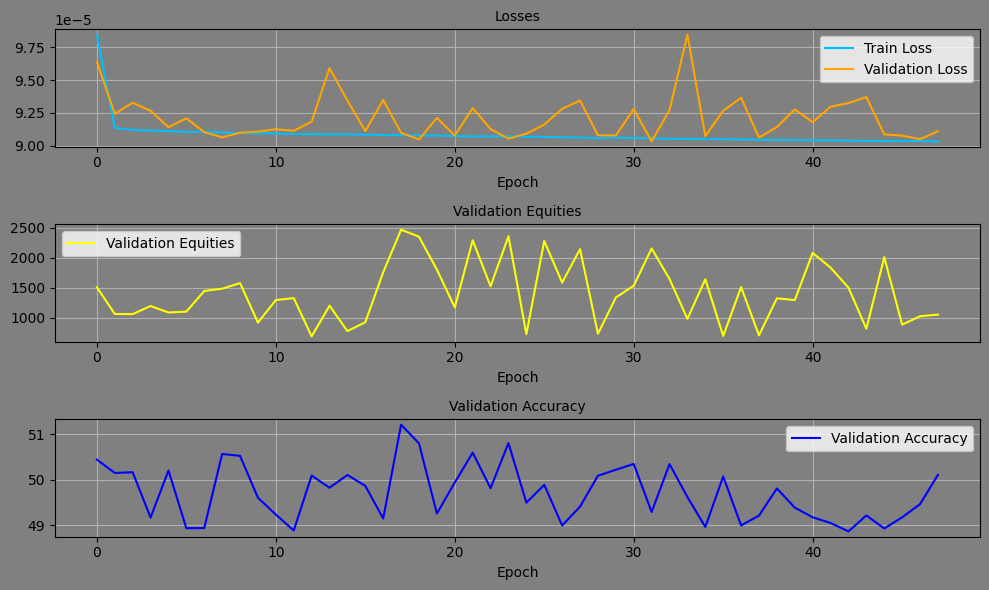

Epoch: 48, Val Equity: 1727.93, Val Accuracy: 49.01 train_losses: 0.00028594670999752, val_losses: 9.120481263380498e-05, Duration: 0:01:07.931780


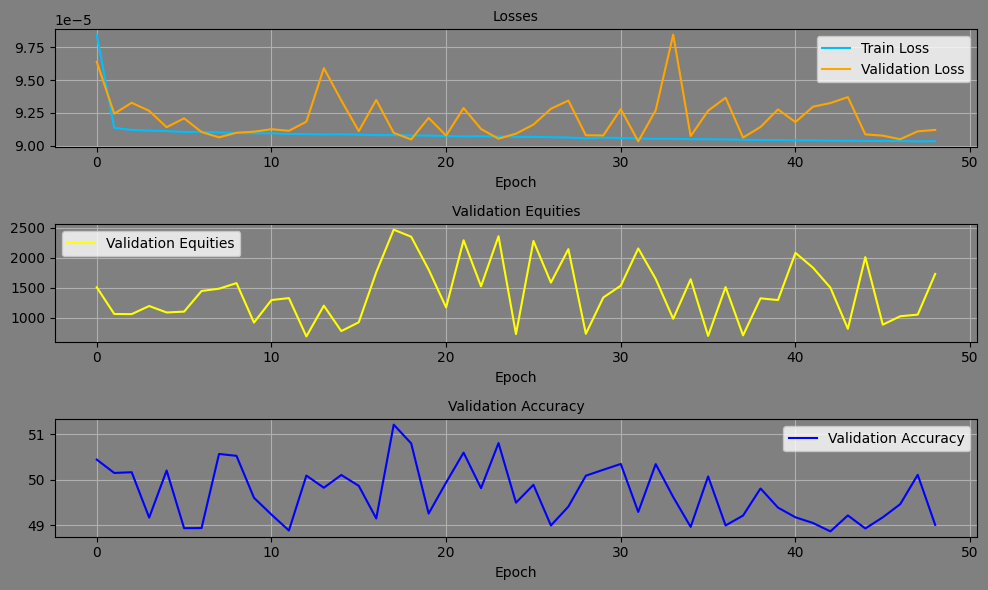

Epoch: 49, Val Equity: 2011.63, Val Accuracy: 50.57 train_losses: 0.0002857649805055485, val_losses: 9.013285307446495e-05, Duration: 0:01:08.230696


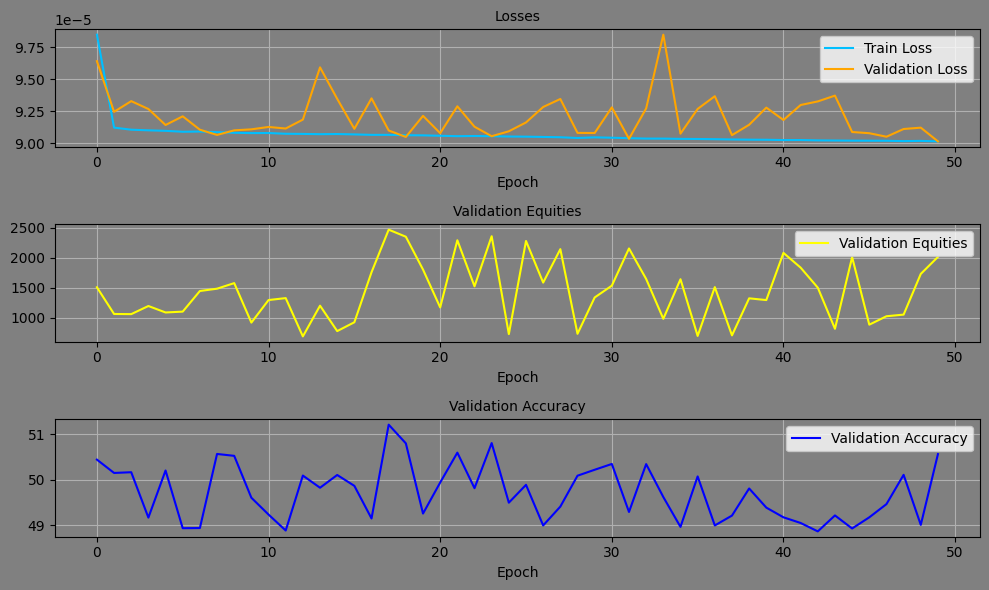

Epoch: 50, Val Equity: 1624.42, Val Accuracy: 50.47 train_losses: 0.00028574194358889956, val_losses: 9.09714653971605e-05, Duration: 0:01:07.940447


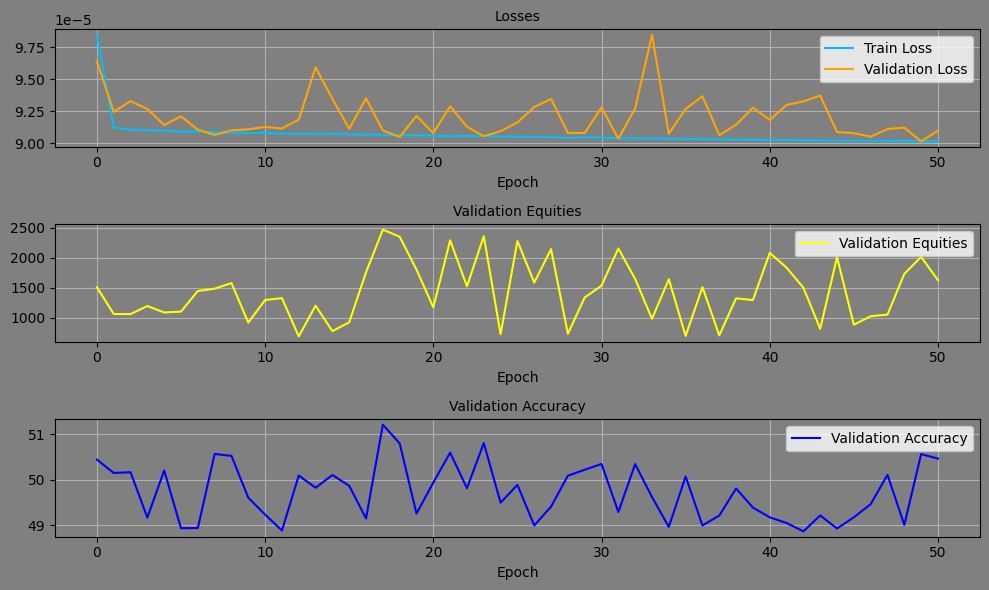

Epoch: 51, Val Equity: 1255.91, Val Accuracy: 49.72 train_losses: 0.0002857118155569568, val_losses: 9.325361315859482e-05, Duration: 0:01:08.064315


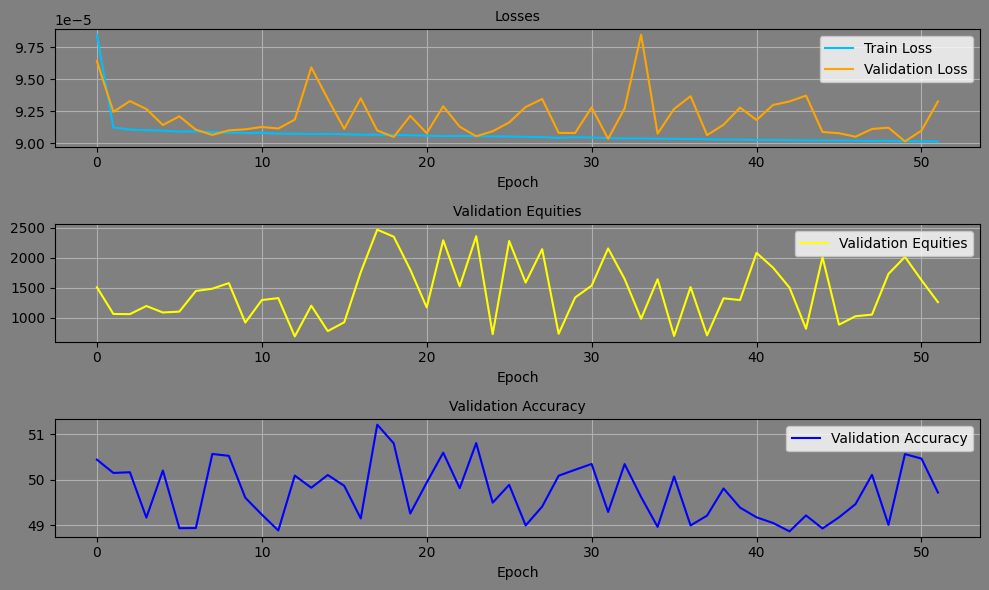

Epoch: 52, Val Equity: 1509.39, Val Accuracy: 50.19 train_losses: 0.0002856221666392474, val_losses: 9.165165829472244e-05, Duration: 0:01:08.666894


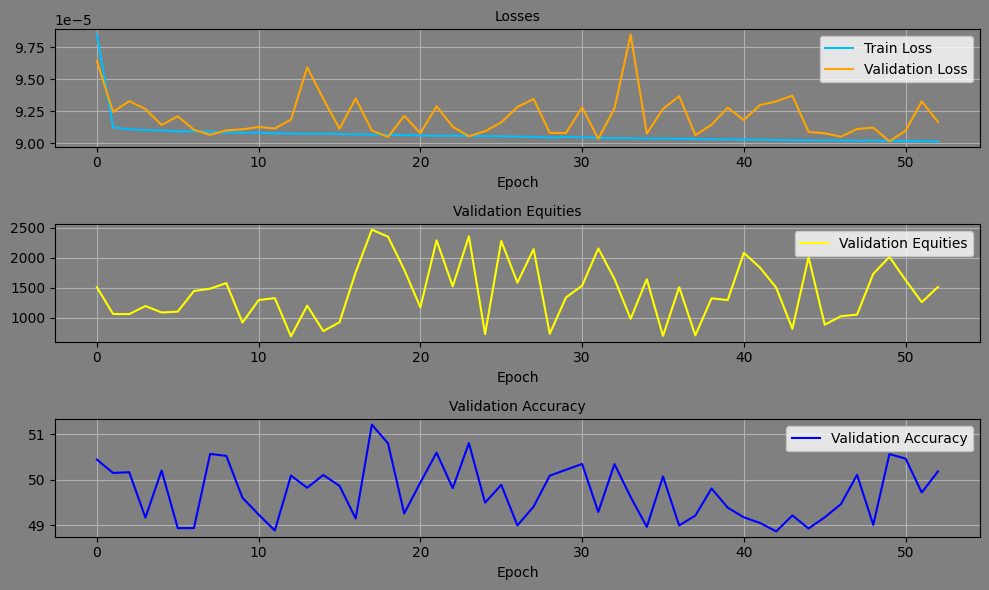

Epoch: 53, Val Equity: 1048.48, Val Accuracy: 49.25 train_losses: 0.0002855197052264803, val_losses: 9.394101653015241e-05, Duration: 0:01:07.858391


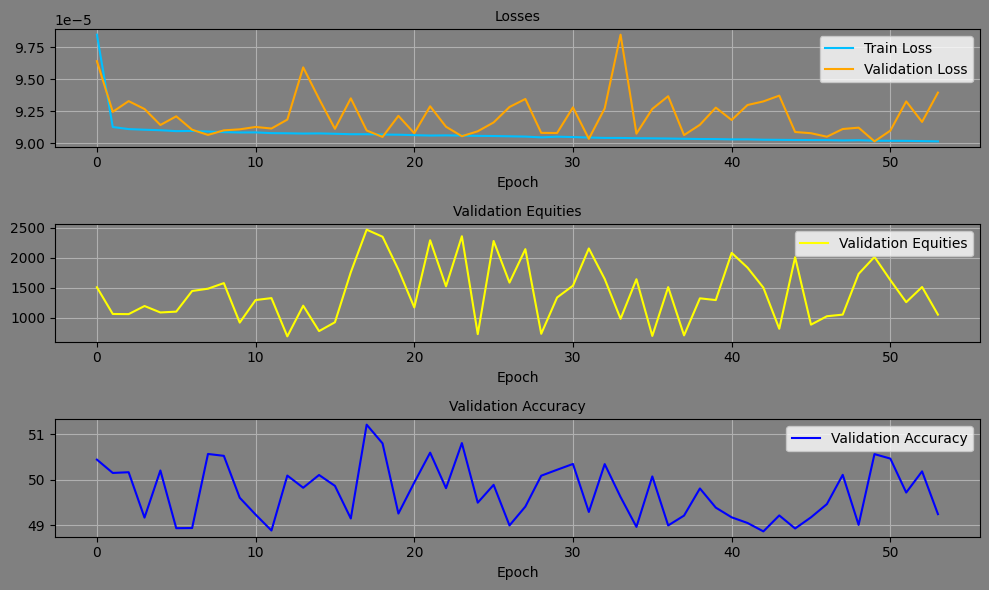

Epoch: 54, Val Equity: 1674.08, Val Accuracy: 49.02 train_losses: 0.00028552796657354114, val_losses: 9.260366641683504e-05, Duration: 0:01:08.764668


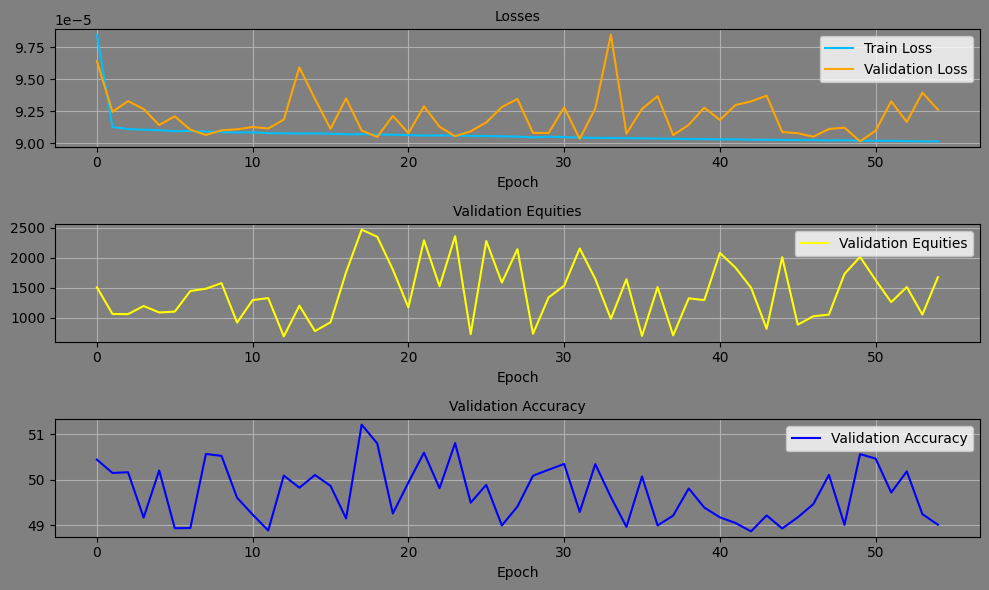

Epoch: 55, Val Equity: 1333.67, Val Accuracy: 50.35 train_losses: 0.0002854423477920709, val_losses: 9.19222948141396e-05, Duration: 0:01:08.283268


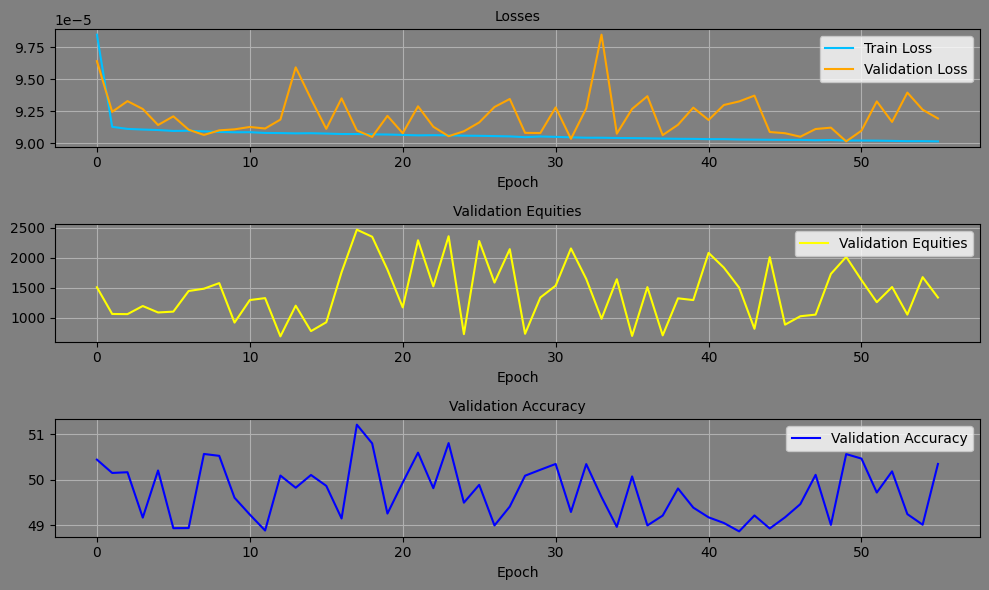

Epoch: 56, Val Equity: 2589.52, Val Accuracy: 49.56 train_losses: 0.0002855223435869625, val_losses: 9.147764649242163e-05, Duration: 0:01:08.139492


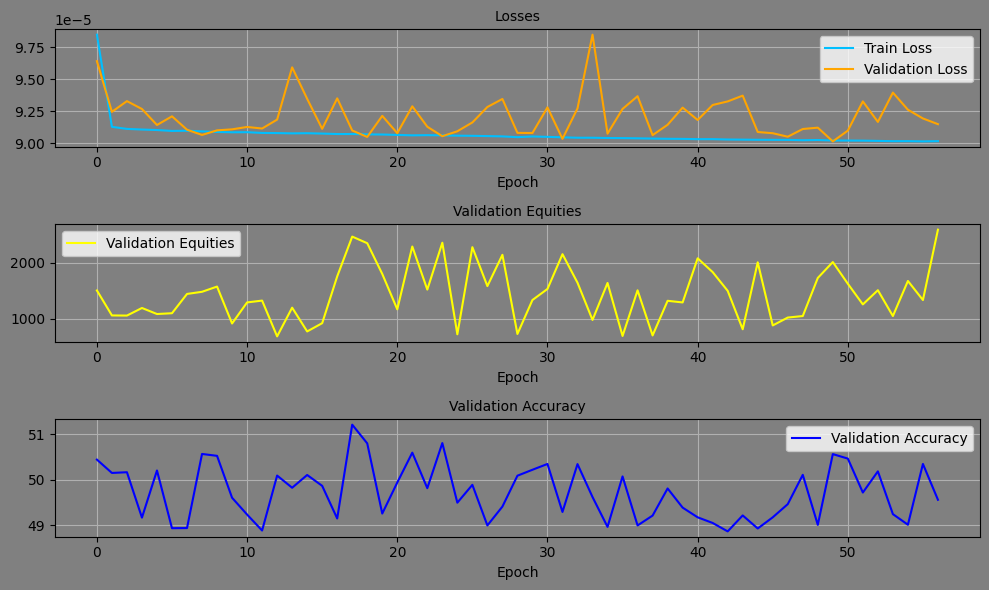

Epoch: 57, Val Equity: 1324.35, Val Accuracy: 48.65 train_losses: 0.00028541791033468713, val_losses: 9.05759516172111e-05, Duration: 0:01:08.059006


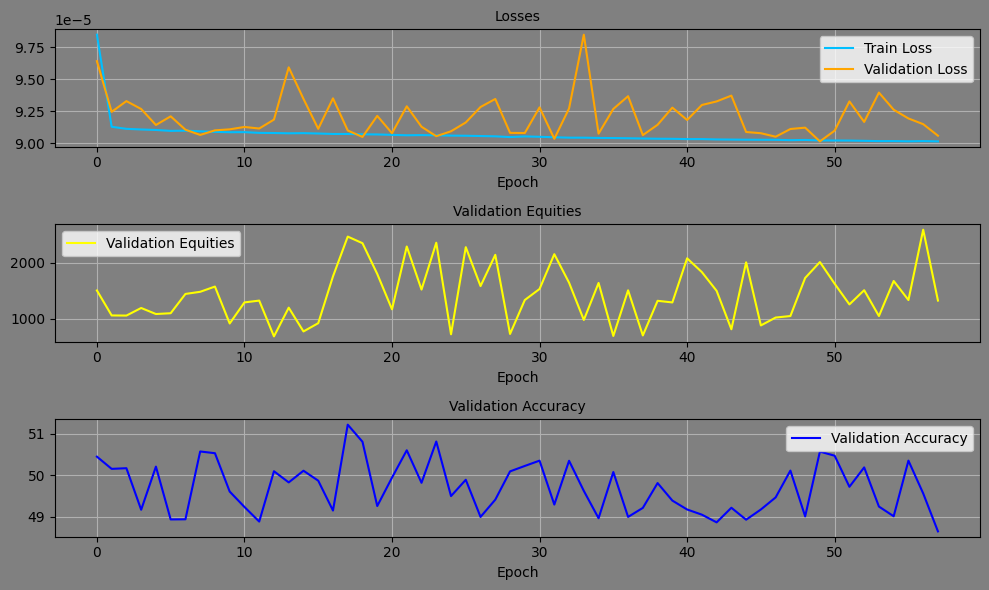

Epoch: 58, Val Equity: 2219.30, Val Accuracy: 49.12 train_losses: 0.00028535600590269653, val_losses: 9.27121946006082e-05, Duration: 0:01:08.048293


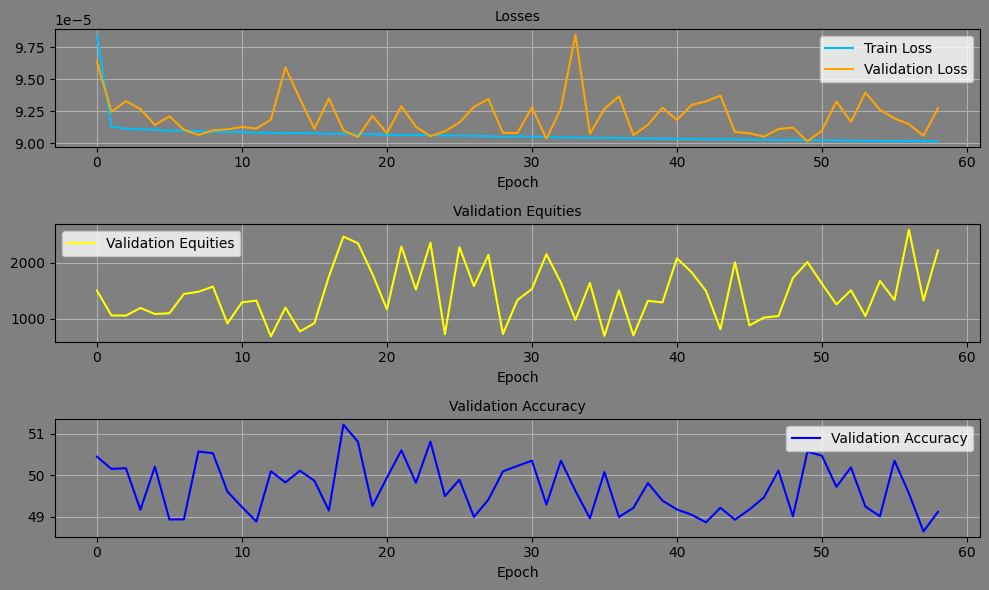

Epoch: 59, Val Equity: 996.36, Val Accuracy: 49.62 train_losses: 0.0002852788918803563, val_losses: 9.065672929864377e-05, Duration: 0:01:08.972680


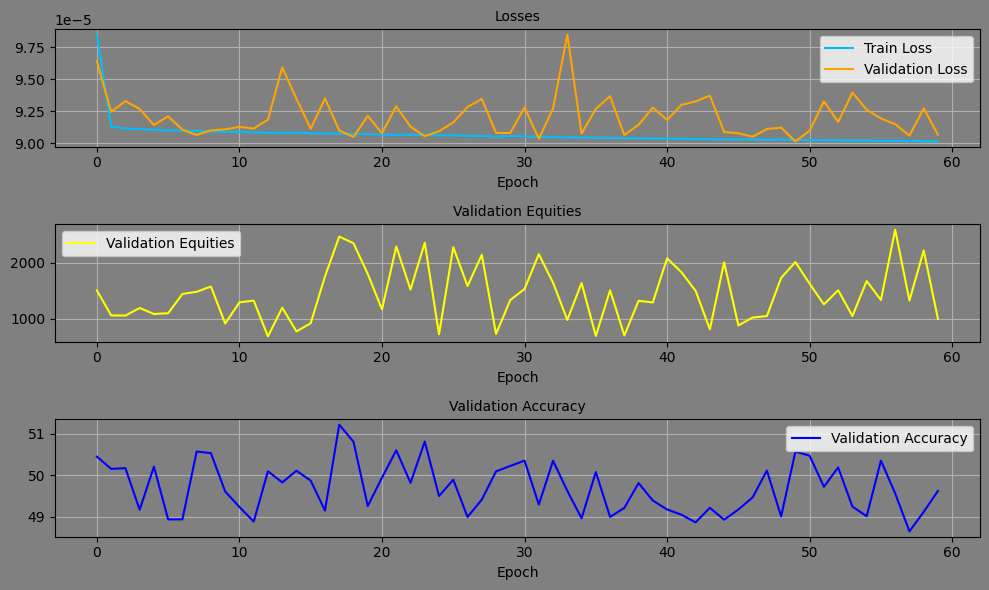

Epoch: 60, Val Equity: 1709.56, Val Accuracy: 50.05 train_losses: 0.0002852736459726842, val_losses: 9.012148802867159e-05, Duration: 0:01:08.152552


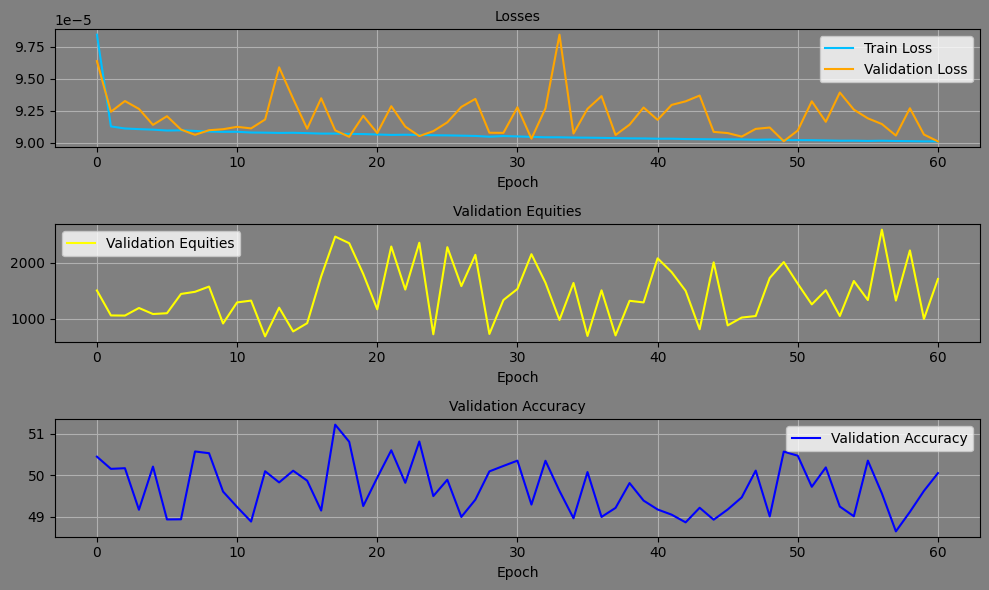

Epoch: 61, Val Equity: 1422.39, Val Accuracy: 50.29 train_losses: 0.00028532291967592284, val_losses: 9.190901619149372e-05, Duration: 0:01:07.851717


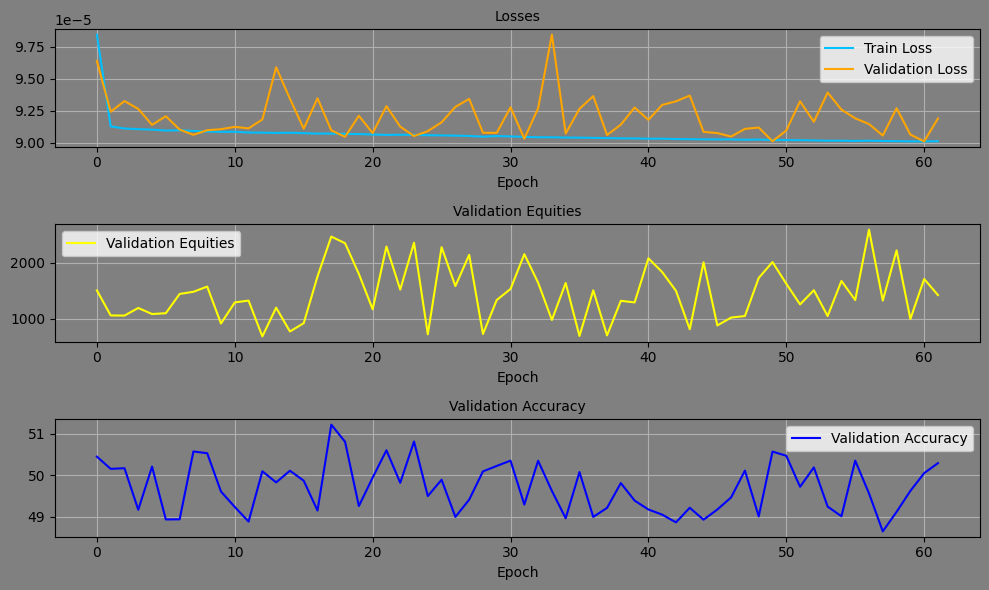

Epoch: 62, Val Equity: 2109.77, Val Accuracy: 48.96 train_losses: 0.00028525024121441543, val_losses: 9.193464939016849e-05, Duration: 0:01:08.098516


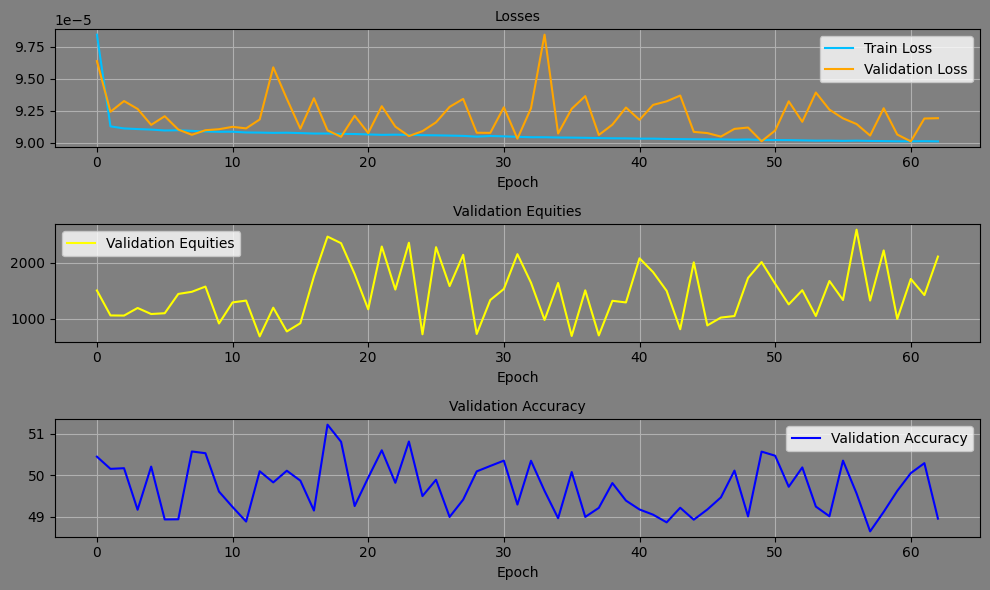

Epoch: 63, Val Equity: 1504.42, Val Accuracy: 50.60 train_losses: 0.0002850720739188065, val_losses: 9.109215898206457e-05, Duration: 0:01:08.575056


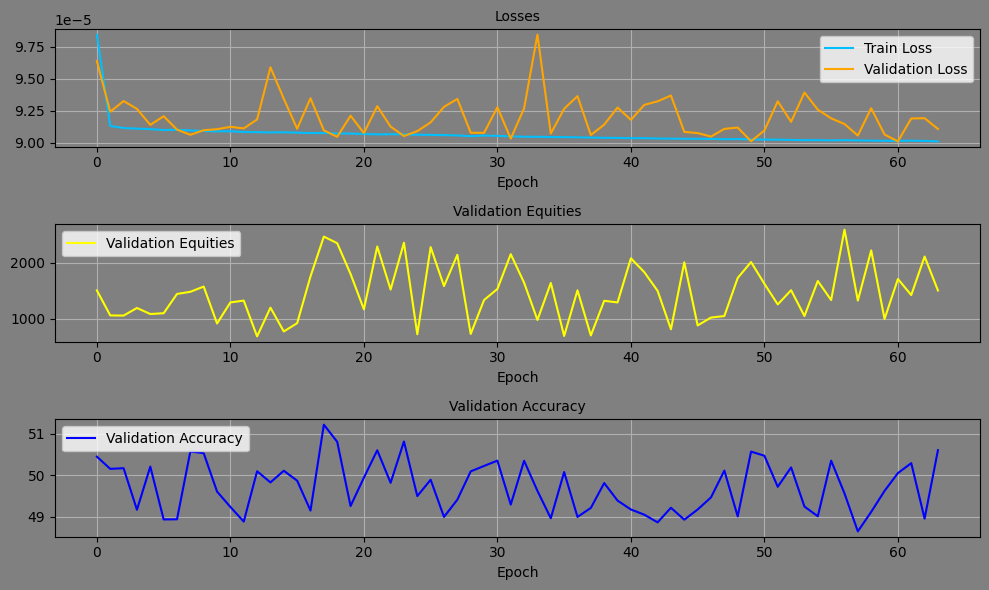

Epoch: 64, Val Equity: 1831.41, Val Accuracy: 50.36 train_losses: 0.0002850010515713598, val_losses: 9.184328519040719e-05, Duration: 0:01:07.947848


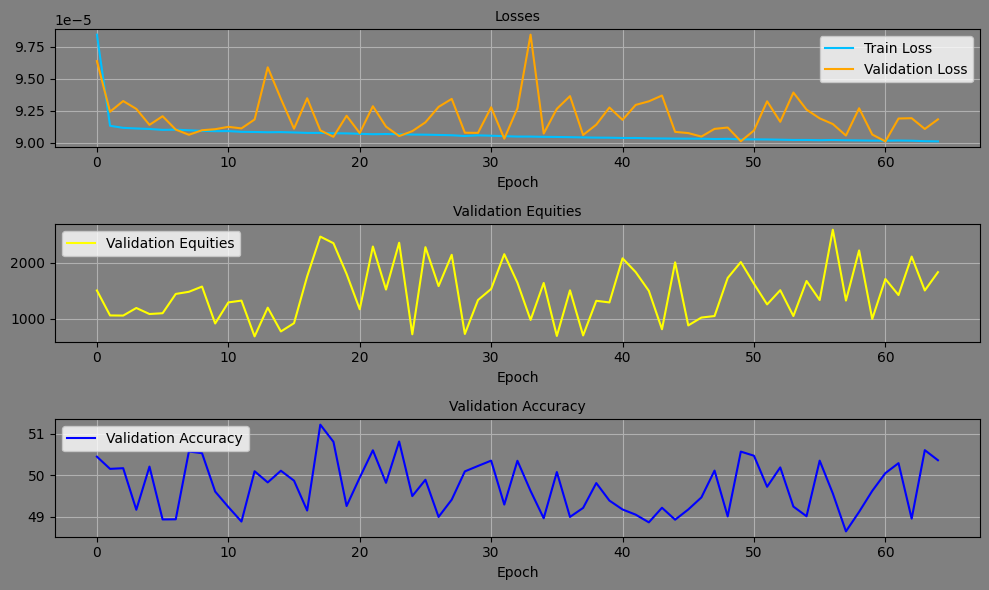

Epoch: 65, Val Equity: 2198.64, Val Accuracy: 49.17 train_losses: 0.0002849957924113147, val_losses: 9.129073441727087e-05, Duration: 0:01:08.157049


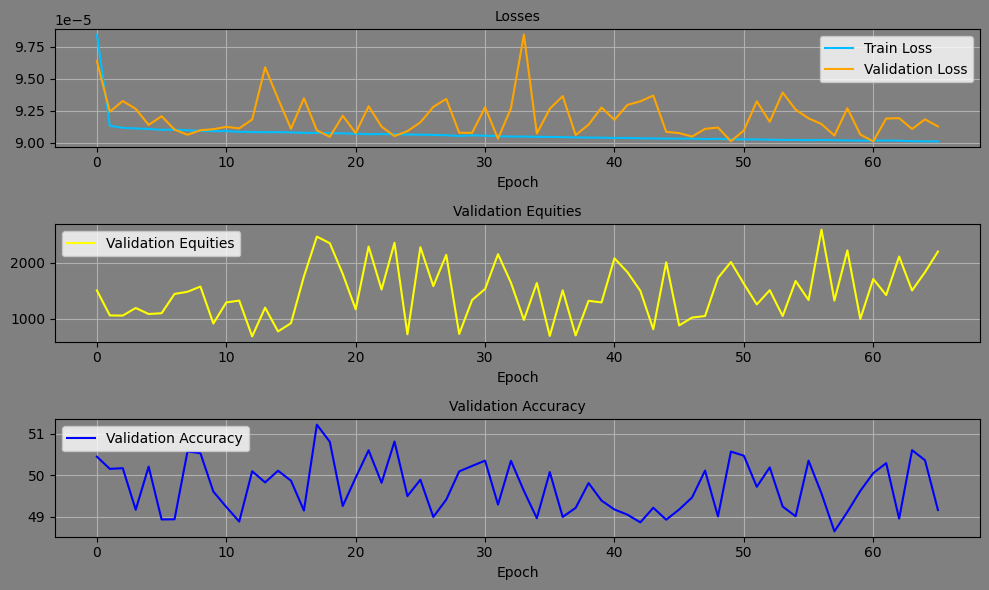

Epoch: 66, Val Equity: 1587.09, Val Accuracy: 48.74 train_losses: 0.0002849157533075147, val_losses: 9.591947309672832e-05, Duration: 0:01:07.914152


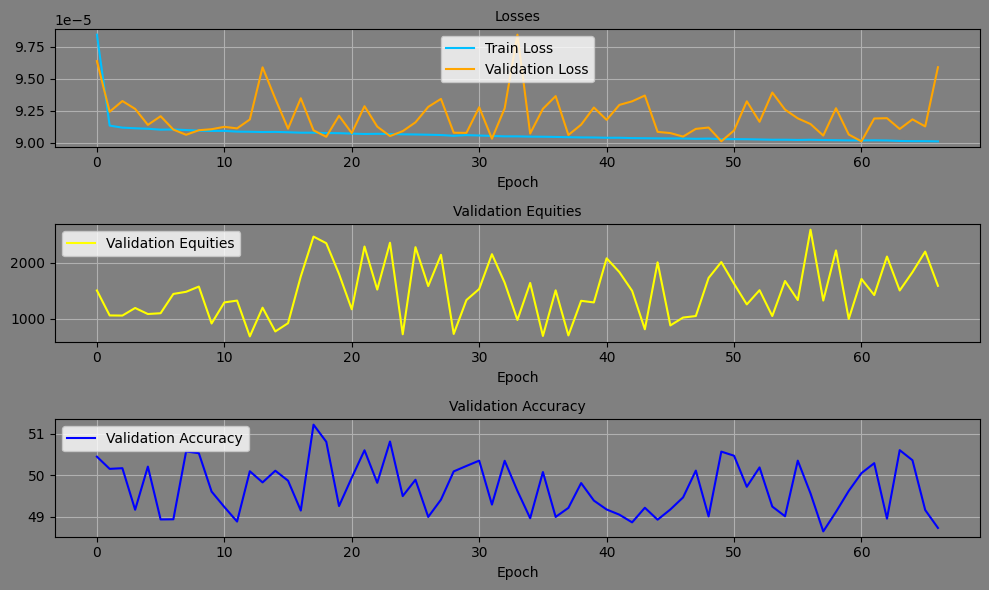

Epoch: 67, Val Equity: 692.72, Val Accuracy: 48.36 train_losses: 0.0002849545070204833, val_losses: 9.231726289726794e-05, Duration: 0:01:07.893037


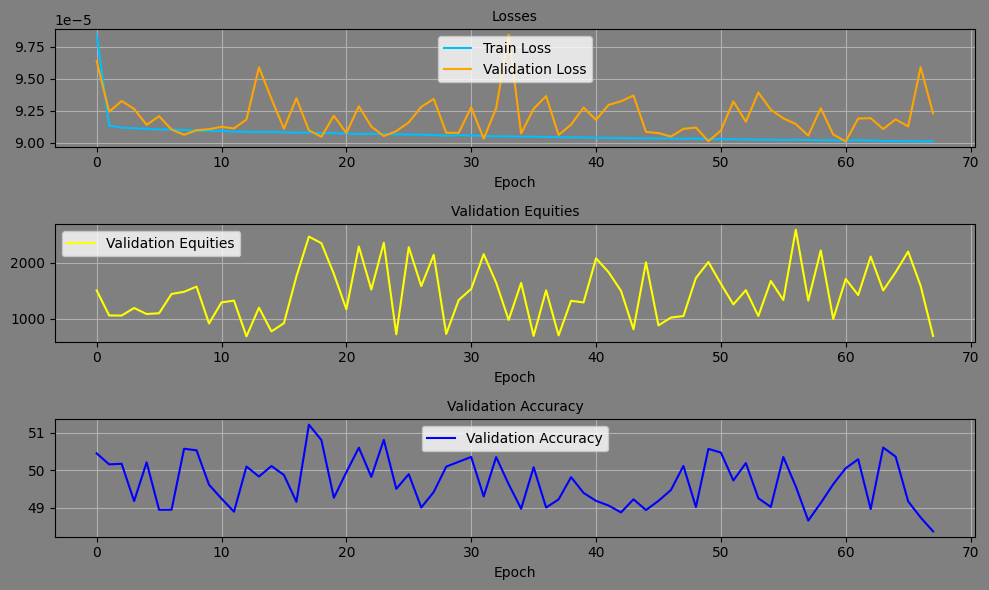

Epoch: 68, Val Equity: 2621.69, Val Accuracy: 49.93 train_losses: 0.00028488717428923723, val_losses: 9.109629900194705e-05, Duration: 0:01:08.179406


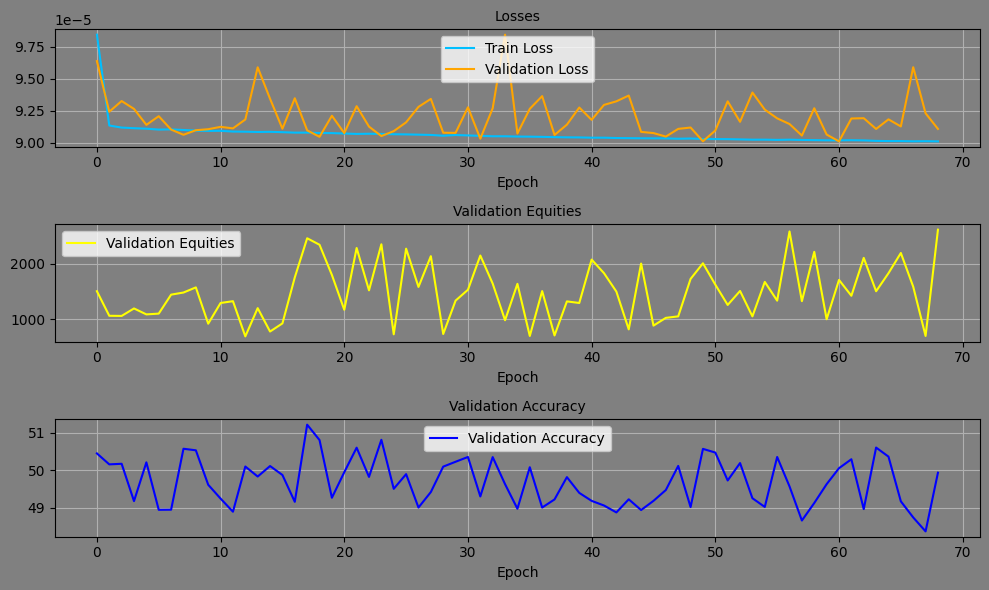

Epoch: 69, Val Equity: 2263.42, Val Accuracy: 49.11 train_losses: 0.00028492484814870197, val_losses: 9.17263823794201e-05, Duration: 0:01:08.066509


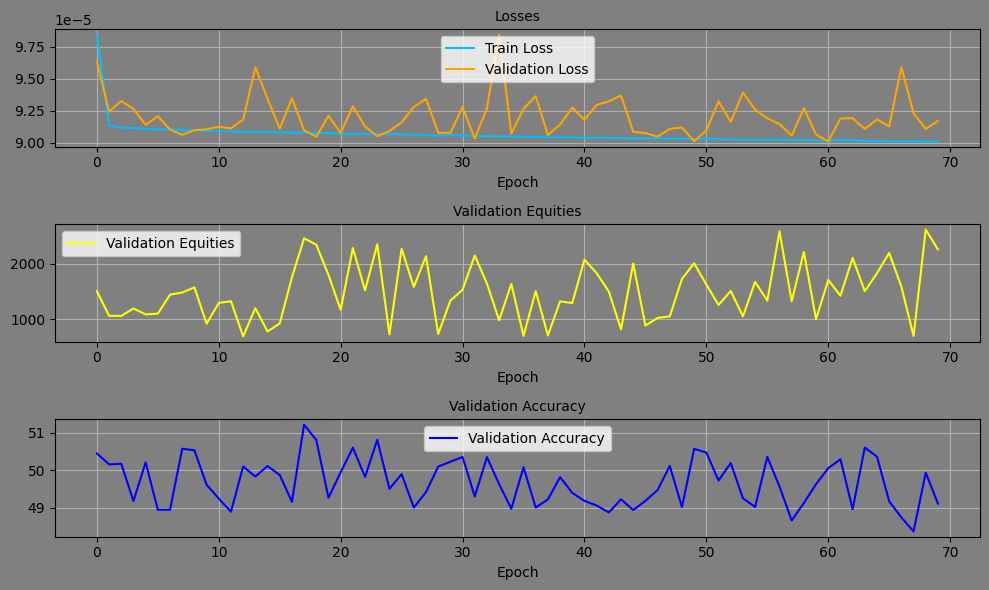

Epoch: 70, Val Equity: 954.47, Val Accuracy: 48.95 train_losses: 0.0002848483331783568, val_losses: 9.220650827046484e-05, Duration: 0:01:08.054082


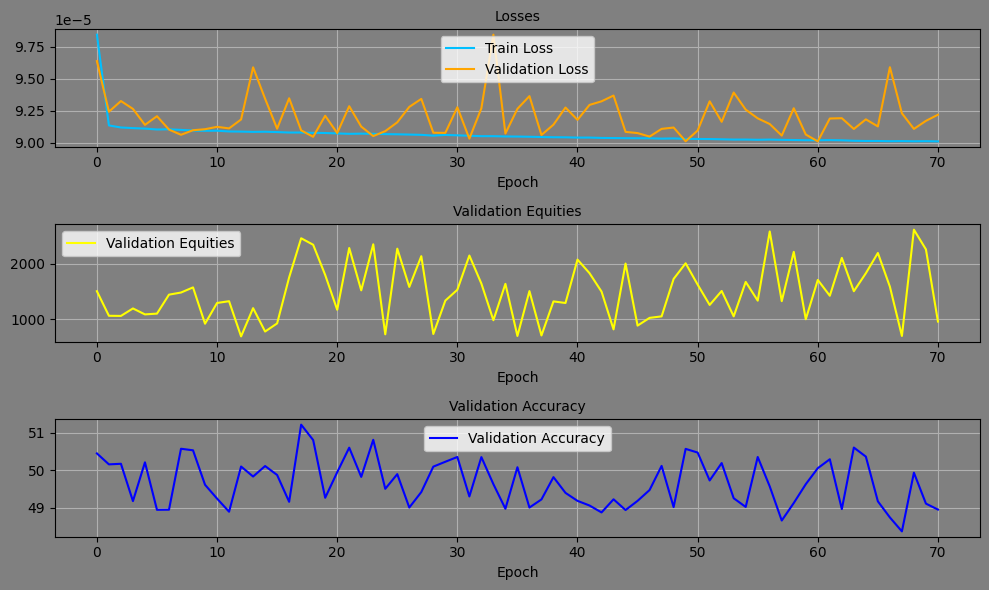

Epoch: 71, Val Equity: 923.25, Val Accuracy: 49.59 train_losses: 0.00028478519530055813, val_losses: 9.042365854838863e-05, Duration: 0:01:09.275602


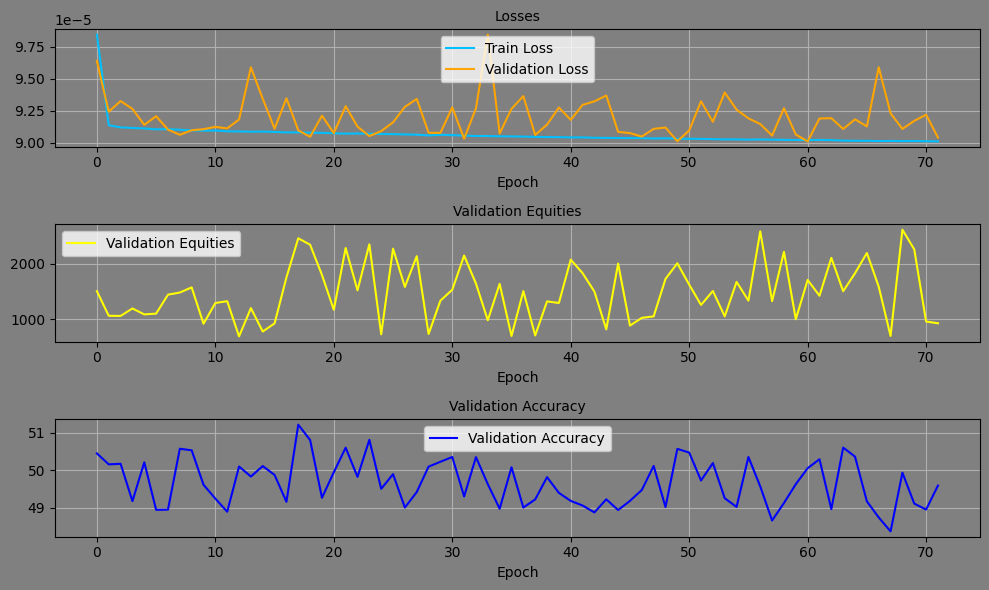

Epoch: 72, Val Equity: 877.03, Val Accuracy: 49.69 train_losses: 0.0002846984626632836, val_losses: 9.113901614909992e-05, Duration: 0:01:08.275441


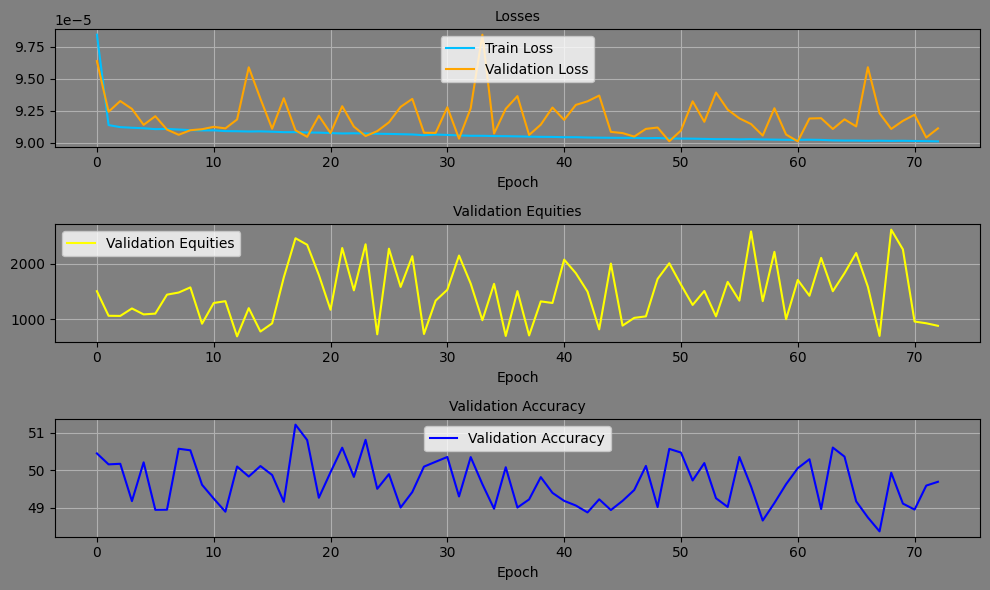

Epoch: 73, Val Equity: 1211.57, Val Accuracy: 48.95 train_losses: 0.0002846957101284043, val_losses: 9.184885857393965e-05, Duration: 0:01:08.162980


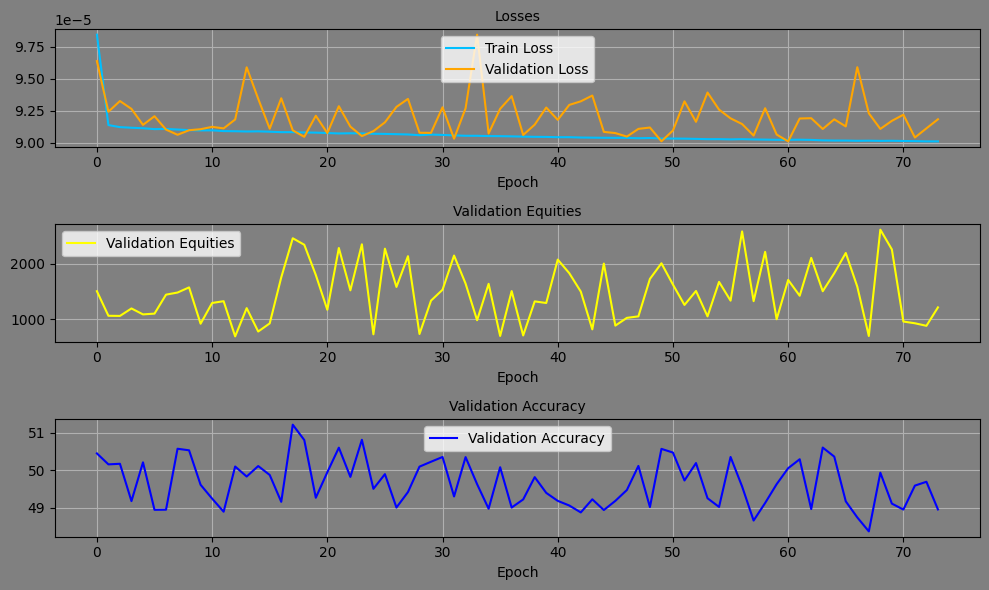

Epoch: 74, Val Equity: 1441.67, Val Accuracy: 50.34 train_losses: 0.00028461143693025, val_losses: 9.097952715819702e-05, Duration: 0:01:07.822895


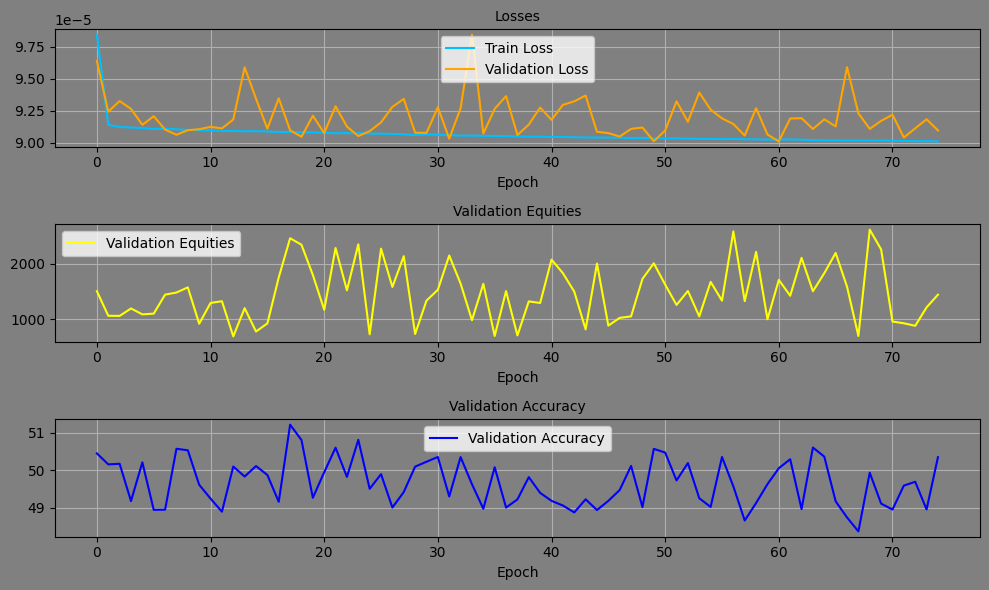

Epoch: 75, Val Equity: 2273.39, Val Accuracy: 50.92 train_losses: 0.00028465025711674446, val_losses: 9.034765389515087e-05, Duration: 0:01:08.129410


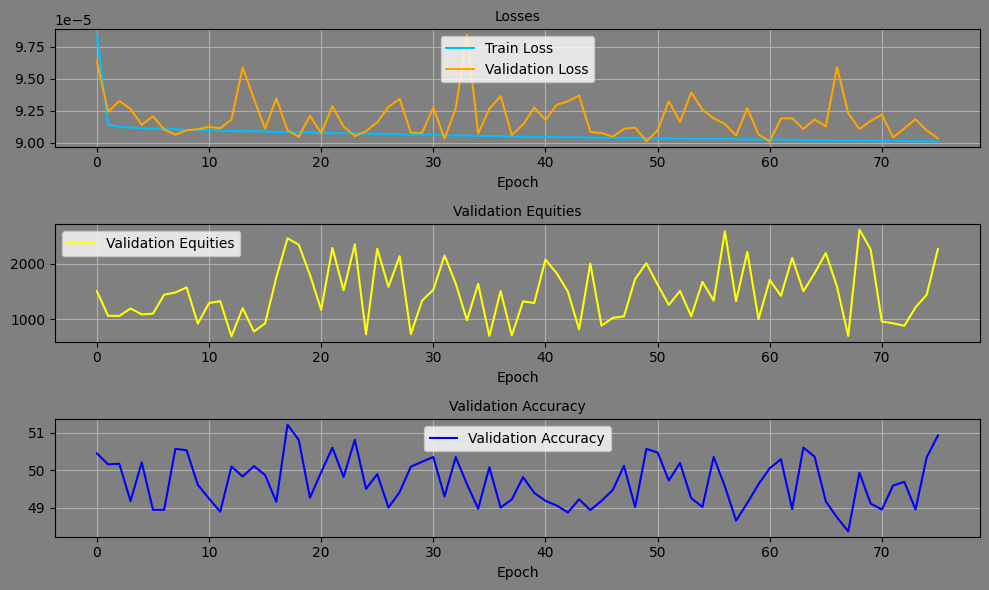

Epoch: 76, Val Equity: 1126.05, Val Accuracy: 50.11 train_losses: 0.00028449004723760357, val_losses: 9.24826817936264e-05, Duration: 0:01:07.877849


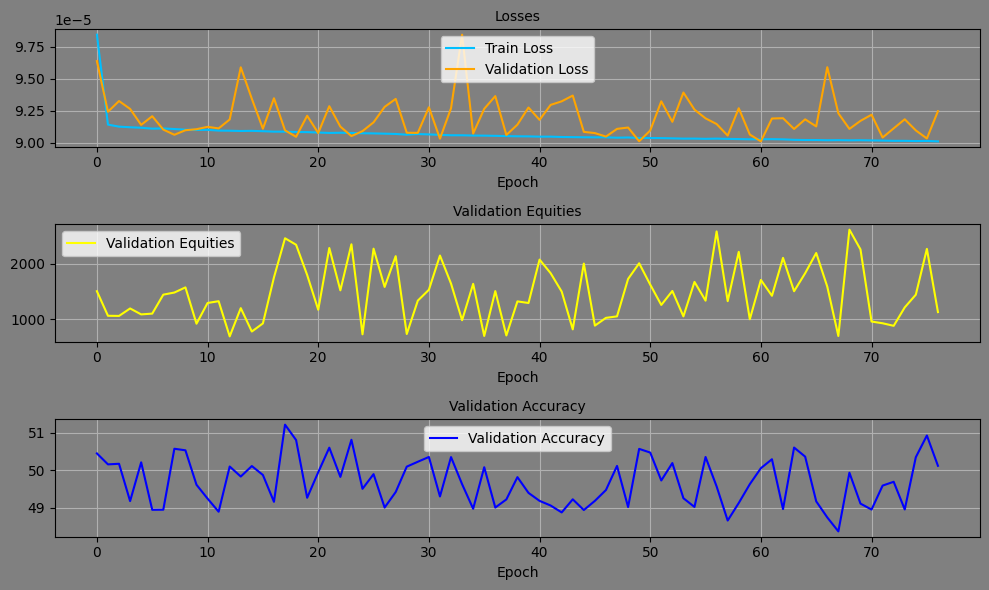

Epoch: 77, Val Equity: 1611.49, Val Accuracy: 50.22 train_losses: 0.0002845350163366172, val_losses: 9.162913920590654e-05, Duration: 0:01:07.983420


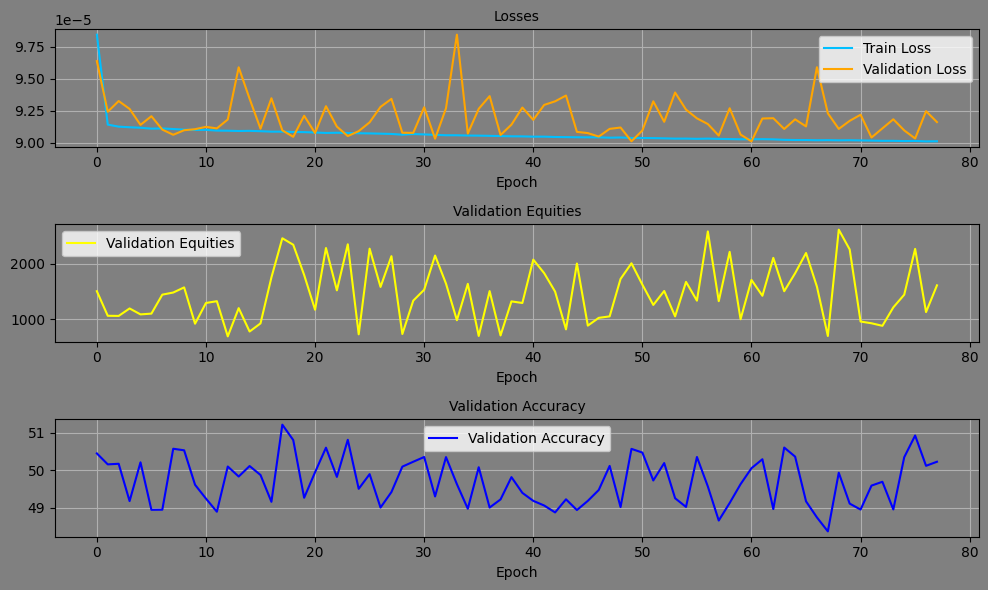

Epoch: 78, Val Equity: 1086.27, Val Accuracy: 48.49 train_losses: 0.00028442268658514745, val_losses: 9.085405326914042e-05, Duration: 0:01:08.133078


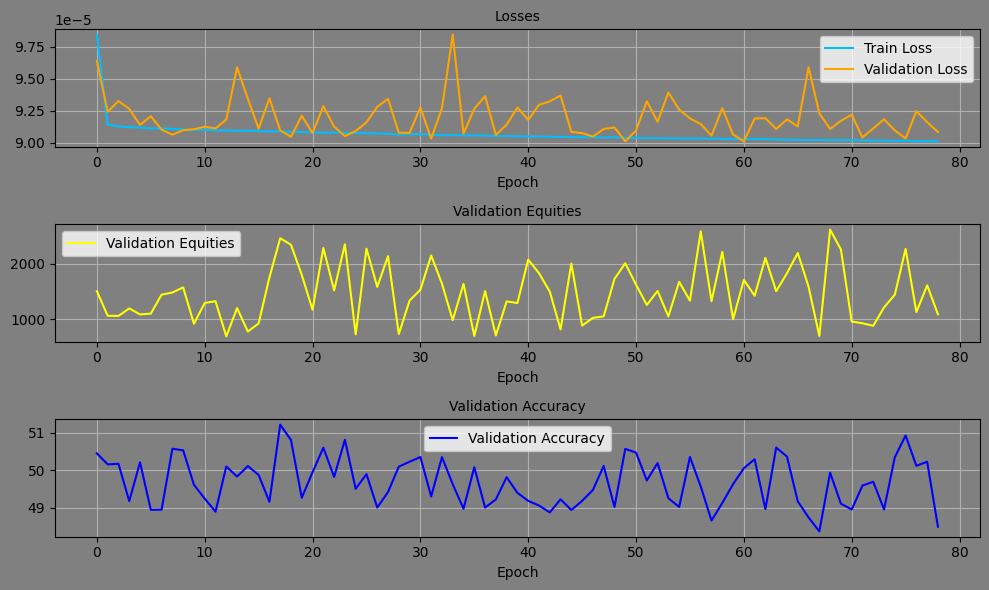

Epoch: 79, Val Equity: 1702.84, Val Accuracy: 50.33 train_losses: 0.0002843910827145808, val_losses: 9.147590026259422e-05, Duration: 0:01:08.144051


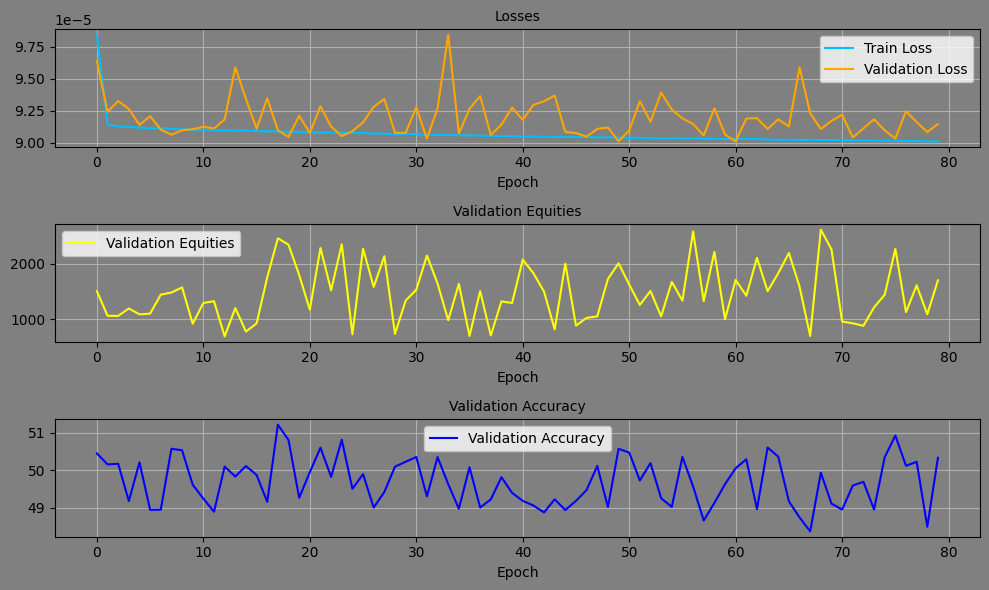

Epoch: 80, Val Equity: 2533.83, Val Accuracy: 49.59 train_losses: 0.00028427510242237056, val_losses: 9.004901221487671e-05, Duration: 0:01:09.259380


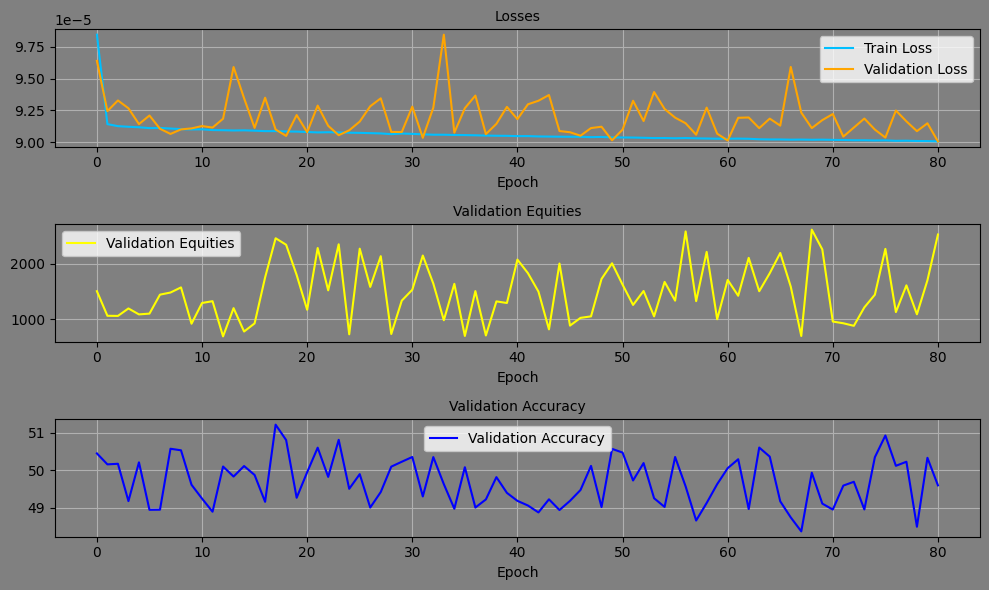

Epoch: 81, Val Equity: 1028.90, Val Accuracy: 48.97 train_losses: 0.0002843474163992548, val_losses: 9.248393325833604e-05, Duration: 0:01:09.345463


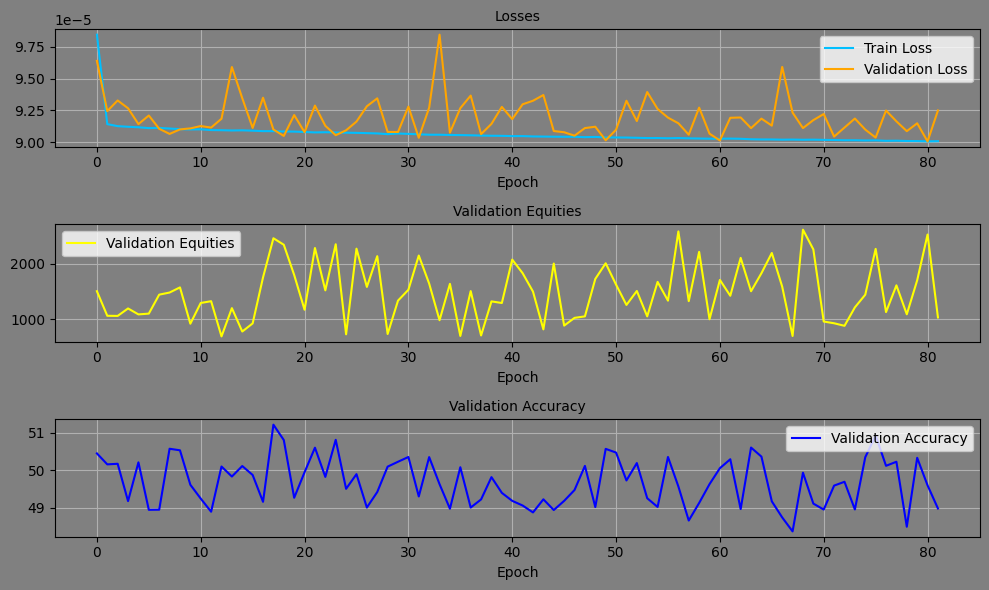

Epoch: 82, Val Equity: 1309.35, Val Accuracy: 50.13 train_losses: 0.0002843083163250087, val_losses: 9.189030970446765e-05, Duration: 0:01:08.051226


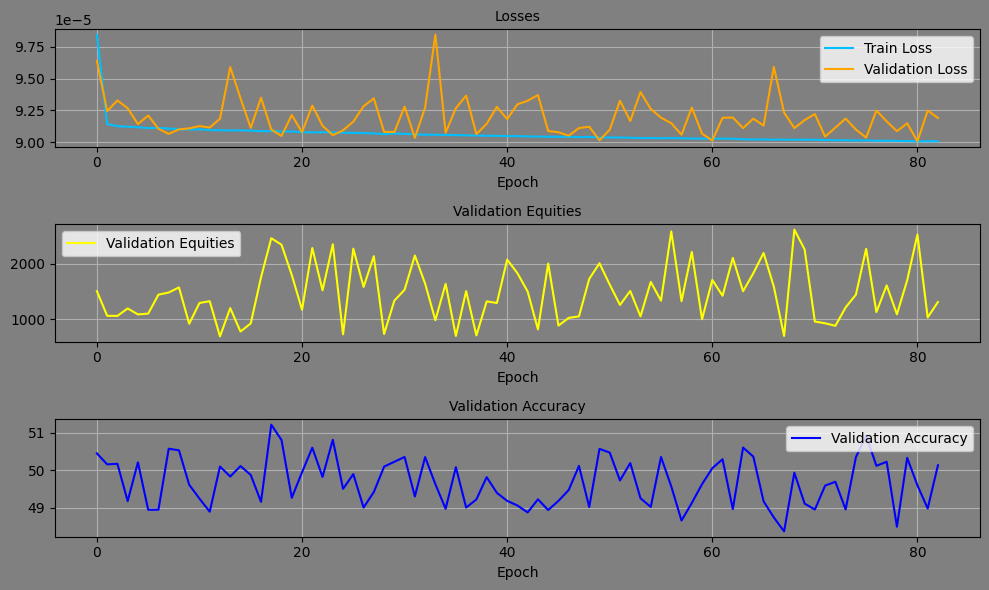

Epoch: 83, Val Equity: 1724.19, Val Accuracy: 49.01 train_losses: 0.0002840766998794266, val_losses: 9.186580427922308e-05, Duration: 0:01:08.059892


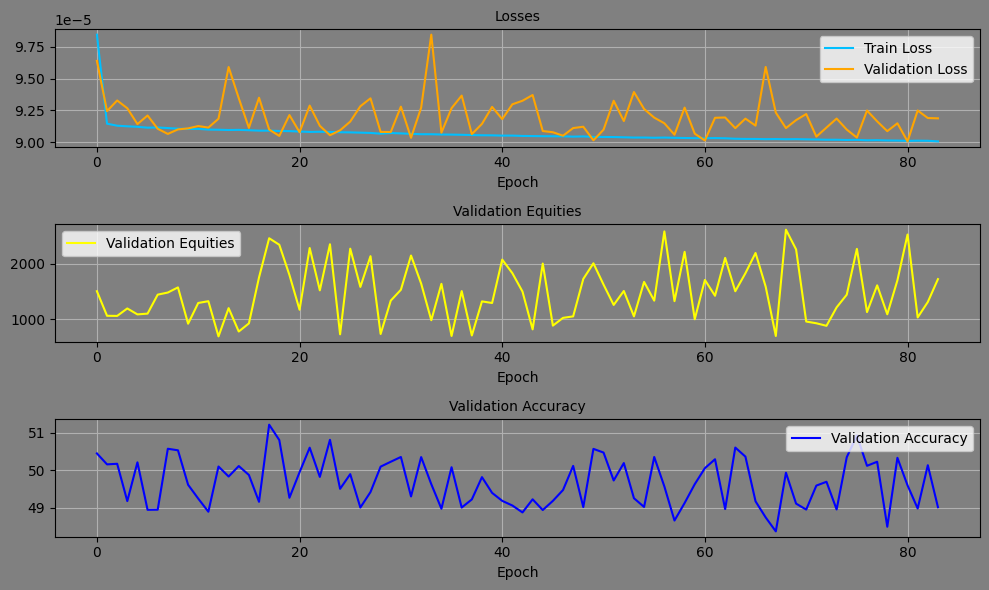

Epoch: 84, Val Equity: 2614.35, Val Accuracy: 50.20 train_losses: 0.00028407672634997417, val_losses: 9.178663458442315e-05, Duration: 0:01:07.908573


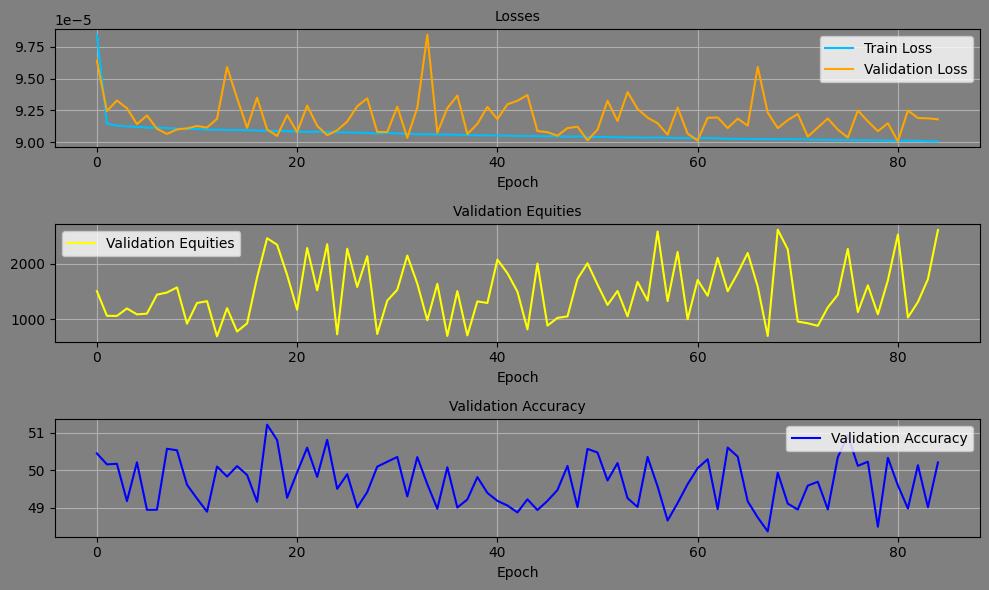

Epoch: 85, Val Equity: 1583.18, Val Accuracy: 49.57 train_losses: 0.00028409251259092815, val_losses: 9.020822471939027e-05, Duration: 0:01:07.813189


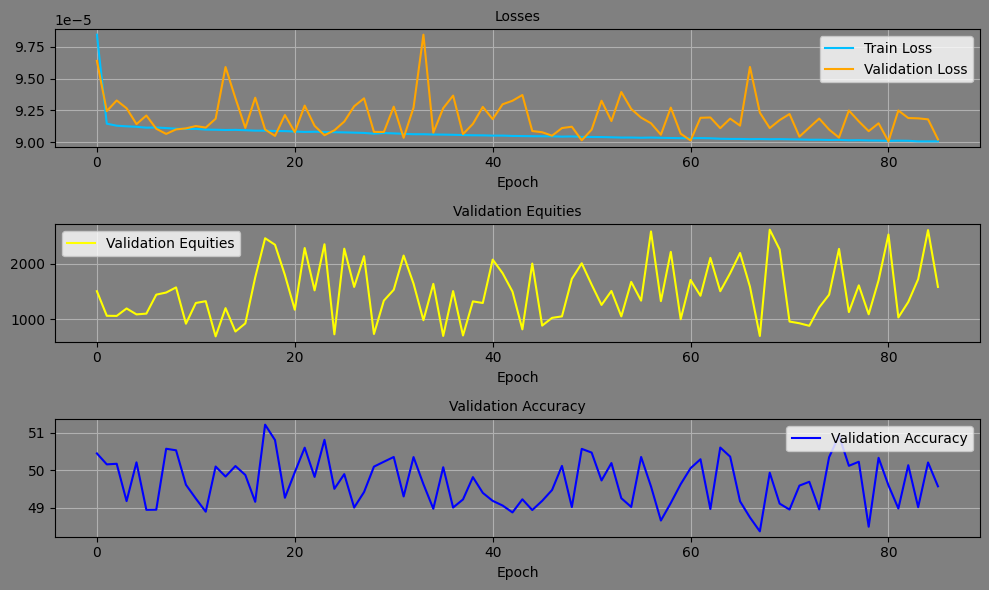

Epoch: 86, Val Equity: 1965.08, Val Accuracy: 49.60 train_losses: 0.00028403709528656396, val_losses: 9.119080641539767e-05, Duration: 0:01:07.905237


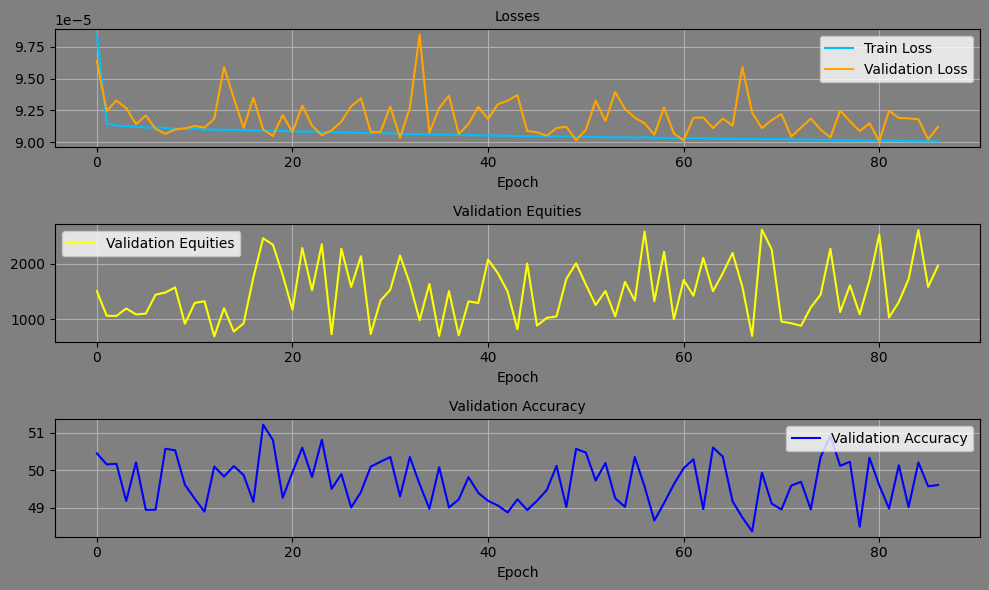

Epoch: 87, Val Equity: 994.74, Val Accuracy: 50.13 train_losses: 0.00028397916152081177, val_losses: 9.180826600641012e-05, Duration: 0:01:08.480907


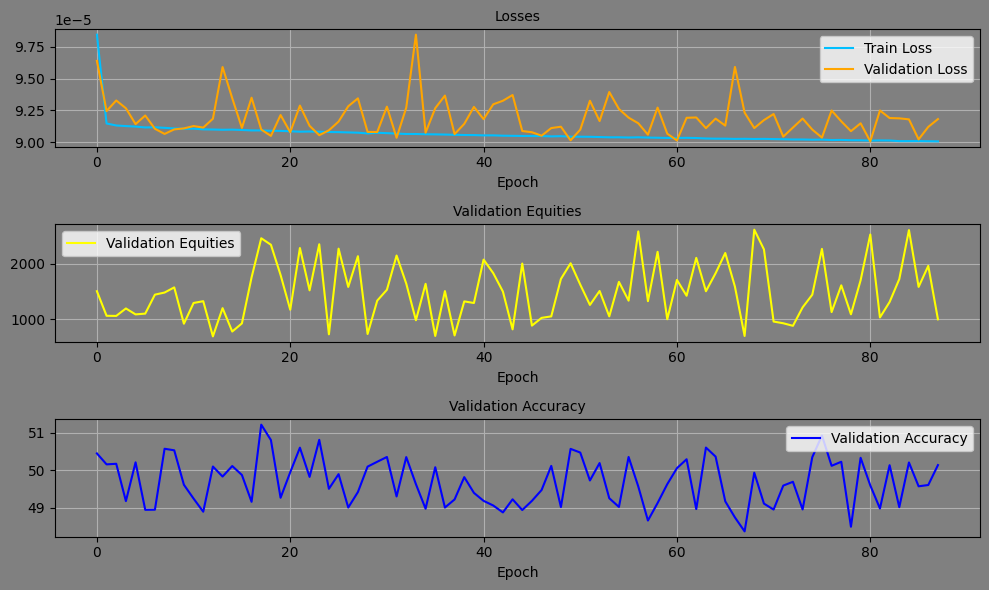

Epoch: 88, Val Equity: 1707.01, Val Accuracy: 48.54 train_losses: 0.0002840142765280245, val_losses: 9.14084812393412e-05, Duration: 0:01:08.275672


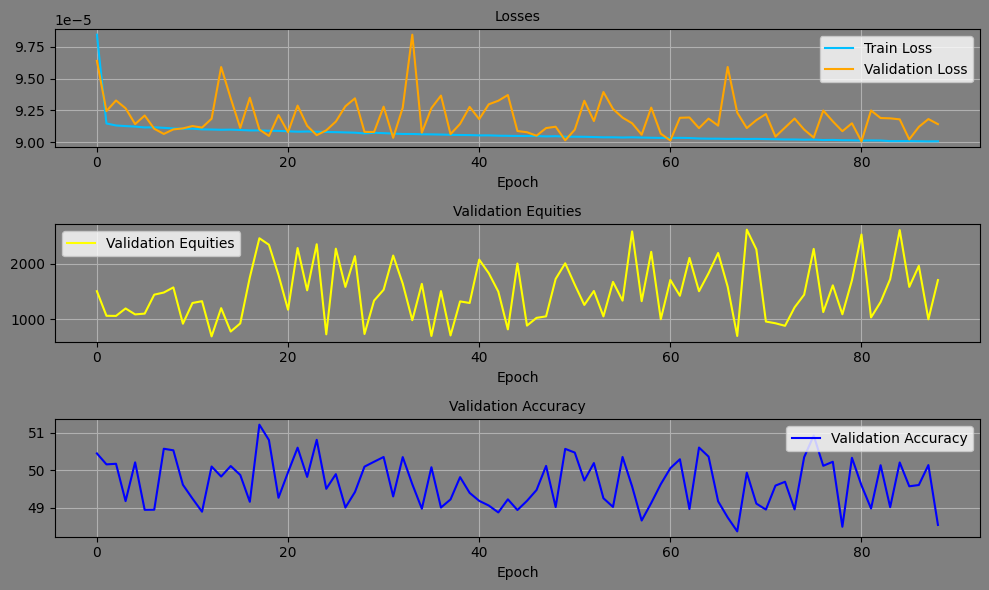

Epoch: 89, Val Equity: 1506.85, Val Accuracy: 48.76 train_losses: 0.00028392351988597466, val_losses: 9.068271901924163e-05, Duration: 0:01:08.061147


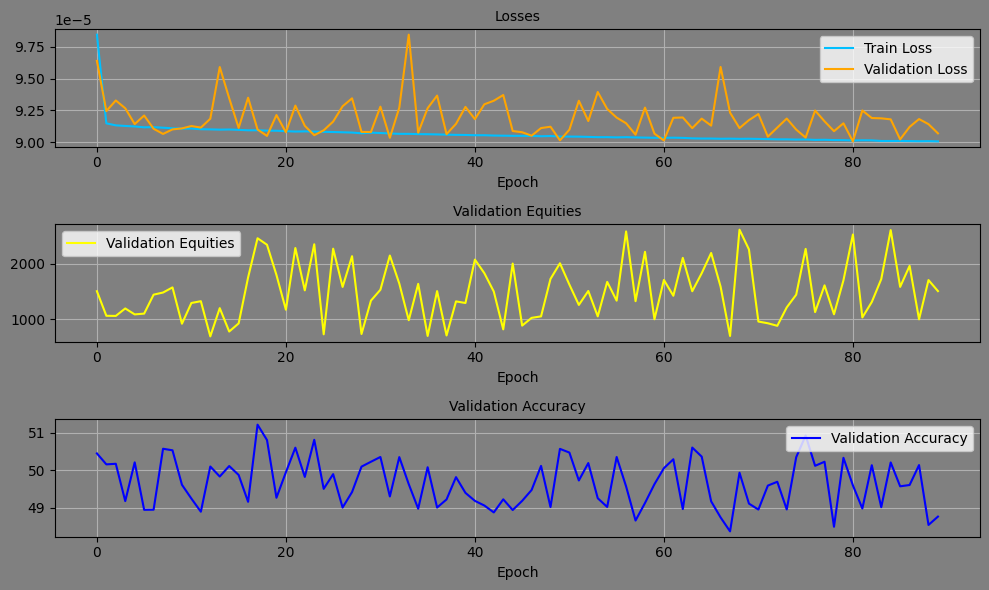

Epoch: 90, Val Equity: 1525.18, Val Accuracy: 48.79 train_losses: 0.00028387632904622204, val_losses: 9.289672743761912e-05, Duration: 0:01:07.826134


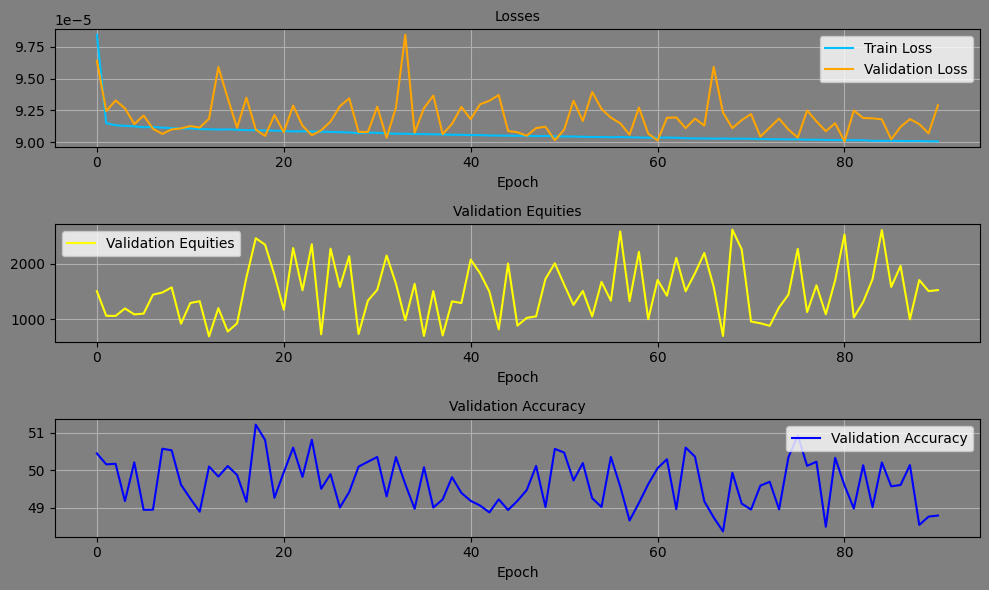

Epoch: 91, Val Equity: 1002.23, Val Accuracy: 49.98 train_losses: 0.00028385636037742227, val_losses: 9.138096356764436e-05, Duration: 0:01:08.130763


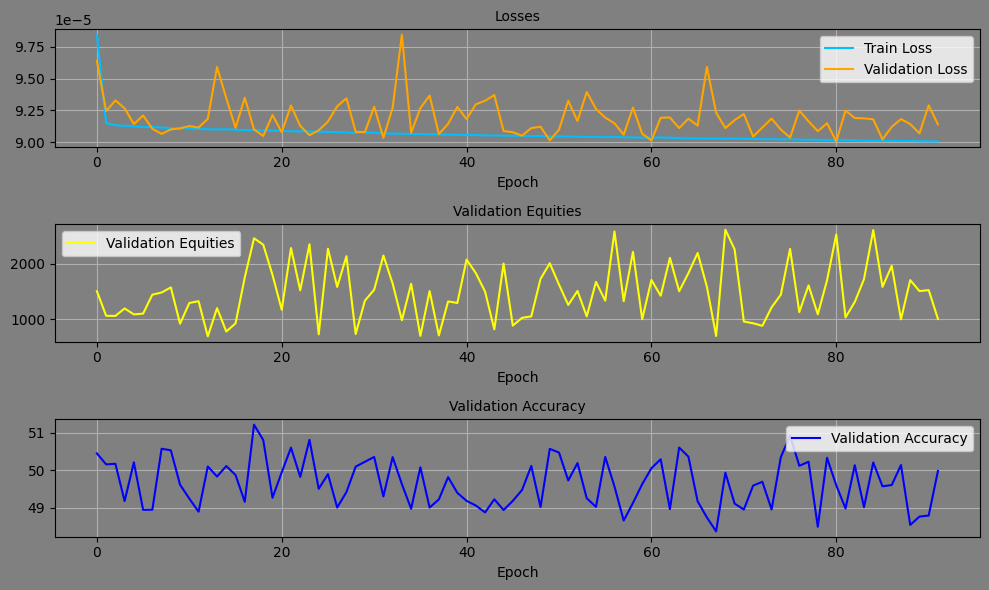

Epoch: 92, Val Equity: 2720.35, Val Accuracy: 51.22 train_losses: 0.00028381840678040187, val_losses: 9.382168354932219e-05, Duration: 0:01:12.770363


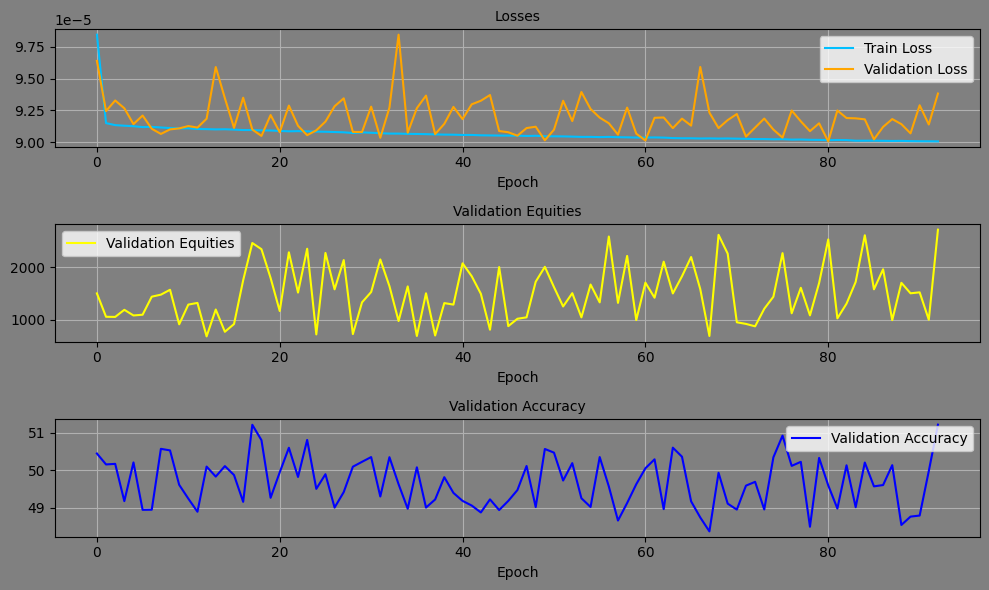

Epoch: 93, Val Equity: 2306.76, Val Accuracy: 49.82 train_losses: 0.0002837154627956614, val_losses: 9.180993947666138e-05, Duration: 0:01:08.246702


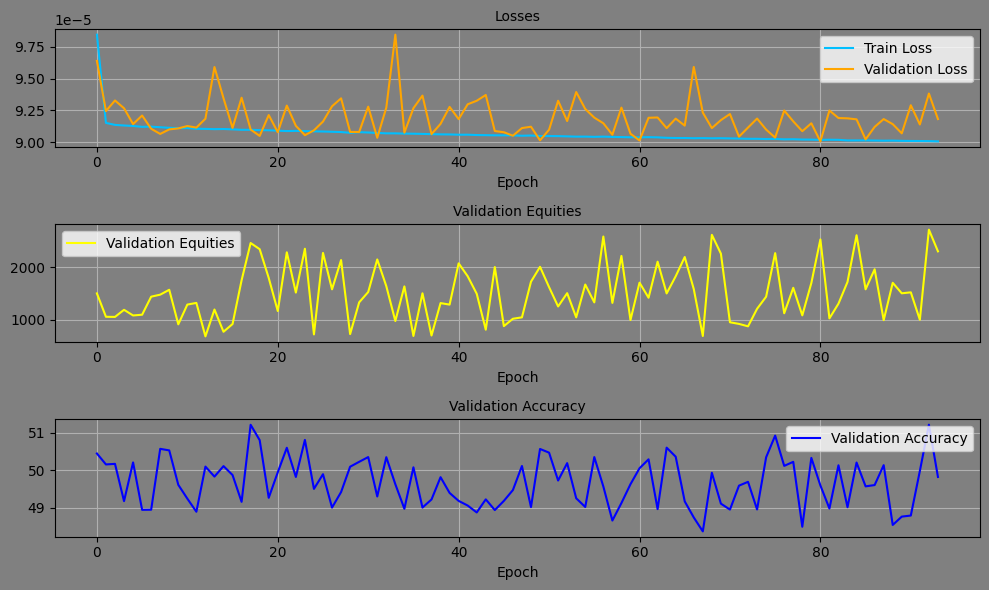

Epoch: 94, Val Equity: 2058.40, Val Accuracy: 50.04 train_losses: 0.00028380153264375563, val_losses: 9.155592852039263e-05, Duration: 0:01:08.120798


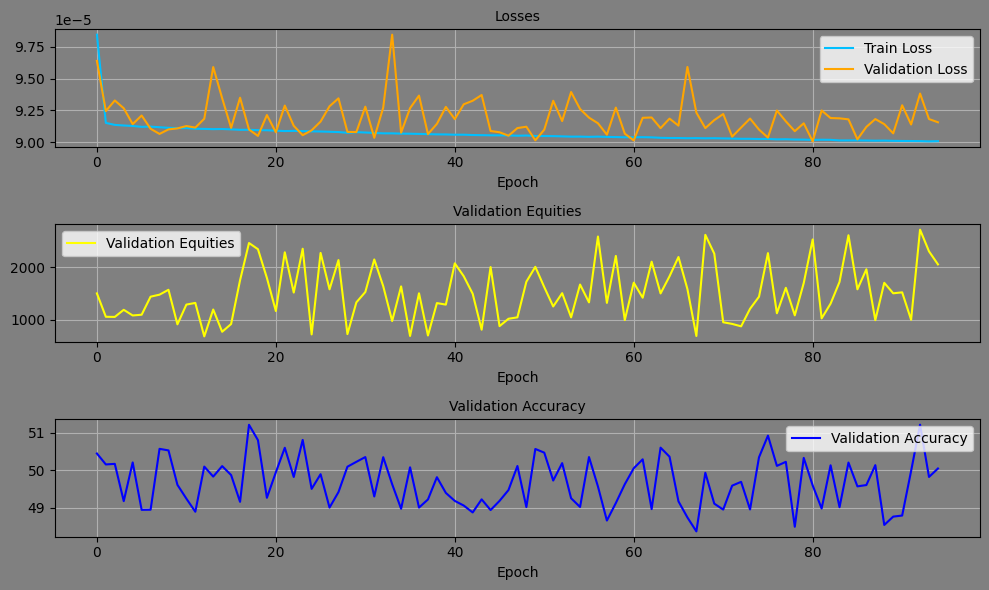

Epoch: 95, Val Equity: 2128.86, Val Accuracy: 50.45 train_losses: 0.0002836617074195616, val_losses: 9.035847324412316e-05, Duration: 0:01:08.087603


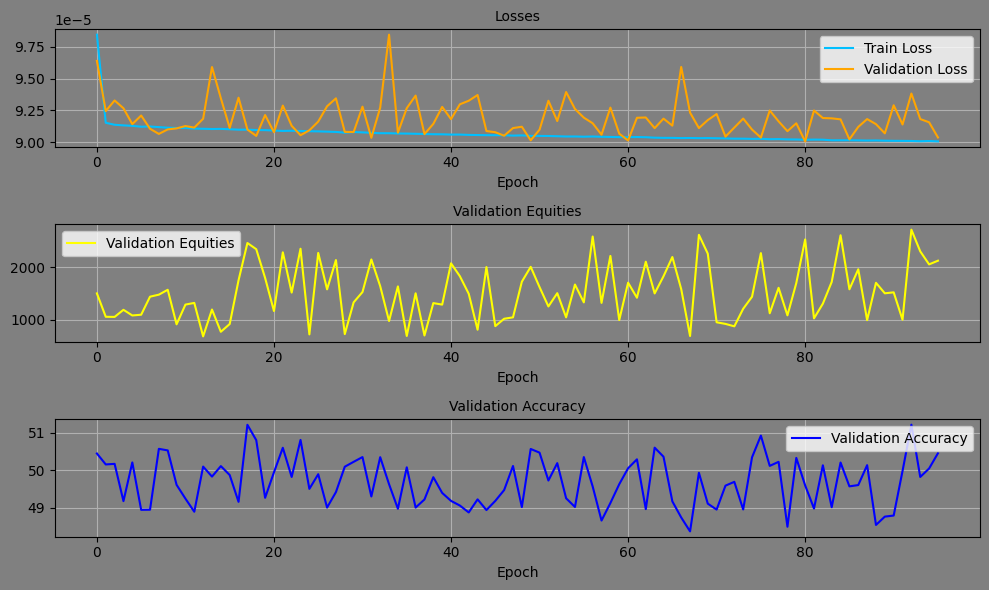

Epoch: 96, Val Equity: 1568.51, Val Accuracy: 50.04 train_losses: 0.00028356617148406297, val_losses: 9.239658538717777e-05, Duration: 0:01:07.737697


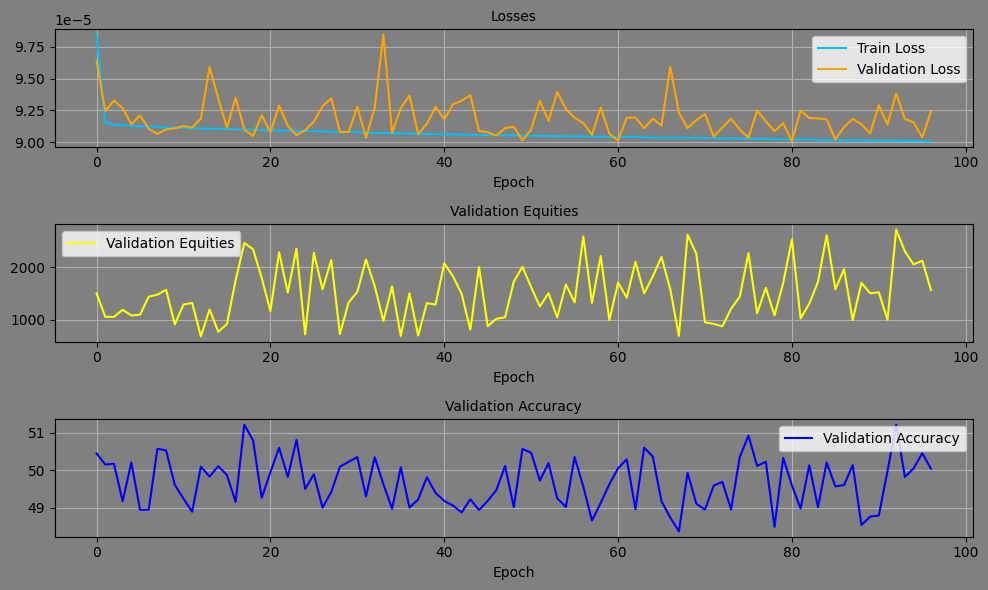

Epoch: 97, Val Equity: 2119.39, Val Accuracy: 49.72 train_losses: 0.0002836240544488979, val_losses: 9.132792911259457e-05, Duration: 0:01:07.518059


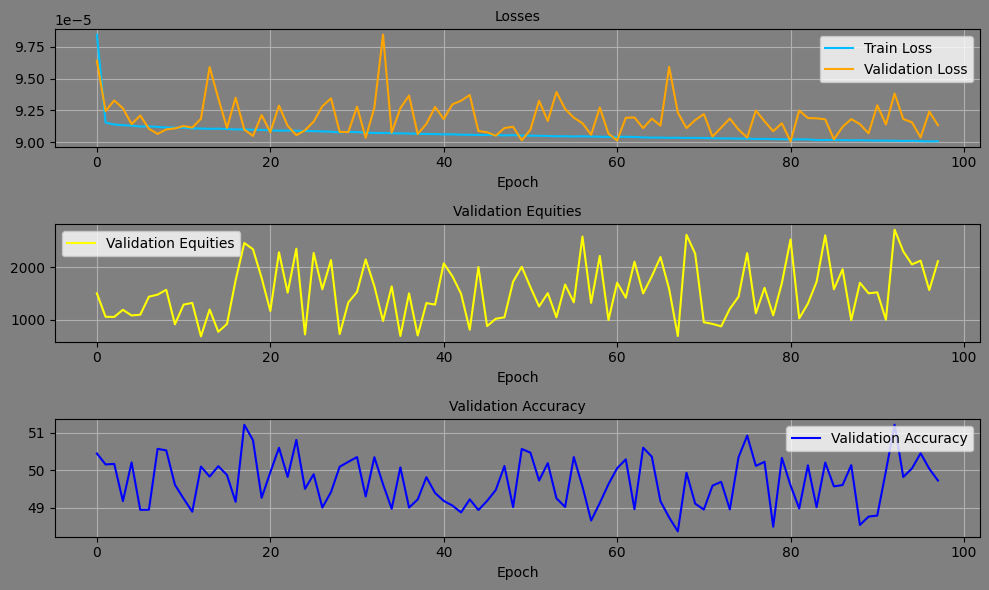

Epoch: 98, Val Equity: 2808.21, Val Accuracy: 50.66 train_losses: 0.0002837222023260911, val_losses: 9.020559082273394e-05, Duration: 0:01:08.372159


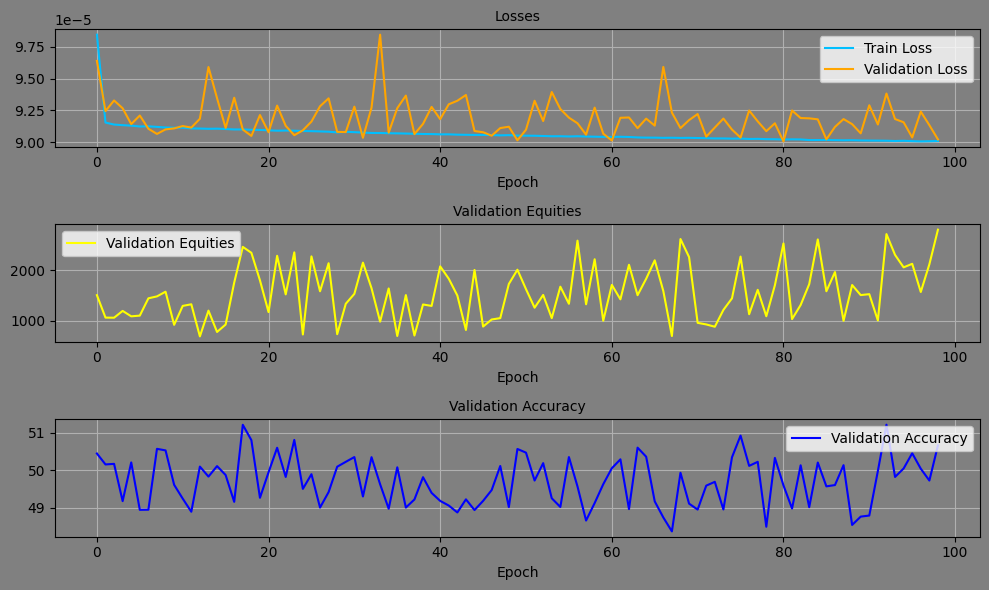

Epoch: 99, Val Equity: 721.05, Val Accuracy: 49.66 train_losses: 0.0002836039219268636, val_losses: 9.114100248552859e-05, Duration: 0:01:07.905162


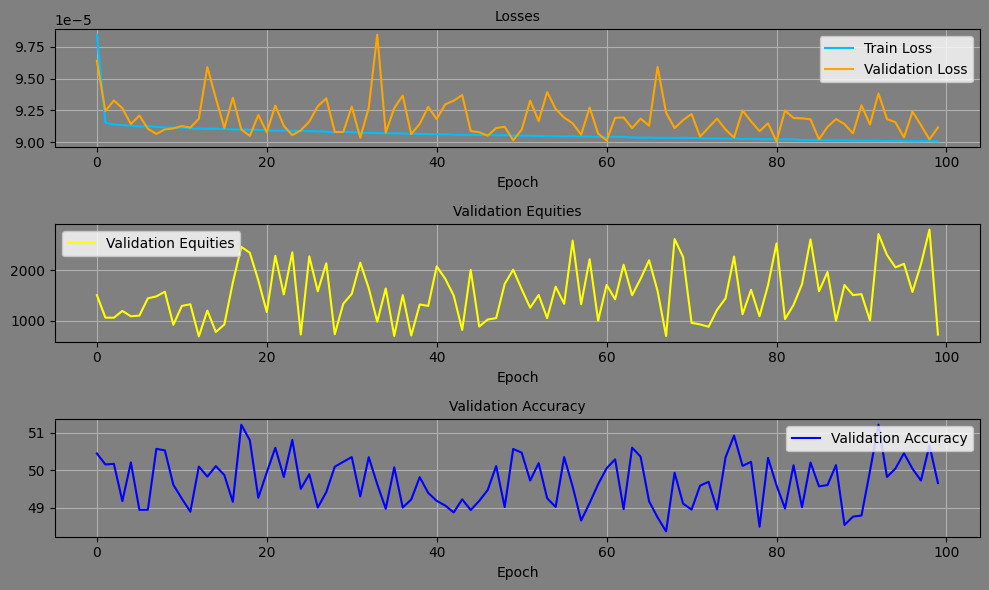

Epoch: 100, Val Equity: 1795.27, Val Accuracy: 49.41 train_losses: 0.0002835317368348063, val_losses: 9.133539424510673e-05, Duration: 0:01:08.089933


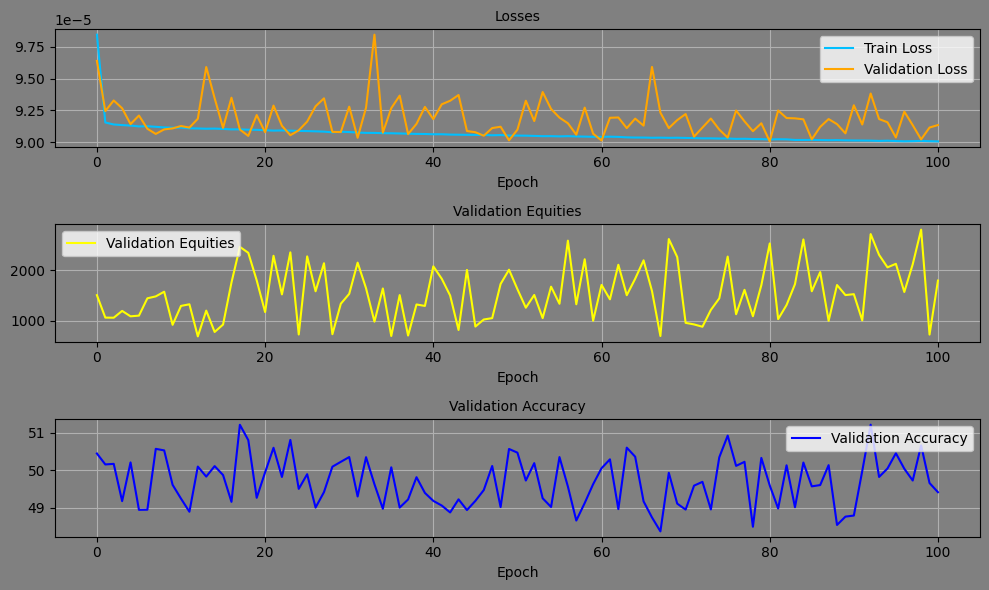

Epoch: 101, Val Equity: 1095.51, Val Accuracy: 50.19 train_losses: 0.0002834456988864993, val_losses: 9.082016185857356e-05, Duration: 0:01:08.370245


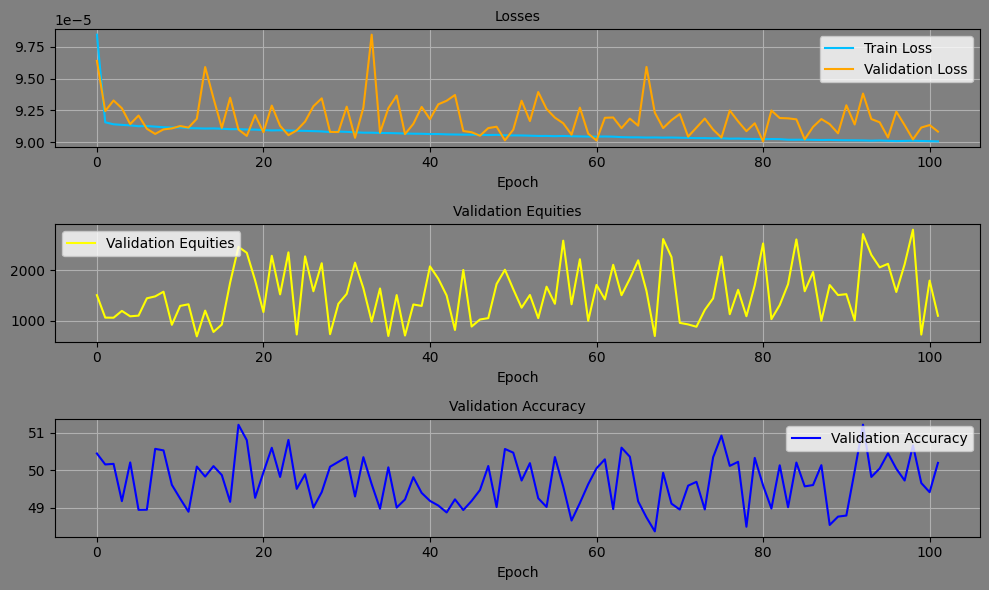

Epoch: 102, Val Equity: 950.87, Val Accuracy: 49.35 train_losses: 0.0002834715122704933, val_losses: 9.069140651263297e-05, Duration: 0:01:07.905318


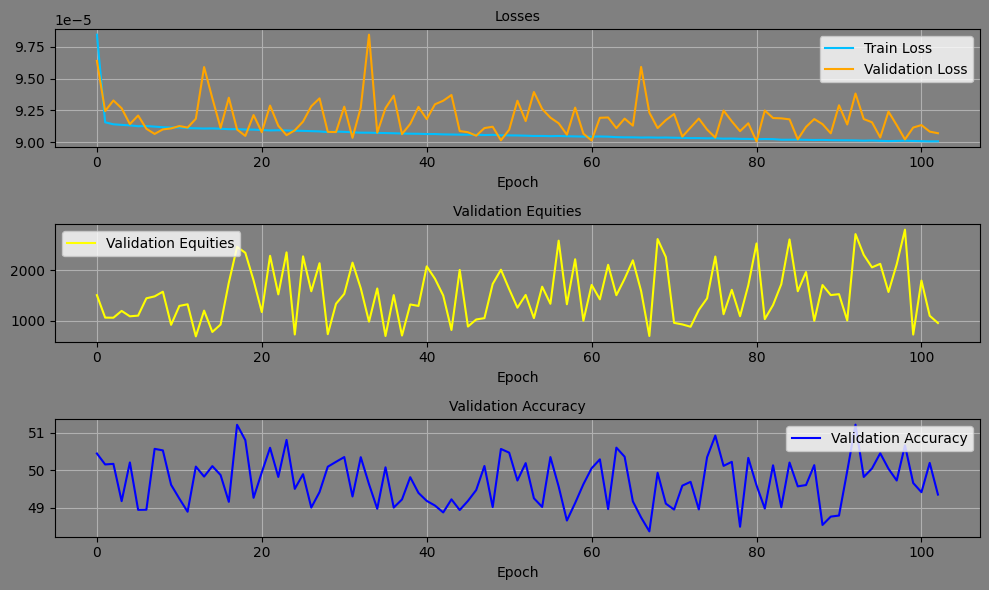

Epoch: 103, Val Equity: 1917.60, Val Accuracy: 49.29 train_losses: 0.0002833623304830666, val_losses: 9.102791227633134e-05, Duration: 0:01:07.930933


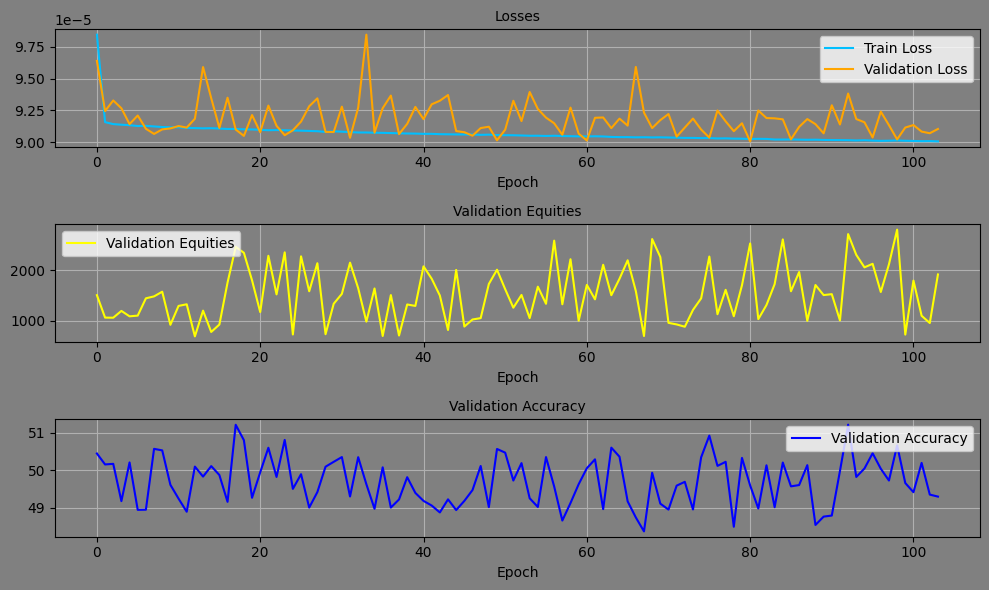

Epoch: 104, Val Equity: 1468.76, Val Accuracy: 50.37 train_losses: 0.0002832438397520979, val_losses: 9.301646787207574e-05, Duration: 0:01:09.299404


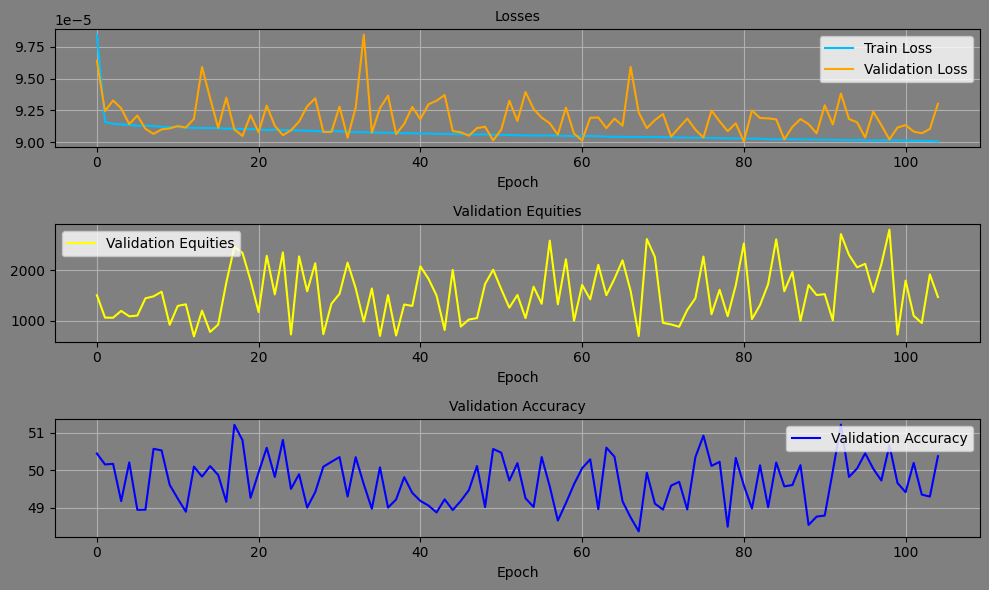

Epoch: 105, Val Equity: 1461.38, Val Accuracy: 49.16 train_losses: 0.00028332416869309644, val_losses: 9.074117406271398e-05, Duration: 0:01:08.022416


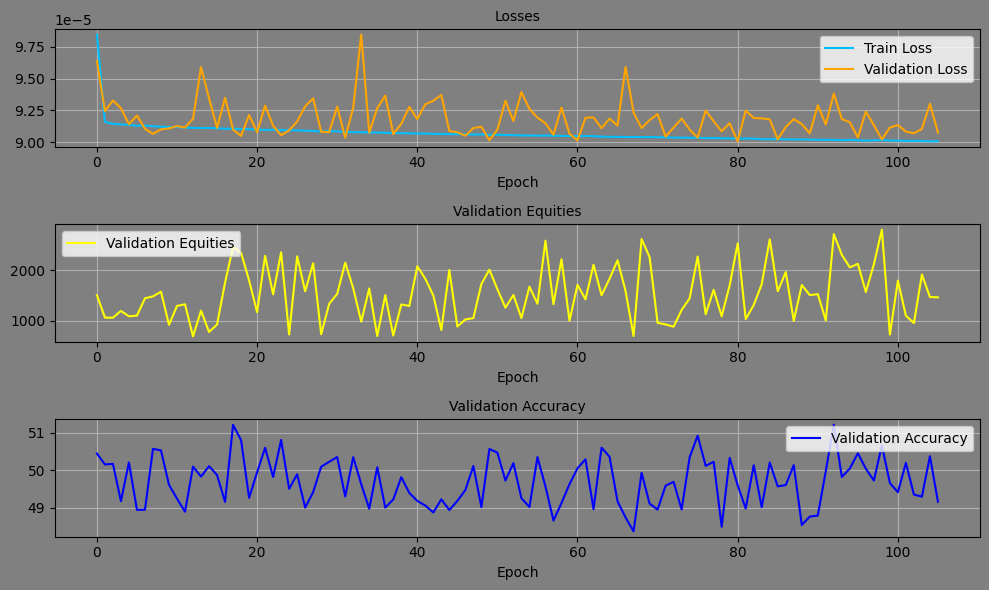

Epoch: 106, Val Equity: 1820.91, Val Accuracy: 49.04 train_losses: 0.00028328056912858124, val_losses: 9.135546133620664e-05, Duration: 0:01:08.208952


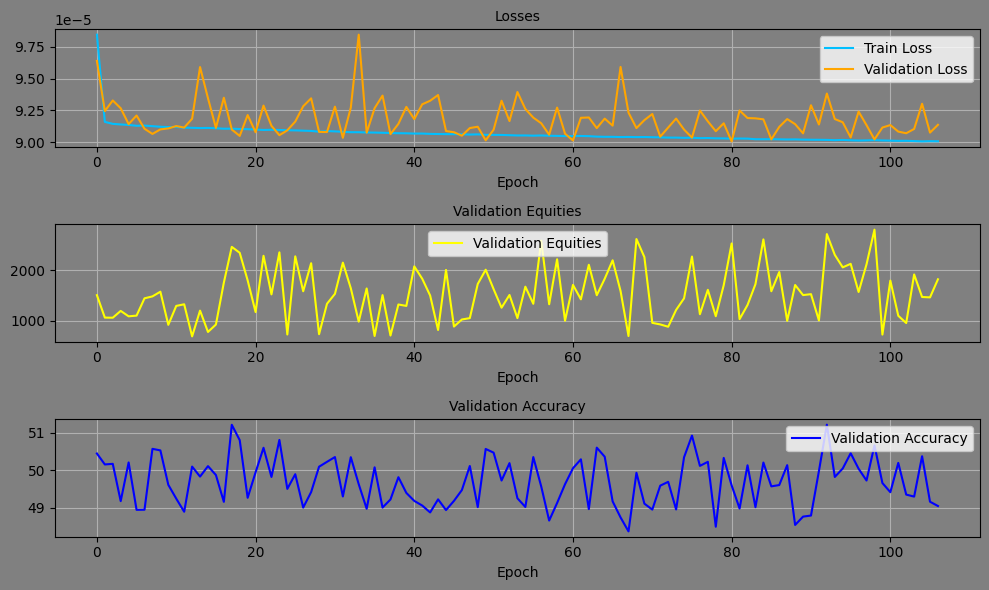

Epoch: 107, Val Equity: 1897.57, Val Accuracy: 50.20 train_losses: 0.00028327785308994967, val_losses: 9.093731932807714e-05, Duration: 0:01:11.057804


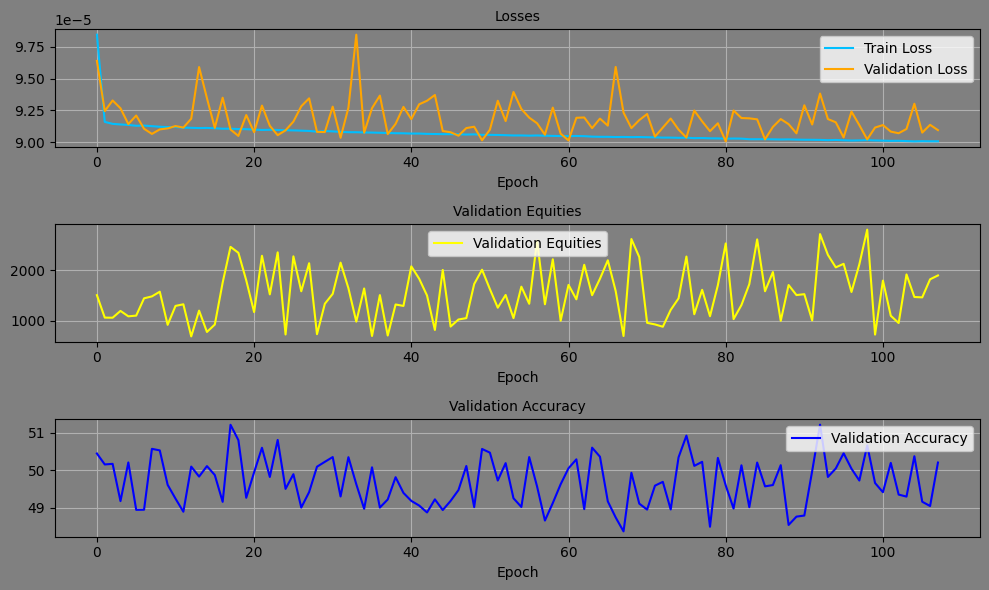

Epoch: 108, Val Equity: 1436.13, Val Accuracy: 50.35 train_losses: 0.0002832129554942584, val_losses: 9.195334132527933e-05, Duration: 0:01:08.080626


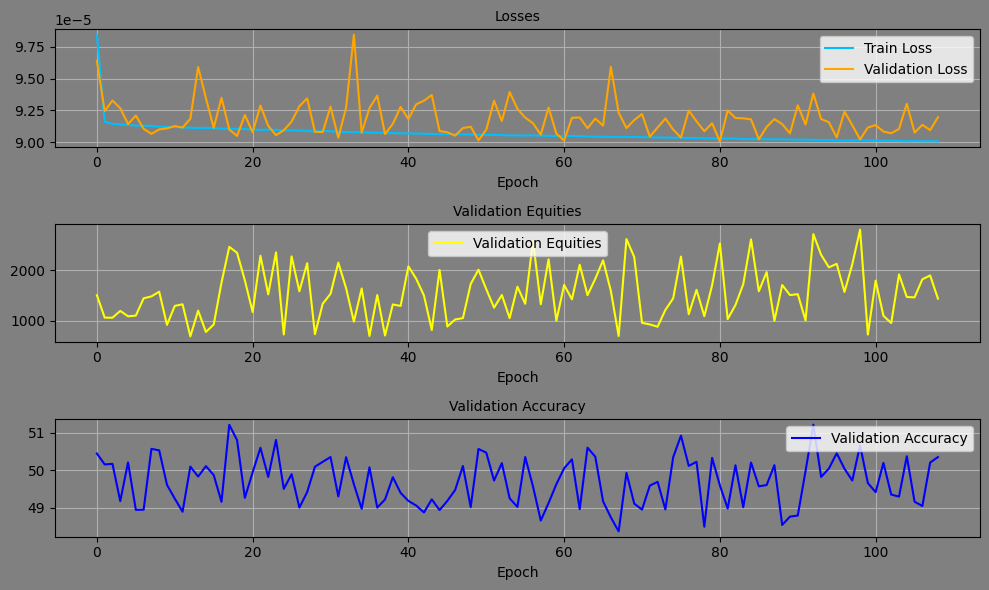

Epoch: 109, Val Equity: 2320.11, Val Accuracy: 50.54 train_losses: 0.0002831868115422145, val_losses: 9.204895468428731e-05, Duration: 0:01:07.985161


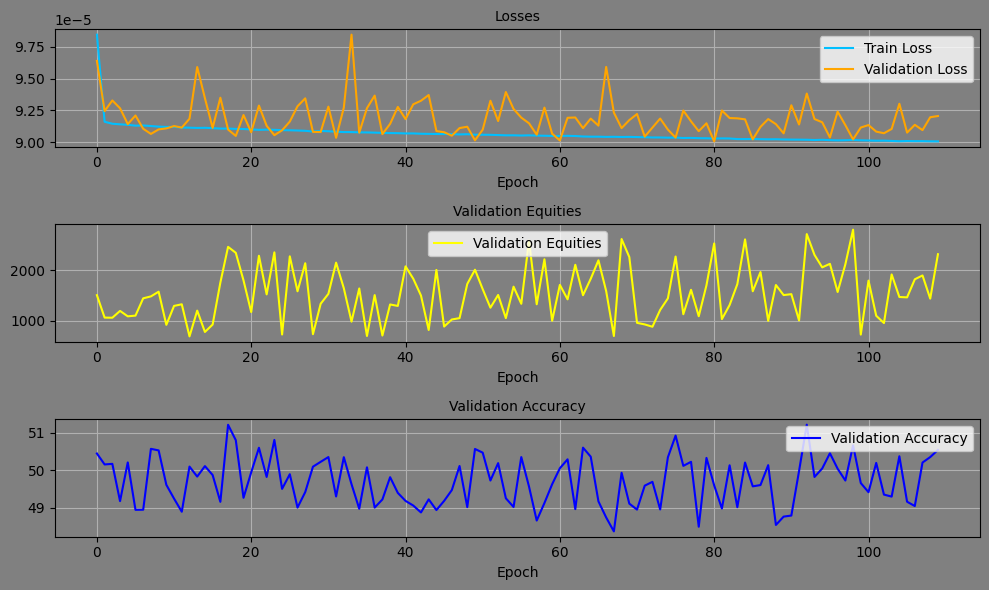

Epoch: 110, Val Equity: 2484.38, Val Accuracy: 51.39 train_losses: 0.00028297809579195626, val_losses: 9.427726763533428e-05, Duration: 0:01:08.022389


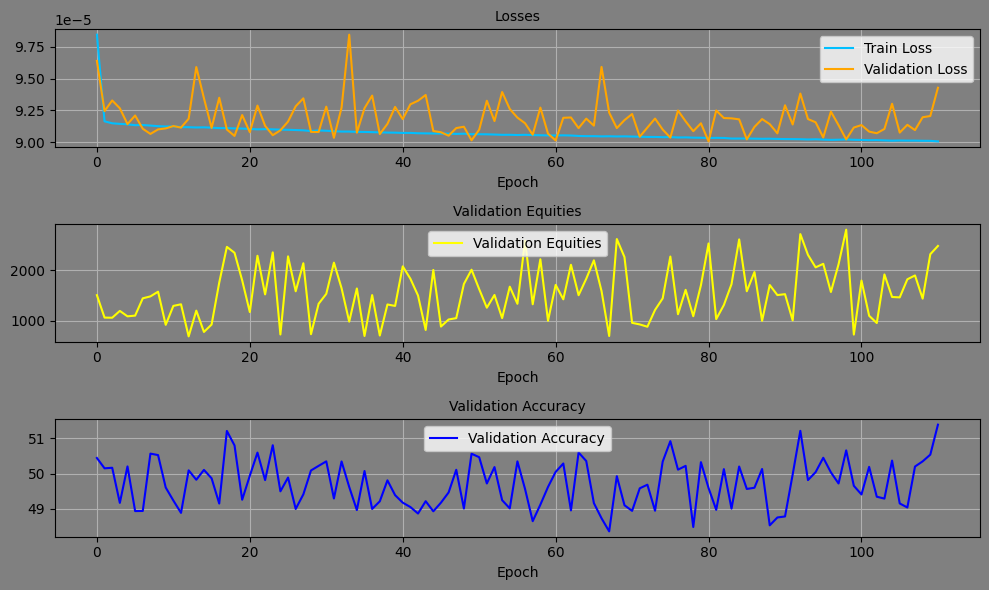

Epoch: 111, Val Equity: 1170.86, Val Accuracy: 50.20 train_losses: 0.0002831368363491322, val_losses: 9.1179994342383e-05, Duration: 0:01:08.042191


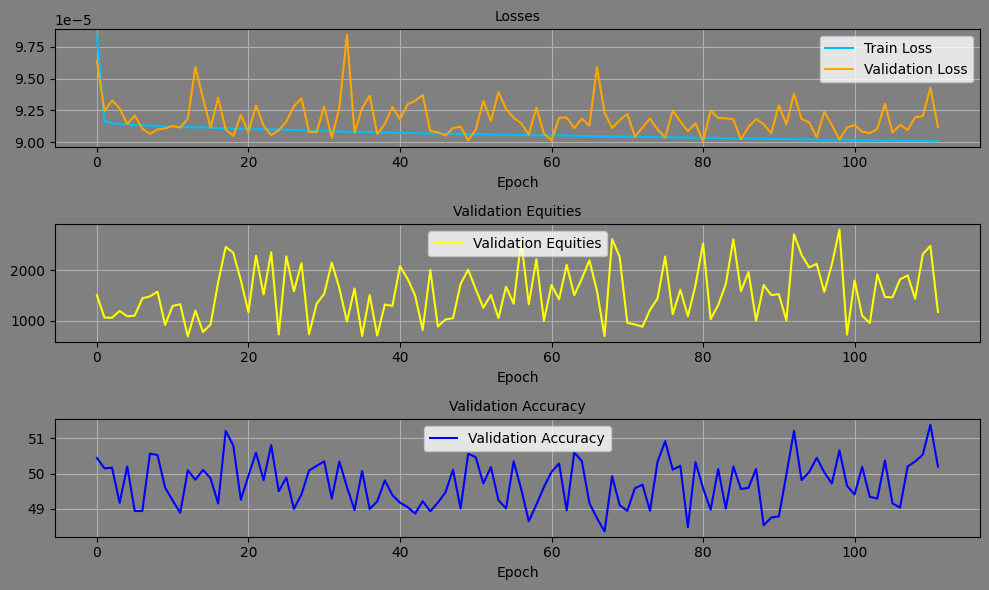

Epoch: 112, Val Equity: 1186.92, Val Accuracy: 50.22 train_losses: 0.0002830235304445782, val_losses: 9.101518662646413e-05, Duration: 0:01:08.256920


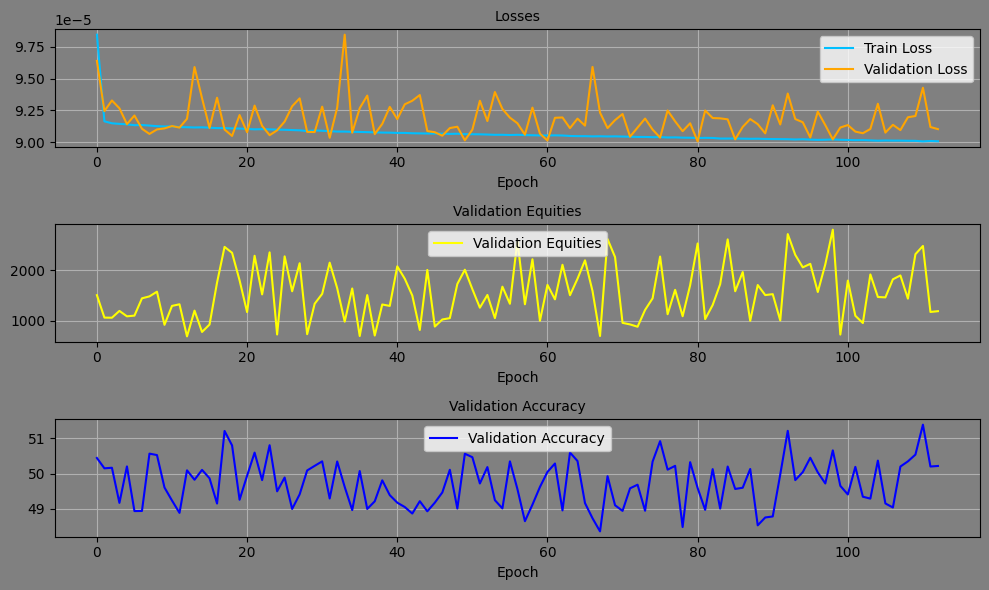

Epoch: 113, Val Equity: 866.40, Val Accuracy: 50.12 train_losses: 0.00028308108098494035, val_losses: 9.320570825366303e-05, Duration: 0:01:08.035475


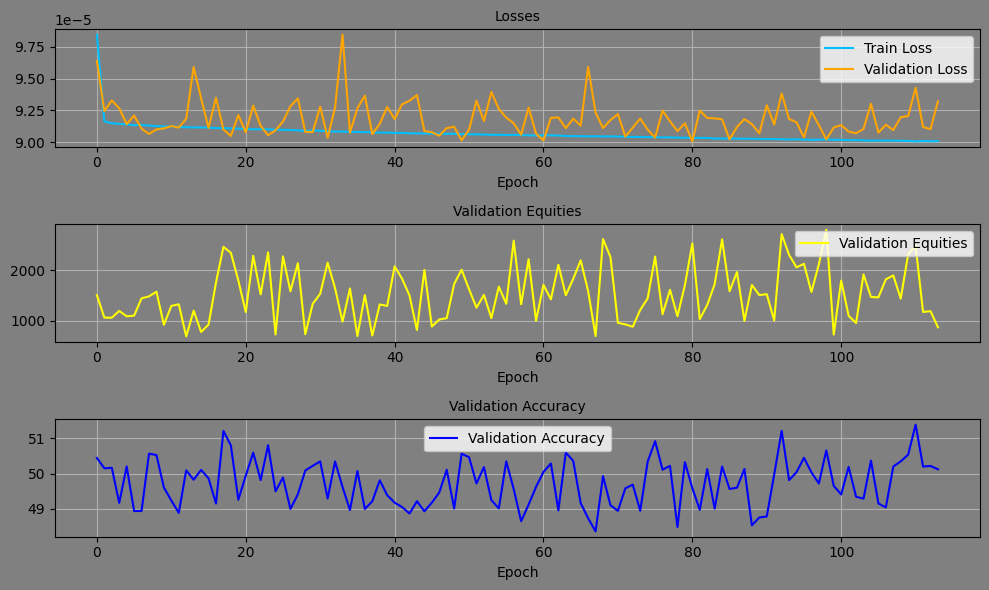

Epoch: 114, Val Equity: 2169.31, Val Accuracy: 50.29 train_losses: 0.00028295300388959005, val_losses: 9.22269027796574e-05, Duration: 0:01:07.947185


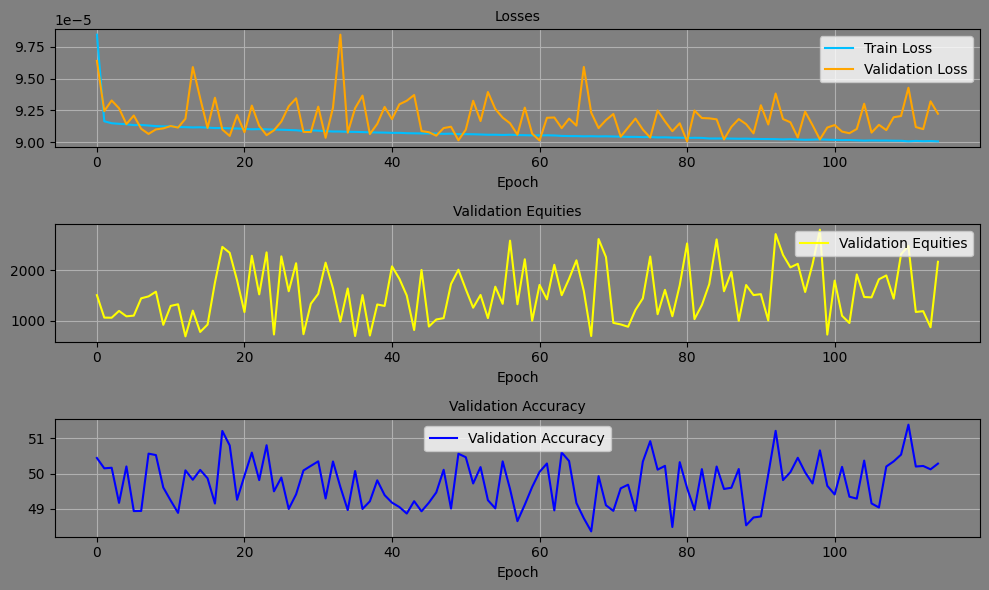

Epoch: 115, Val Equity: 2030.67, Val Accuracy: 50.27 train_losses: 0.00028300458665383977, val_losses: 9.157296881312504e-05, Duration: 0:01:08.201226


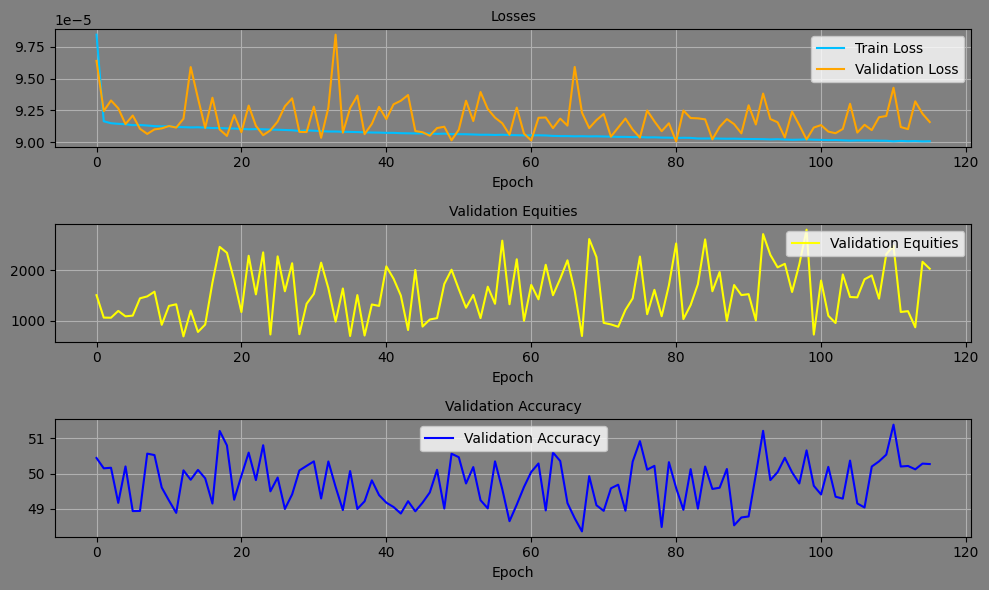

Epoch: 116, Val Equity: 1092.81, Val Accuracy: 49.71 train_losses: 0.00028291792587450303, val_losses: 9.440311987418681e-05, Duration: 0:01:08.081768


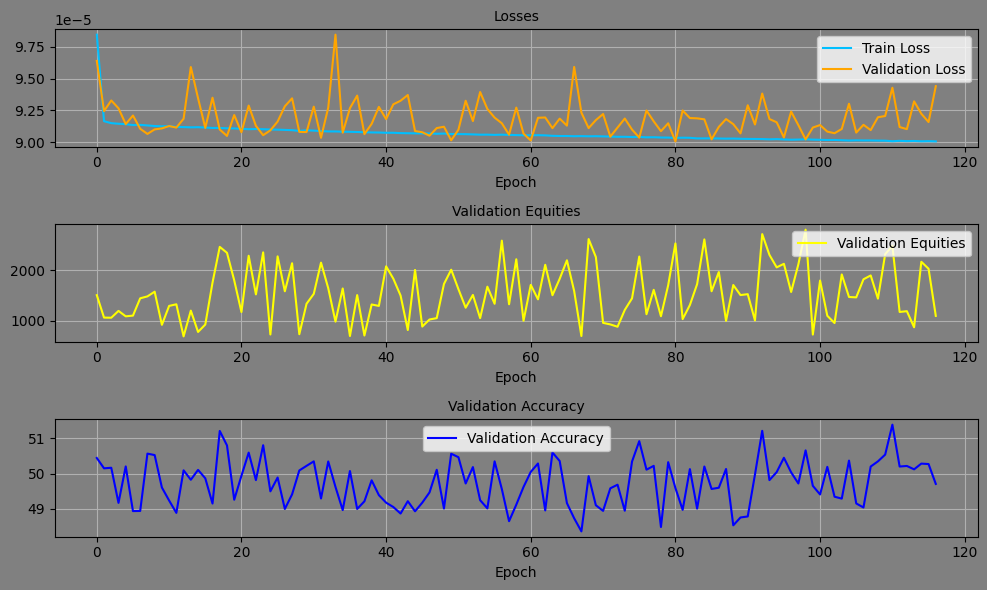

Epoch: 117, Val Equity: 1601.35, Val Accuracy: 49.02 train_losses: 0.00028295648208986527, val_losses: 9.095016866922379e-05, Duration: 0:01:07.582045


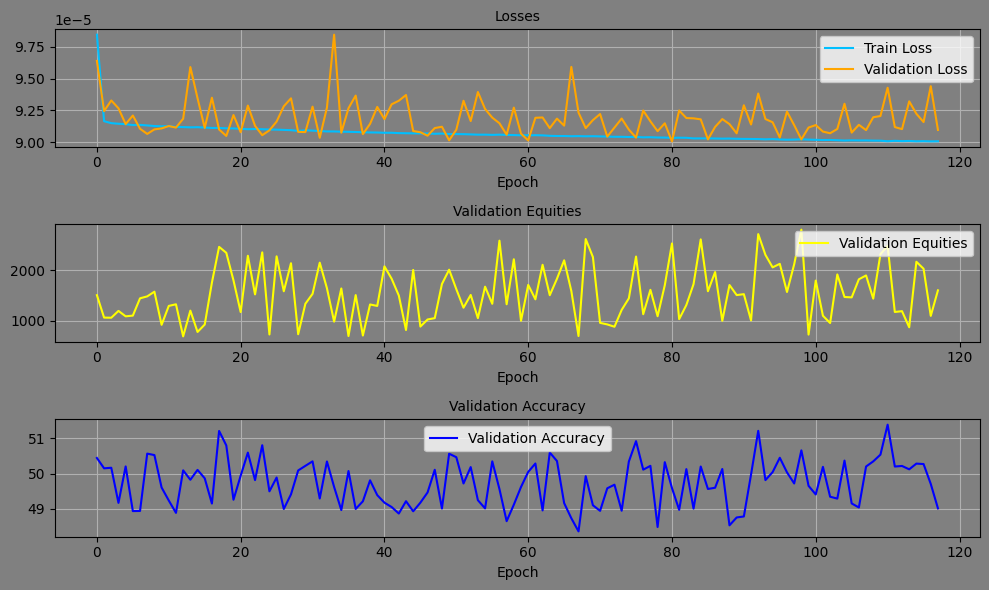

Epoch: 118, Val Equity: 1597.31, Val Accuracy: 50.62 train_losses: 0.0002828694301811305, val_losses: 9.17154029593803e-05, Duration: 0:01:13.322367


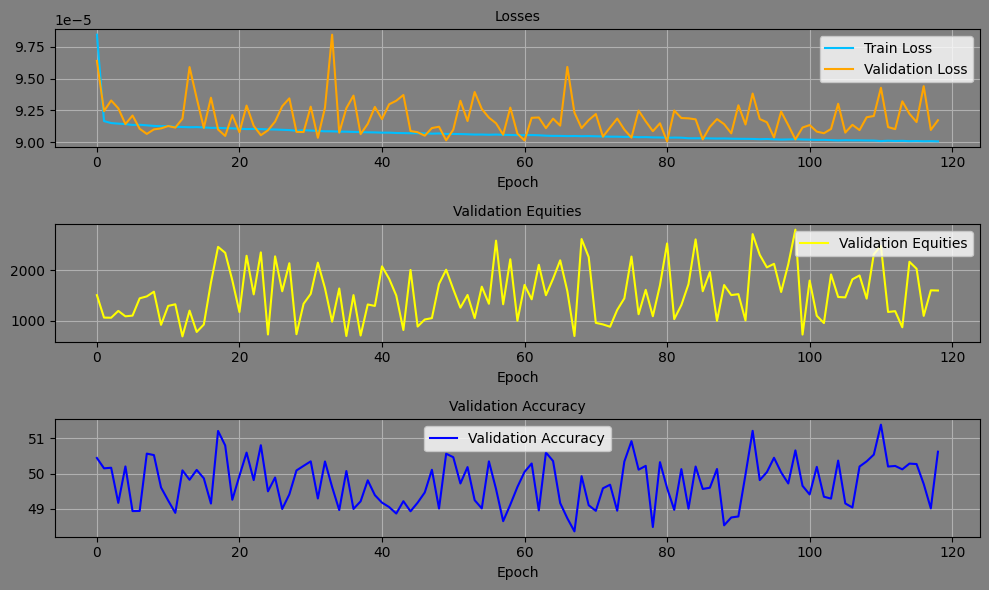

Epoch: 119, Val Equity: 1306.50, Val Accuracy: 50.11 train_losses: 0.00028290823028988244, val_losses: 9.116584260482341e-05, Duration: 0:01:08.248887


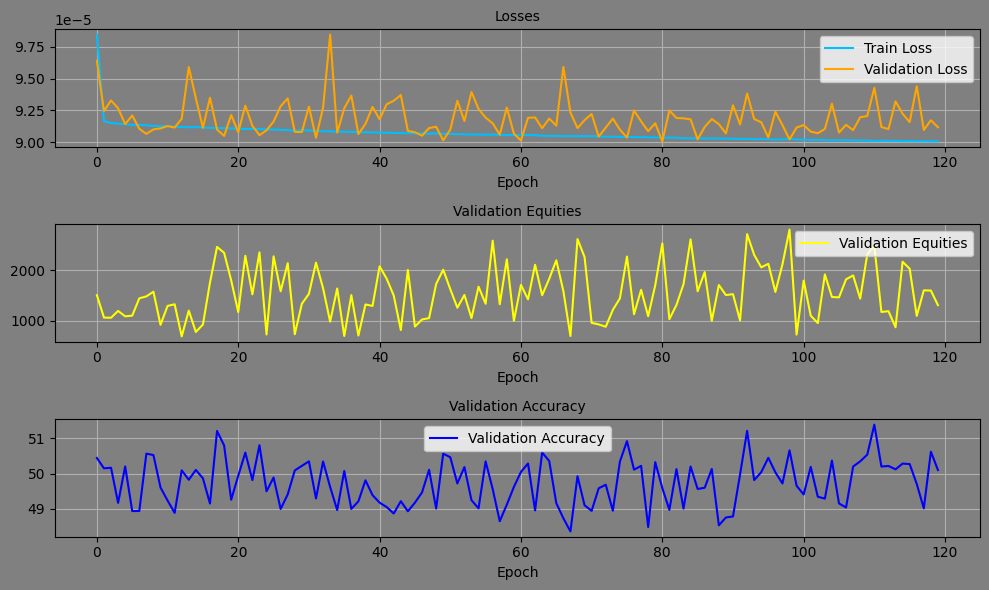

Epoch: 120, Val Equity: 1443.28, Val Accuracy: 50.37 train_losses: 0.00028279891300900364, val_losses: 9.275411139242351e-05, Duration: 0:01:08.174785


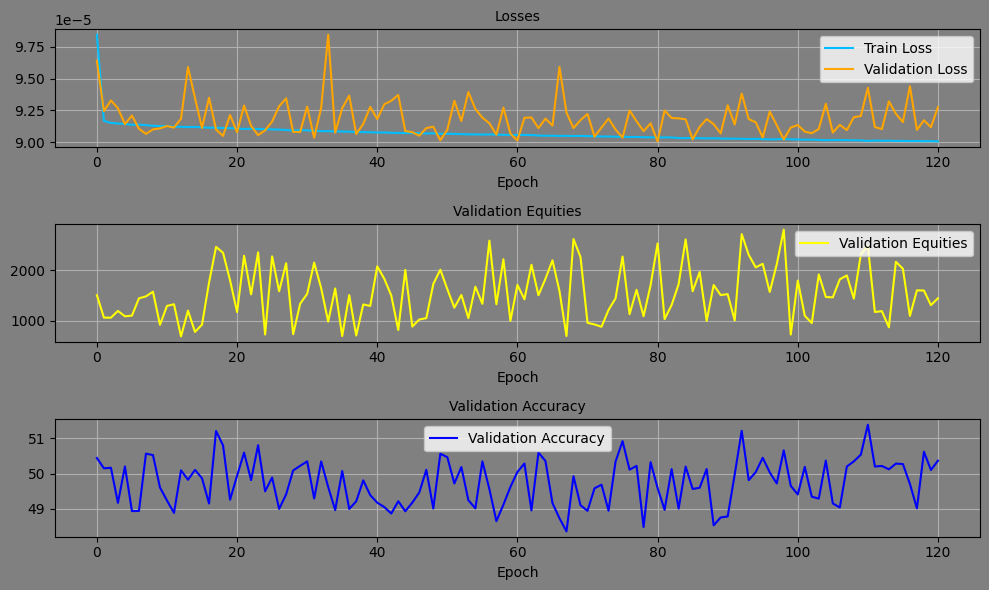

Epoch: 121, Val Equity: 2050.34, Val Accuracy: 50.85 train_losses: 0.0002829052170479771, val_losses: 9.082764881895855e-05, Duration: 0:01:09.552739


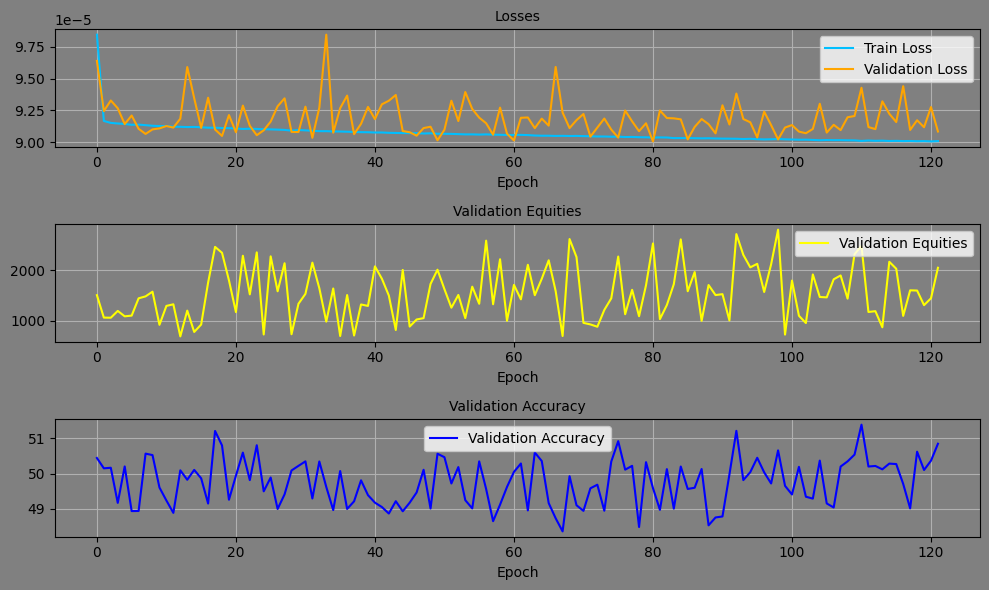

Epoch: 122, Val Equity: 1033.15, Val Accuracy: 50.14 train_losses: 0.00028272013523709895, val_losses: 9.121667972067371e-05, Duration: 0:01:11.021621


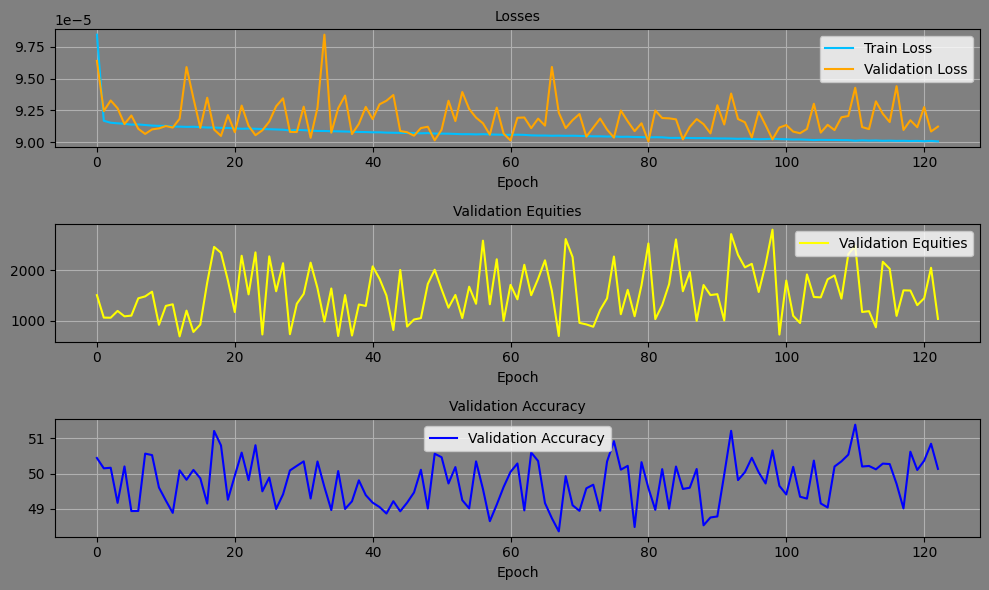

Epoch: 123, Val Equity: 1582.32, Val Accuracy: 50.54 train_losses: 0.00028281550318827914, val_losses: 9.13956537260674e-05, Duration: 0:01:08.122305


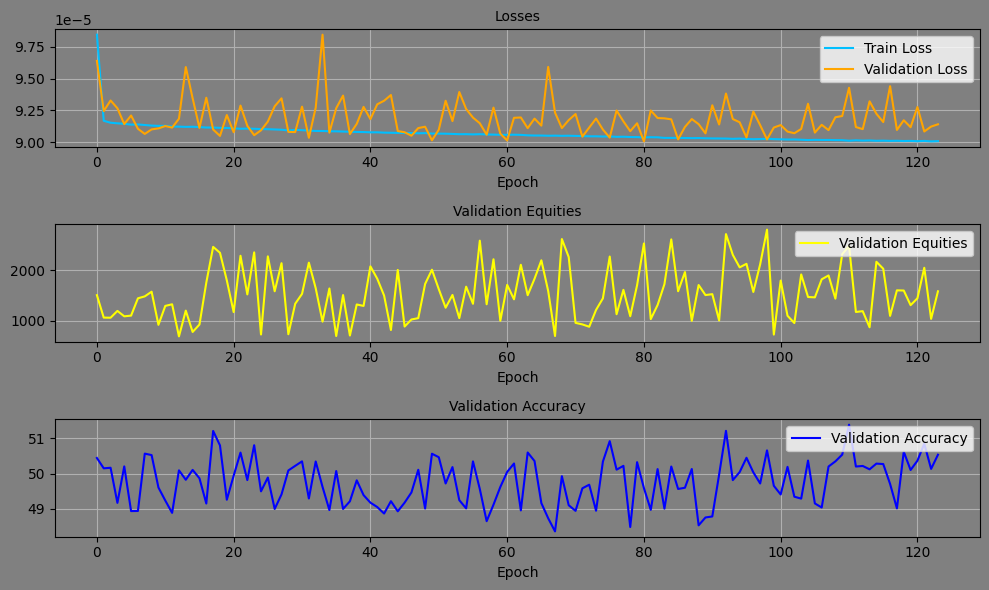

Epoch: 124, Val Equity: 1401.11, Val Accuracy: 48.89 train_losses: 0.00028270927970474875, val_losses: 9.221739310305566e-05, Duration: 0:01:08.298377


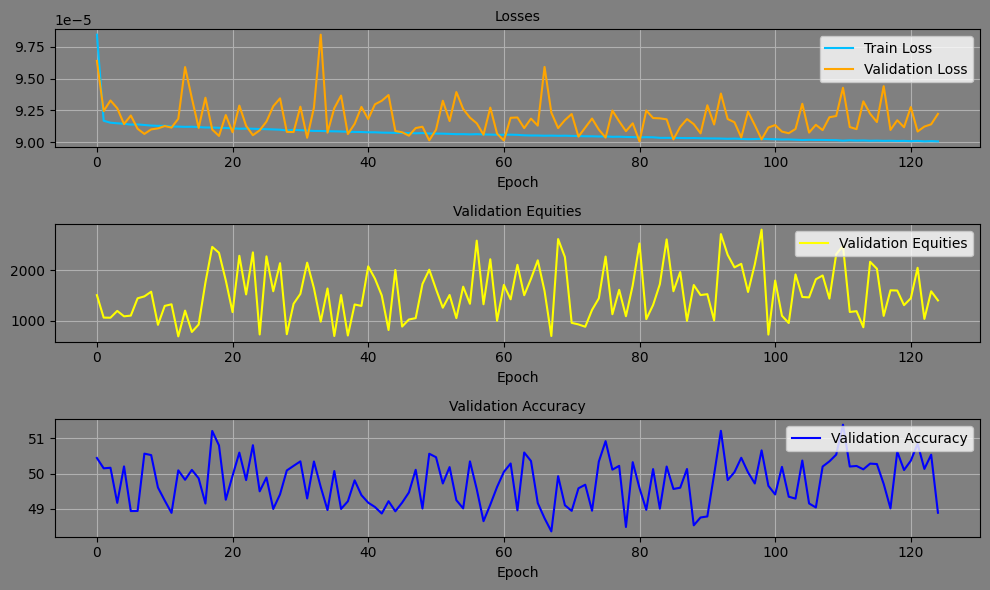

Epoch: 125, Val Equity: 1900.39, Val Accuracy: 50.39 train_losses: 0.0002827943941503794, val_losses: 9.259976650355384e-05, Duration: 0:01:07.754576


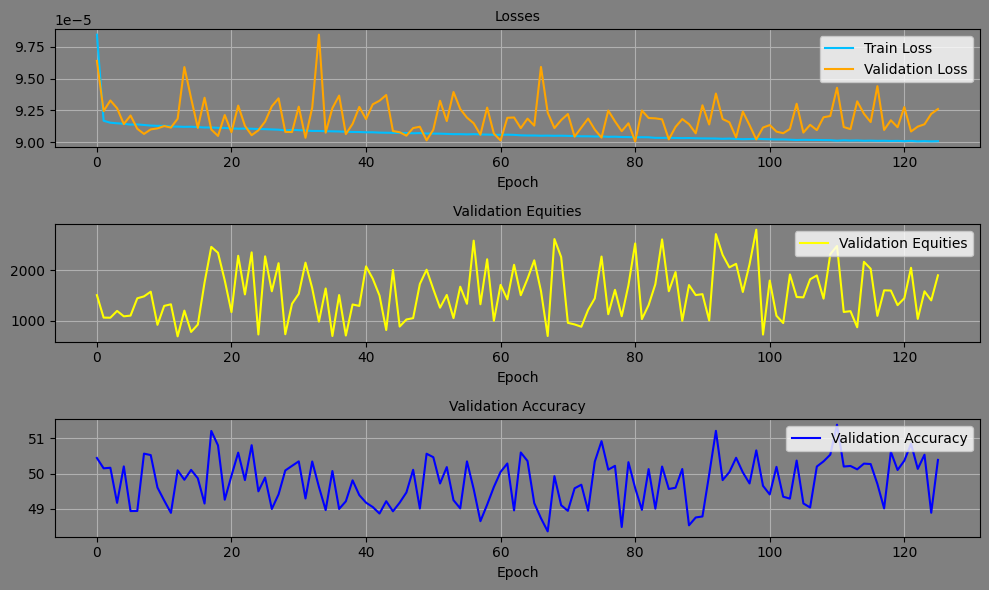

Epoch: 126, Val Equity: 1786.68, Val Accuracy: 50.68 train_losses: 0.0002828046297950798, val_losses: 9.11537281353958e-05, Duration: 0:01:08.095333


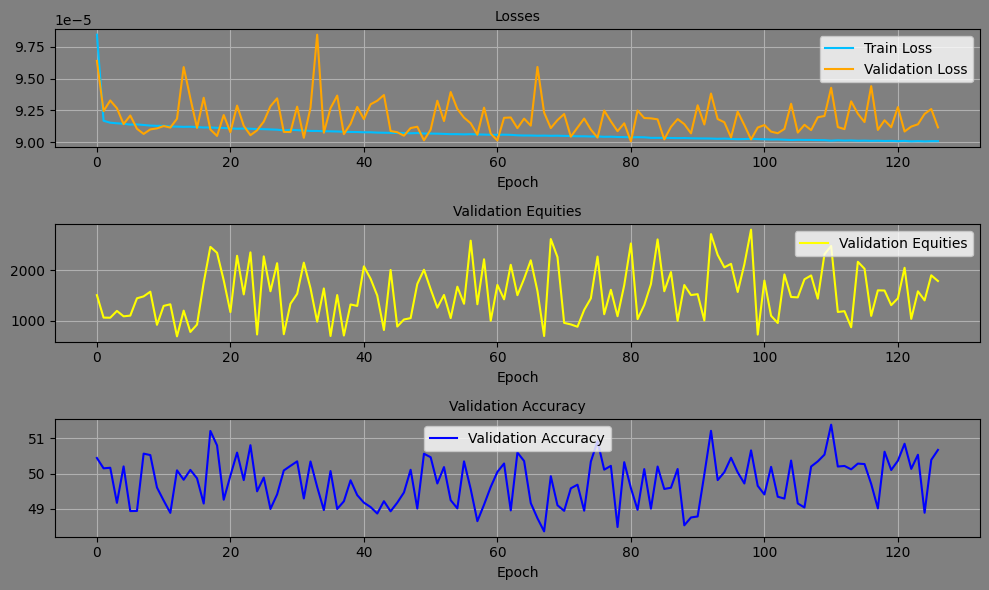

Epoch: 127, Val Equity: 1664.80, Val Accuracy: 49.49 train_losses: 0.0002827223644076887, val_losses: 9.134660649579018e-05, Duration: 0:01:08.255658


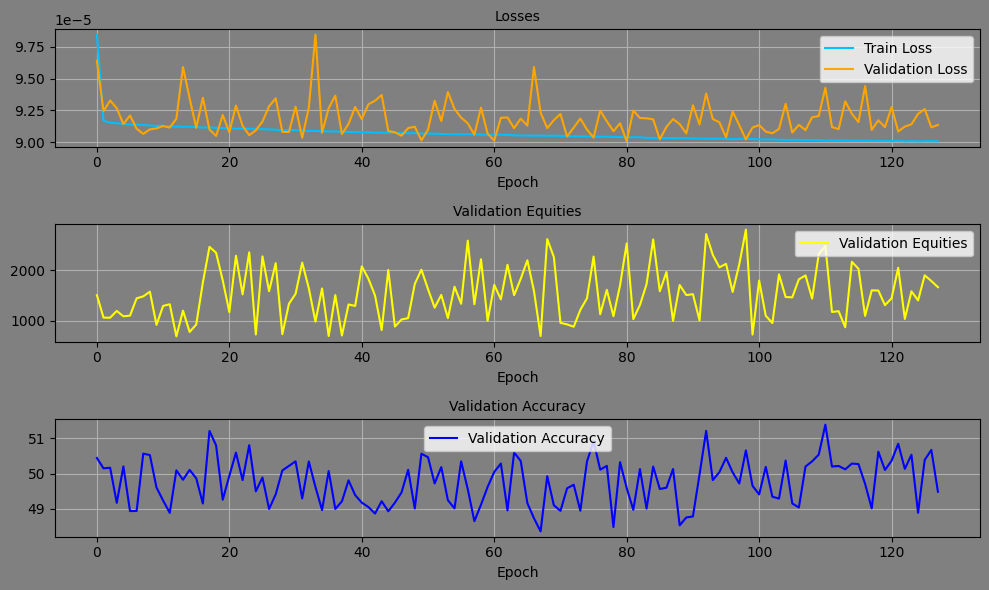

Epoch: 128, Val Equity: 853.75, Val Accuracy: 50.12 train_losses: 0.000282783922394292, val_losses: 9.41555917961523e-05, Duration: 0:01:08.058433


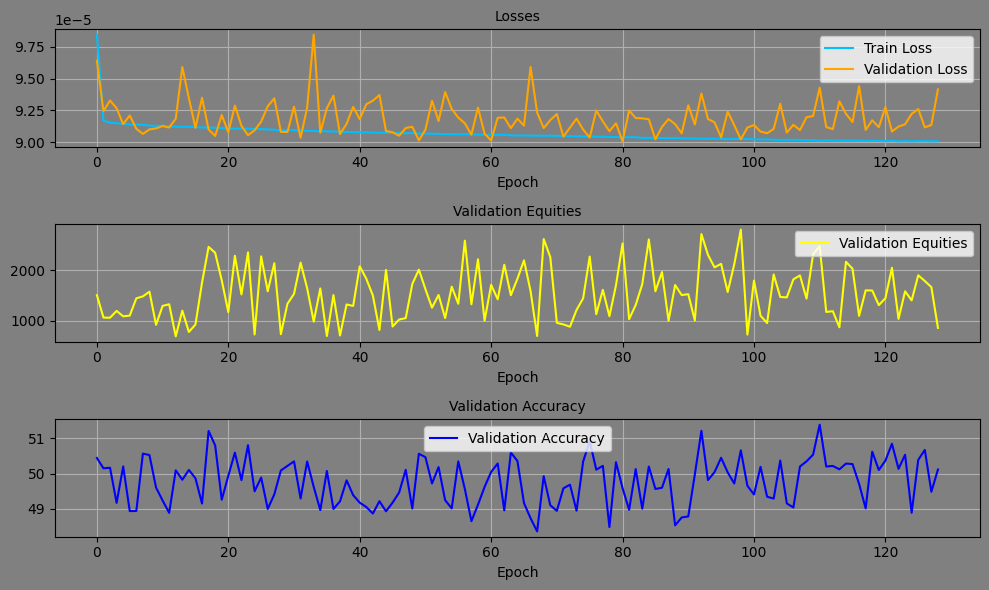

Epoch: 129, Val Equity: 1215.03, Val Accuracy: 48.47 train_losses: 0.0002825055405329605, val_losses: 9.145337389782071e-05, Duration: 0:01:07.917873


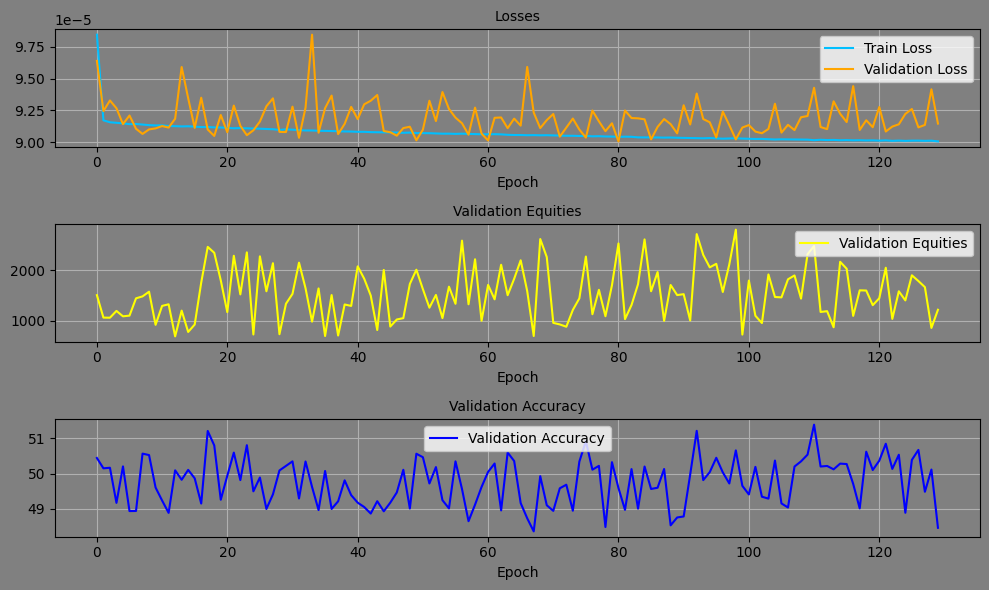

Epoch: 130, Val Equity: 1845.84, Val Accuracy: 49.25 train_losses: 0.00028264717909687683, val_losses: 9.108135418500751e-05, Duration: 0:01:08.372902


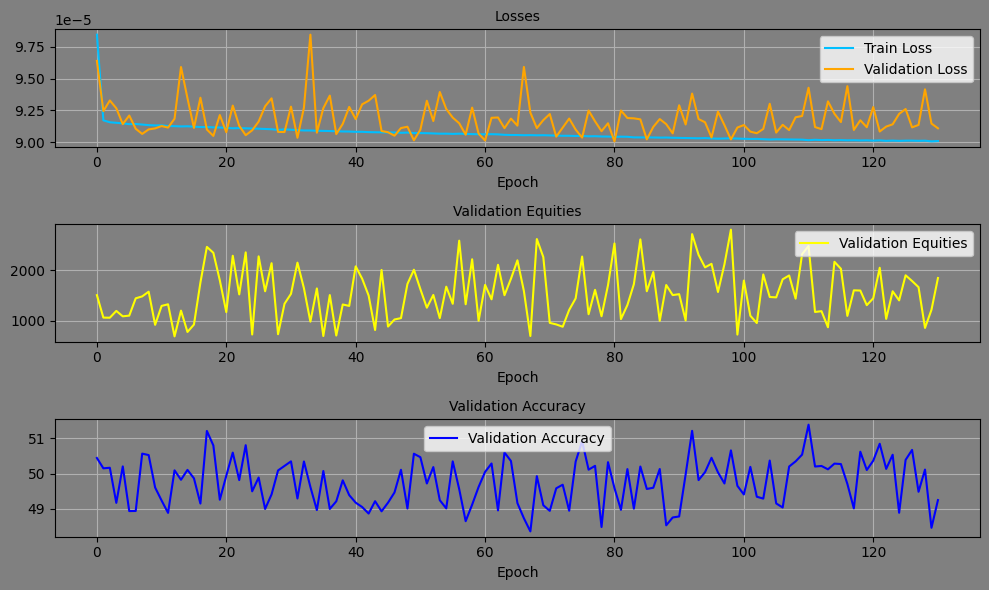

Epoch: 131, Val Equity: 1892.50, Val Accuracy: 50.87 train_losses: 0.0002825775189931824, val_losses: 9.254958422388881e-05, Duration: 0:01:08.170729


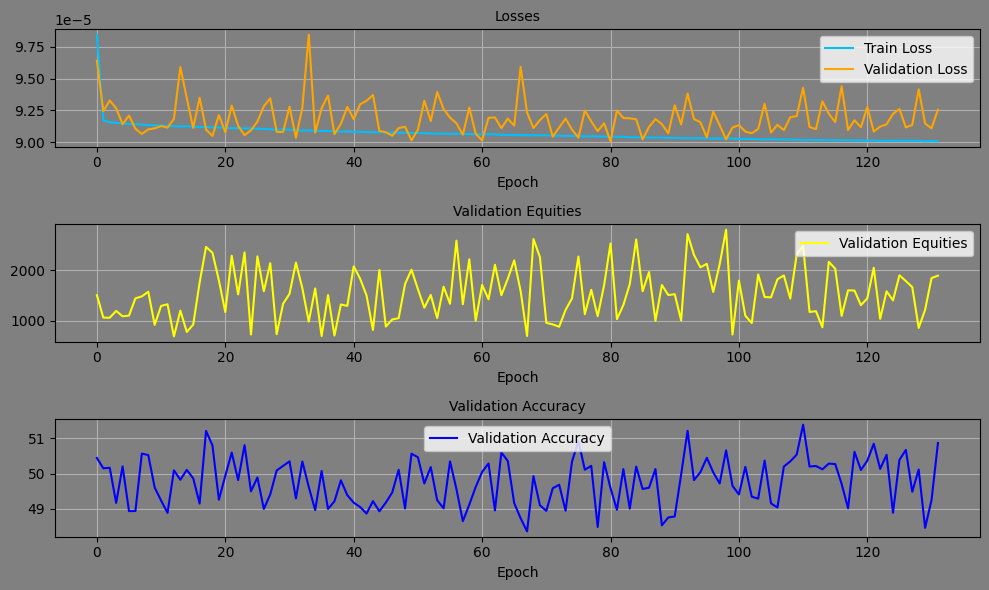

Epoch: 132, Val Equity: 1765.86, Val Accuracy: 50.63 train_losses: 0.00028255063763734555, val_losses: 9.323171980213374e-05, Duration: 0:01:08.195372


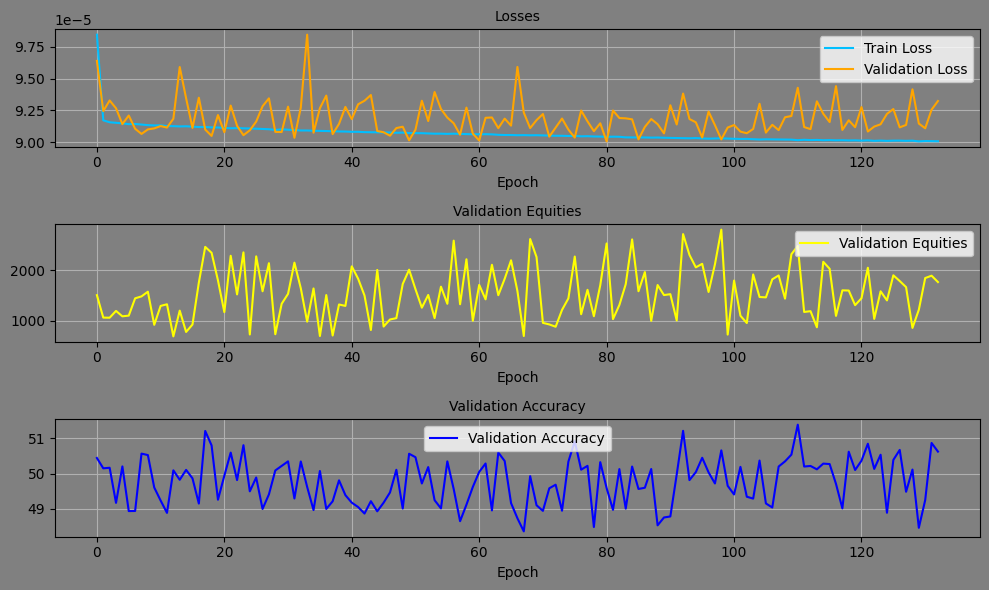

Epoch: 133, Val Equity: 1875.65, Val Accuracy: 49.03 train_losses: 0.00028251011108859457, val_losses: 9.208176925312728e-05, Duration: 0:01:07.537186


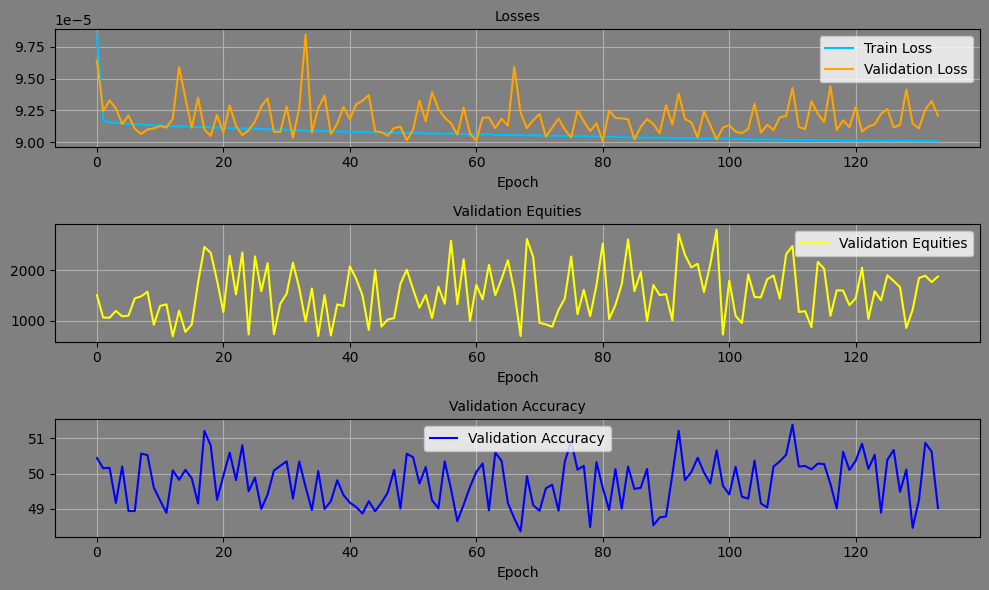

Epoch: 134, Val Equity: 1007.75, Val Accuracy: 50.23 train_losses: 0.00028262906911821826, val_losses: 9.198644693242386e-05, Duration: 0:01:08.141359


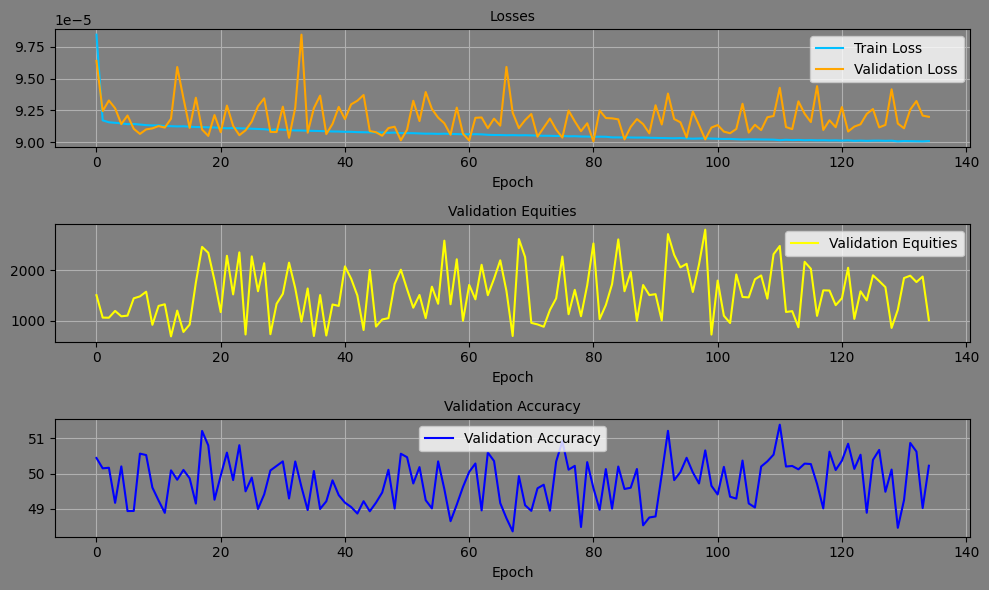

Epoch: 135, Val Equity: 1575.50, Val Accuracy: 50.75 train_losses: 0.00028259799528480405, val_losses: 9.039087308337912e-05, Duration: 0:01:08.163848


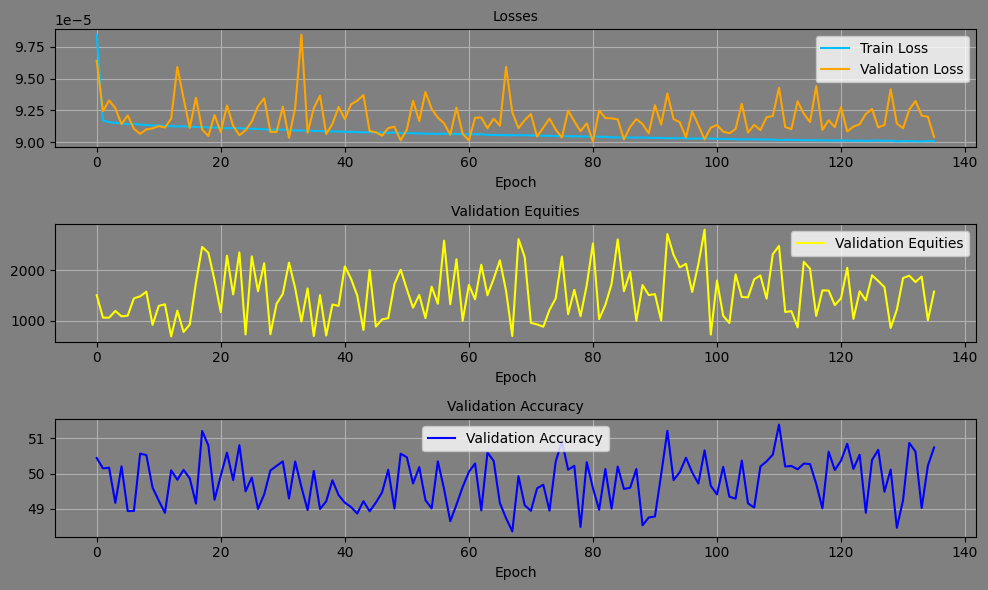

Epoch: 136, Val Equity: 2700.69, Val Accuracy: 51.05 train_losses: 0.0002824885548570486, val_losses: 9.123664494836703e-05, Duration: 0:01:08.059662


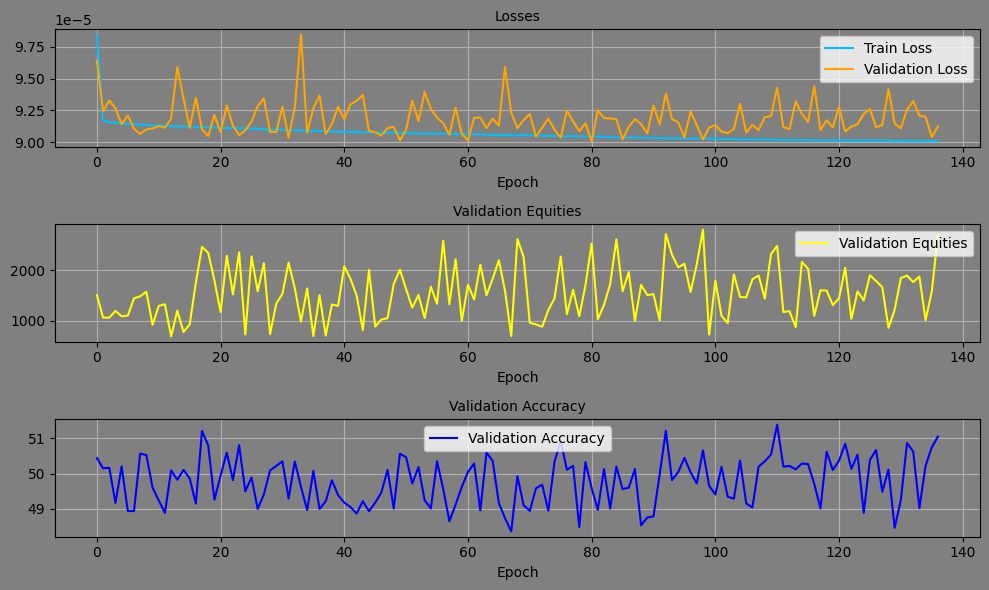

Epoch: 137, Val Equity: 2330.77, Val Accuracy: 50.32 train_losses: 0.0002824171347064168, val_losses: 9.237786434823647e-05, Duration: 0:01:08.388049


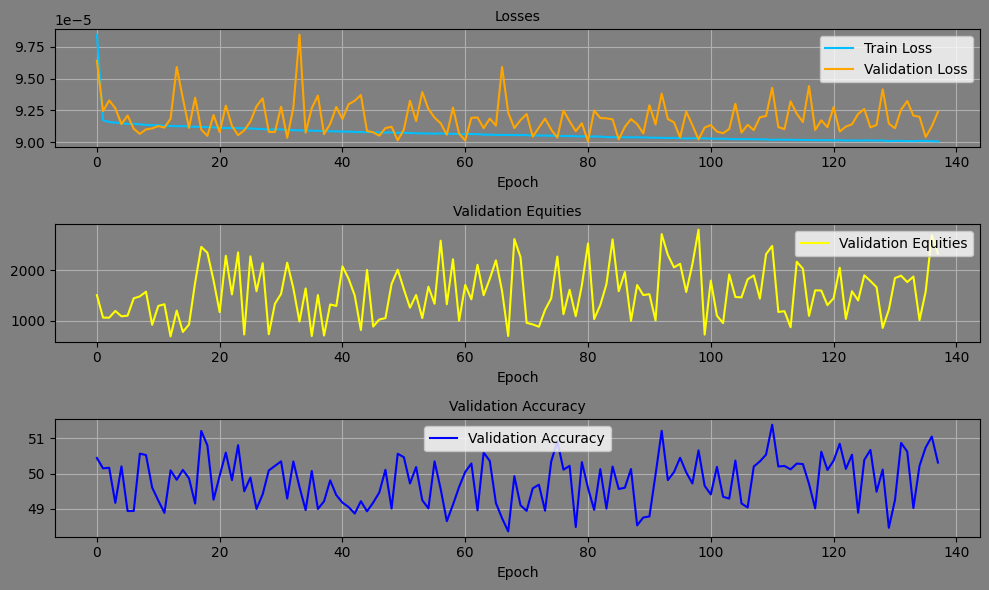

Epoch: 138, Val Equity: 714.92, Val Accuracy: 48.70 train_losses: 0.000282310154019098, val_losses: 9.097035945160314e-05, Duration: 0:01:08.028848


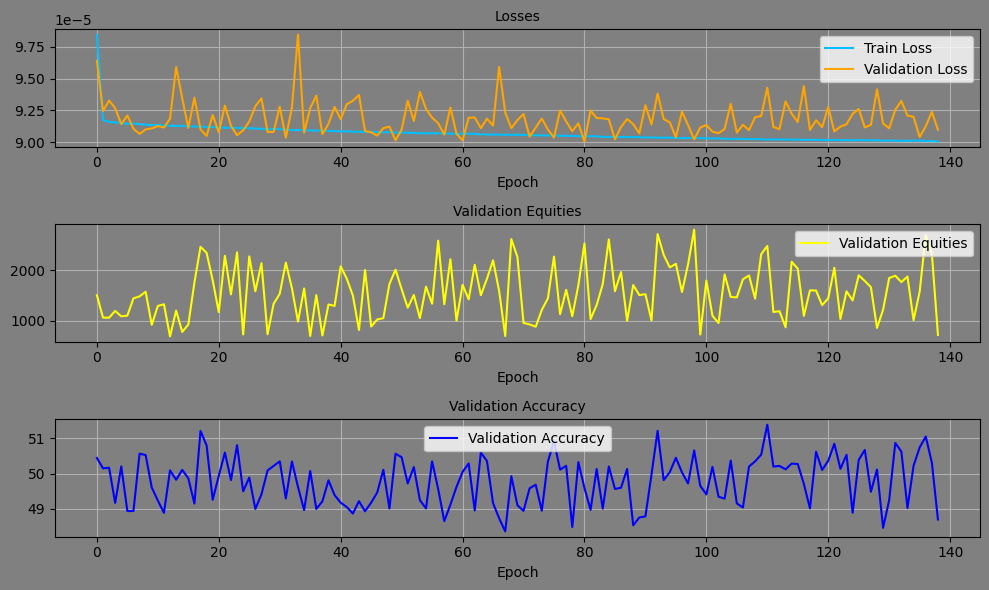

Epoch: 139, Val Equity: 1770.32, Val Accuracy: 50.81 train_losses: 0.00028240838171415627, val_losses: 9.064078039955348e-05, Duration: 0:01:08.069631


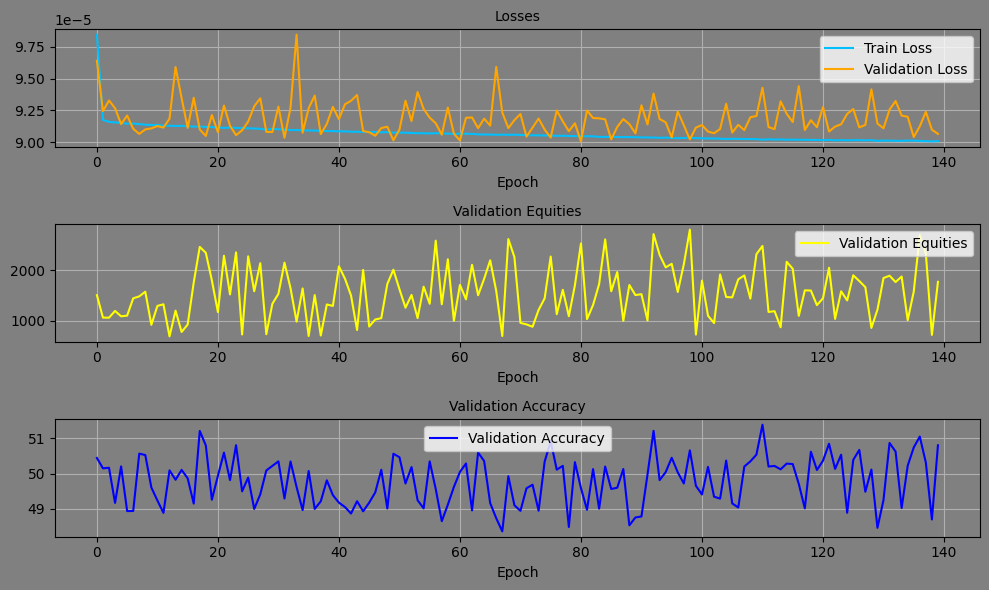

Epoch: 140, Val Equity: 1843.85, Val Accuracy: 49.15 train_losses: 0.00028255327833718864, val_losses: 9.166470408672467e-05, Duration: 0:01:08.048254


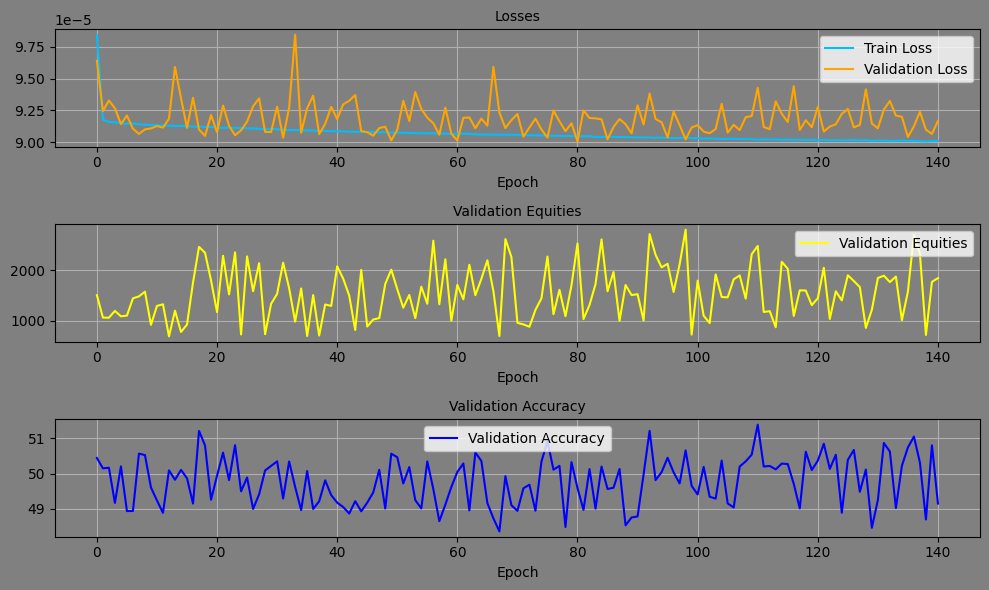

Epoch: 141, Val Equity: 2444.64, Val Accuracy: 51.03 train_losses: 0.0002824029079743642, val_losses: 9.103642514673993e-05, Duration: 0:01:07.748990


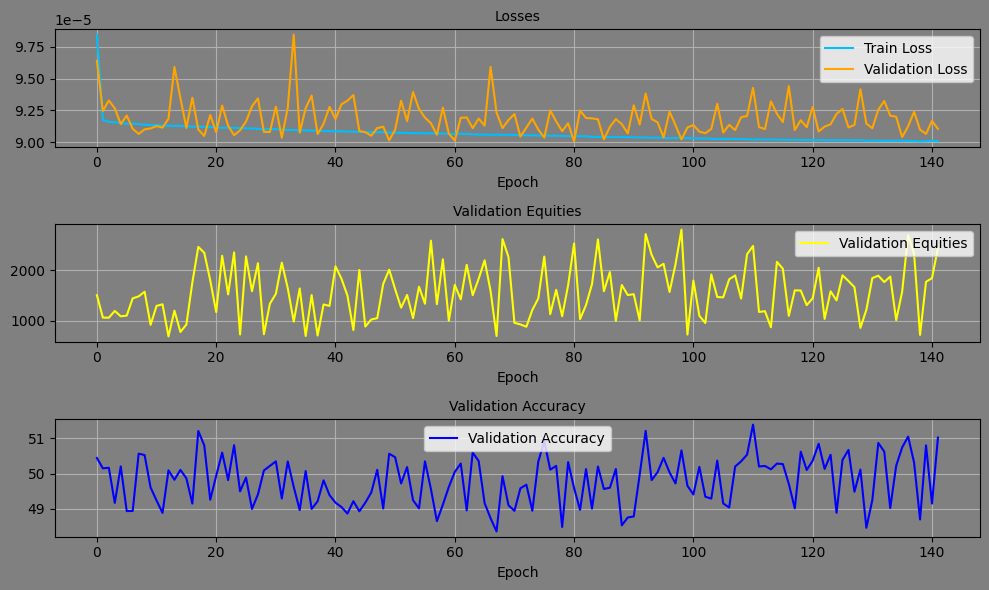

Epoch: 142, Val Equity: 1053.87, Val Accuracy: 50.15 train_losses: 0.0002822031834979705, val_losses: 9.352424240205437e-05, Duration: 0:01:07.878281


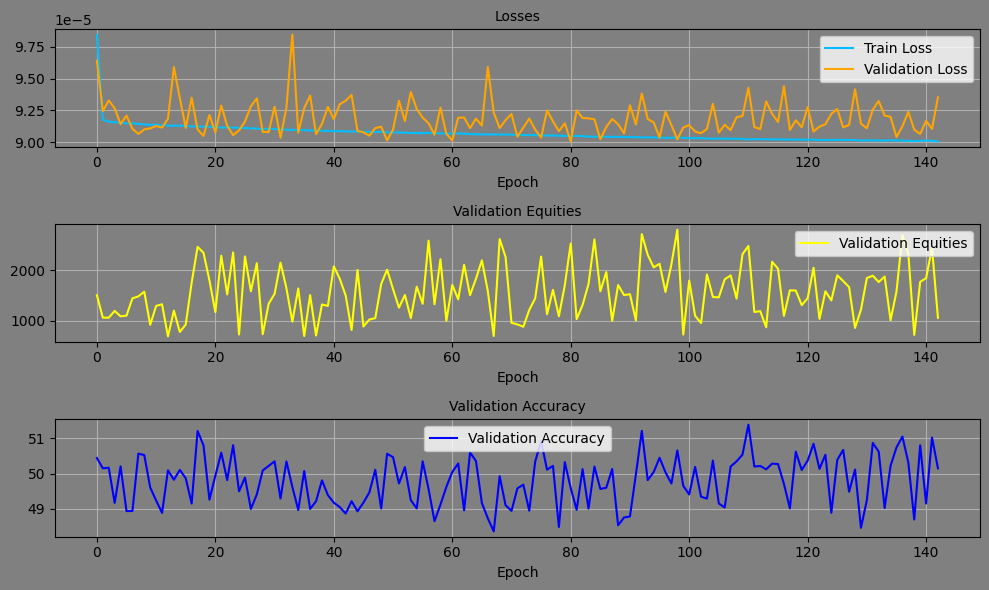

Epoch: 143, Val Equity: 1619.70, Val Accuracy: 50.59 train_losses: 0.0002824193113305804, val_losses: 9.120890899794176e-05, Duration: 0:01:08.058197


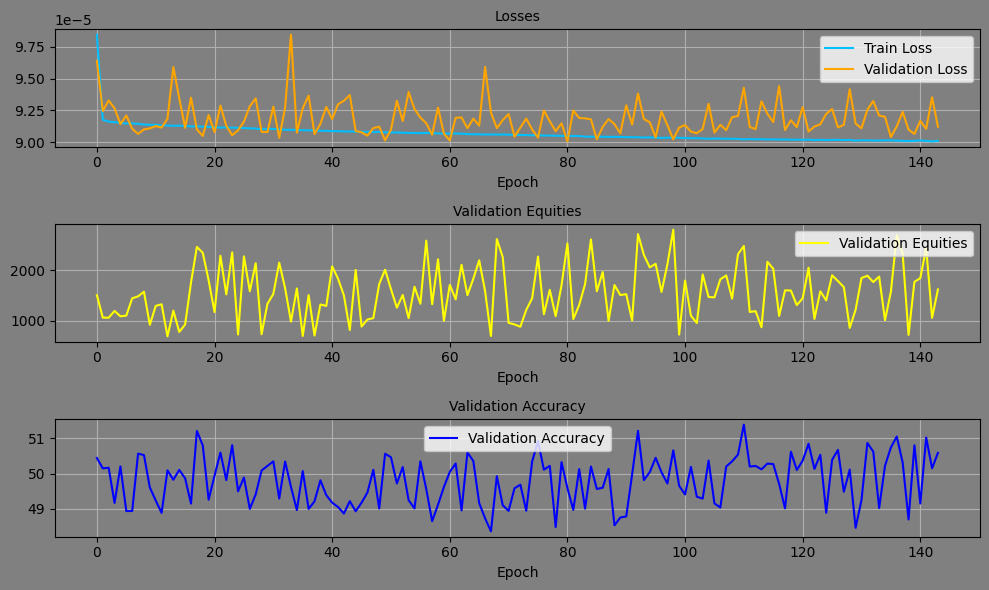

Epoch: 144, Val Equity: 1544.08, Val Accuracy: 48.97 train_losses: 0.0002824975943031689, val_losses: 9.355298971058801e-05, Duration: 0:01:10.593363


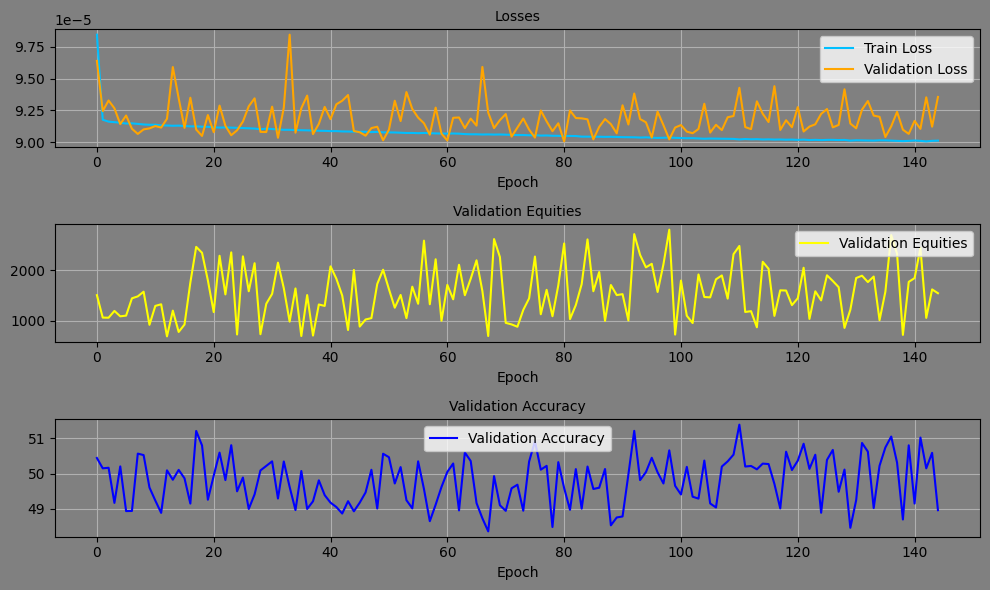

Epoch: 145, Val Equity: 1782.75, Val Accuracy: 50.57 train_losses: 0.00028233744365255975, val_losses: 9.058722935151309e-05, Duration: 0:01:07.951024


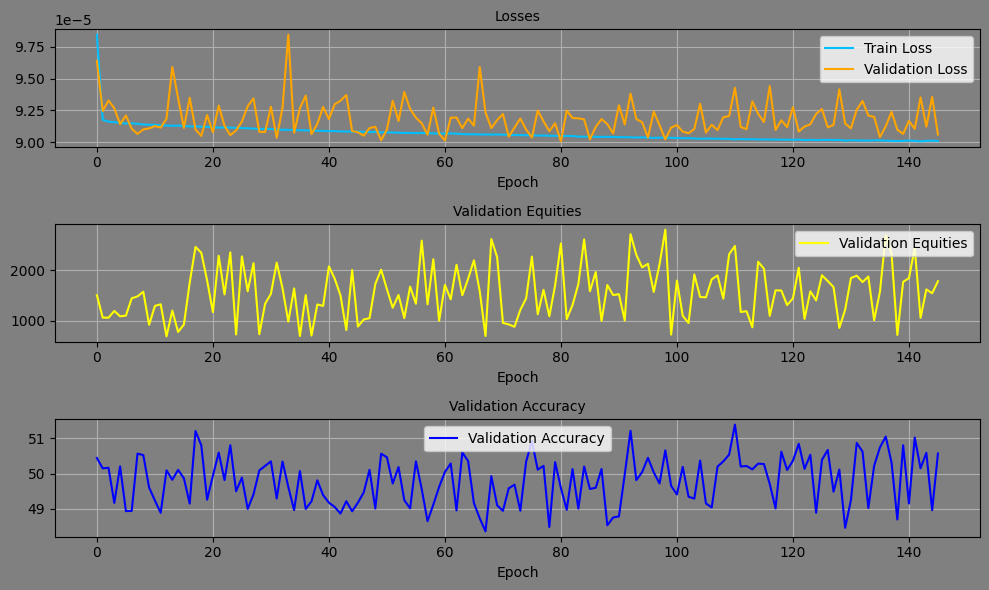

Epoch: 146, Val Equity: 2081.20, Val Accuracy: 49.66 train_losses: 0.00028234543345167655, val_losses: 9.130587568506598e-05, Duration: 0:01:08.020886


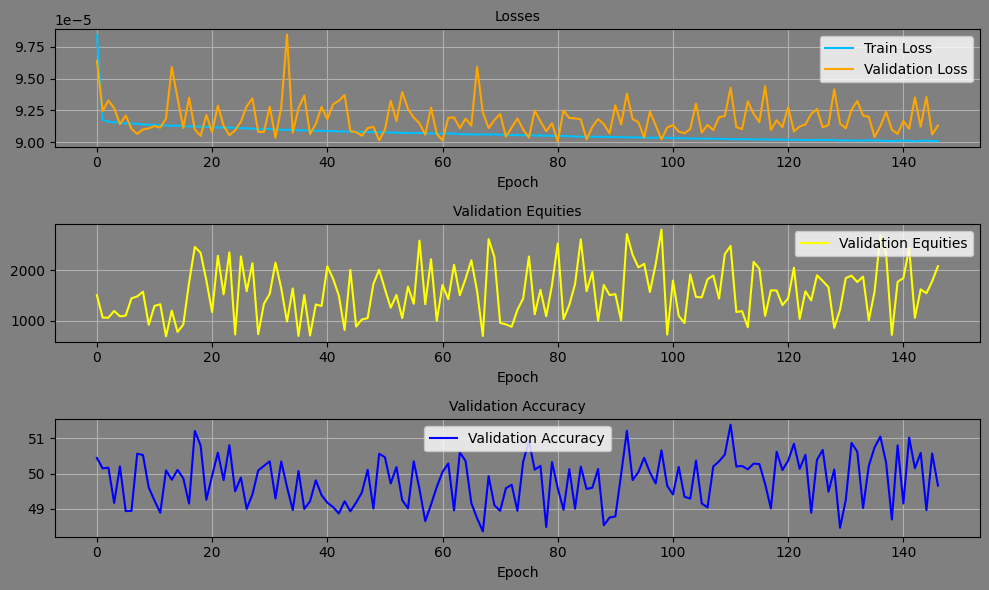

Epoch: 147, Val Equity: 1678.74, Val Accuracy: 50.87 train_losses: 0.0002822726718920229, val_losses: 9.096477879211307e-05, Duration: 0:01:08.261394


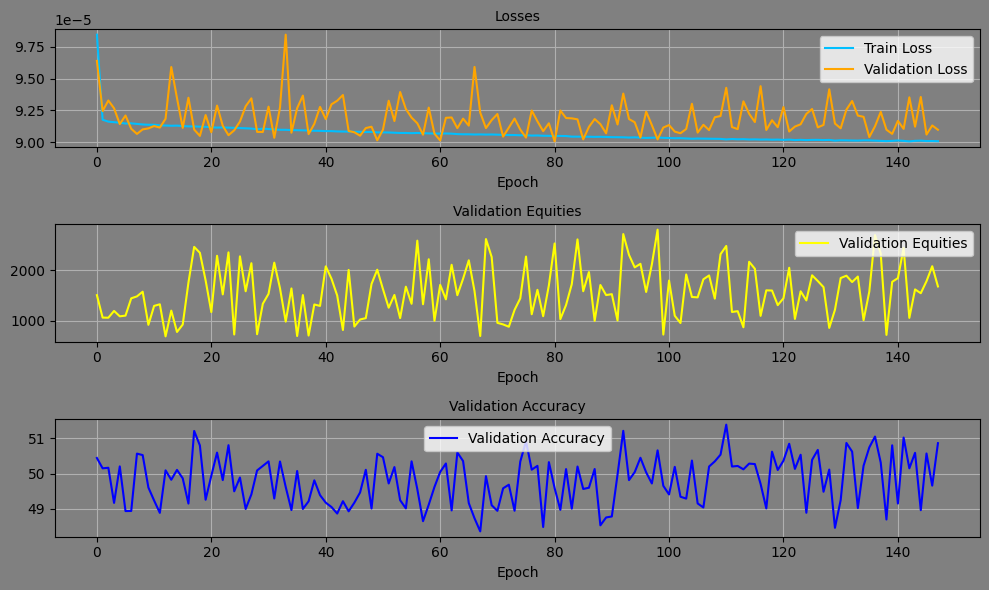

Epoch: 148, Val Equity: 1559.65, Val Accuracy: 49.37 train_losses: 0.0002822591565354853, val_losses: 9.115392458625138e-05, Duration: 0:01:08.204157


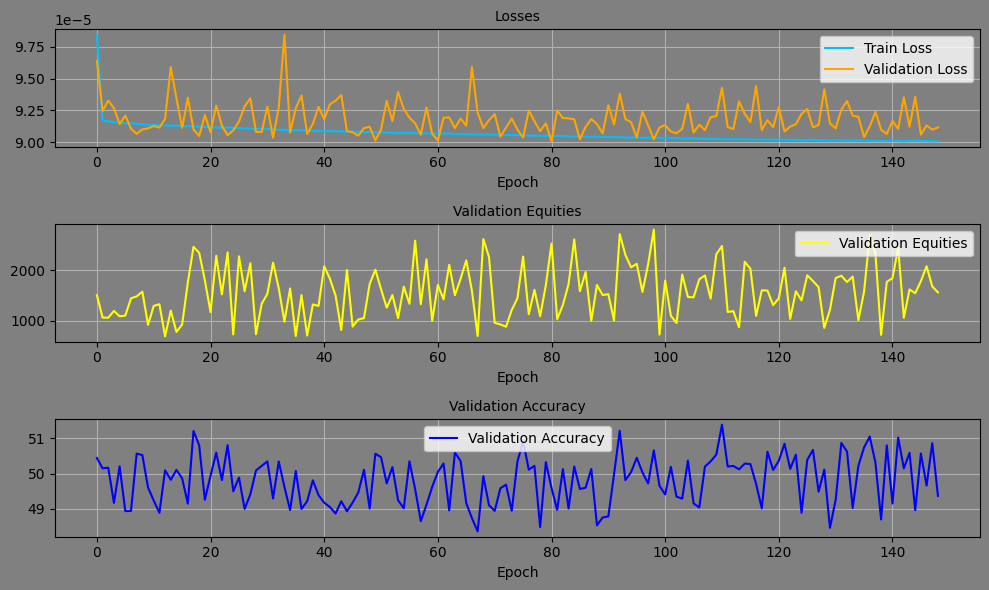

Epoch: 149, Val Equity: 1526.14, Val Accuracy: 50.37 train_losses: 0.00028222974927069936, val_losses: 9.194535959977657e-05, Duration: 0:01:07.812748


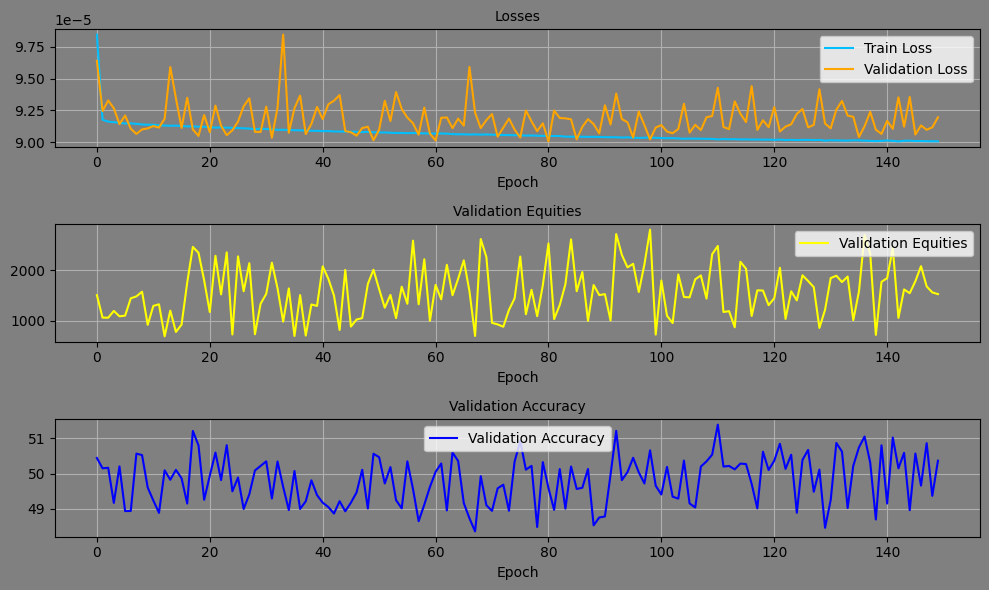

Epoch: 150, Val Equity: 1603.77, Val Accuracy: 49.18 train_losses: 0.000282169366149757, val_losses: 9.085409692488611e-05, Duration: 0:01:08.301387


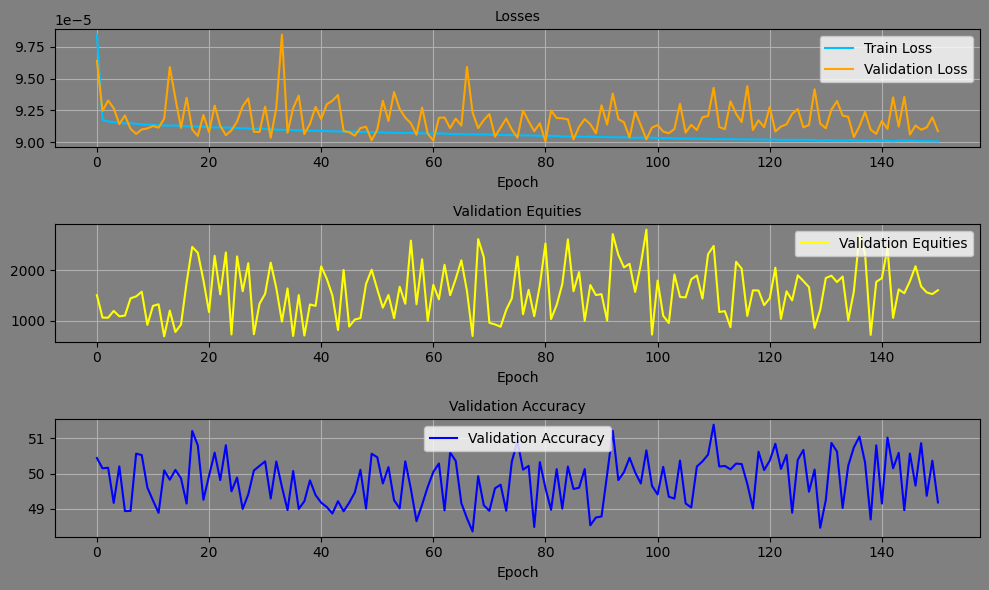

Epoch: 151, Val Equity: 2229.88, Val Accuracy: 51.00 train_losses: 0.00028231076901220594, val_losses: 9.038875577971339e-05, Duration: 0:01:08.042759


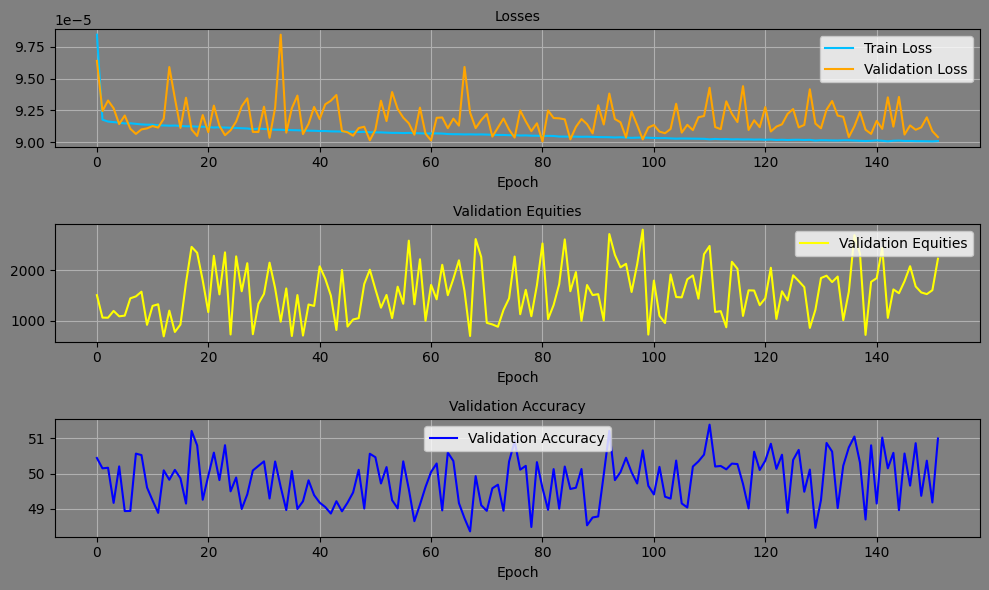

Epoch: 152, Val Equity: 1281.20, Val Accuracy: 50.19 train_losses: 0.00028218009505530416, val_losses: 9.26018474274315e-05, Duration: 0:01:07.896066


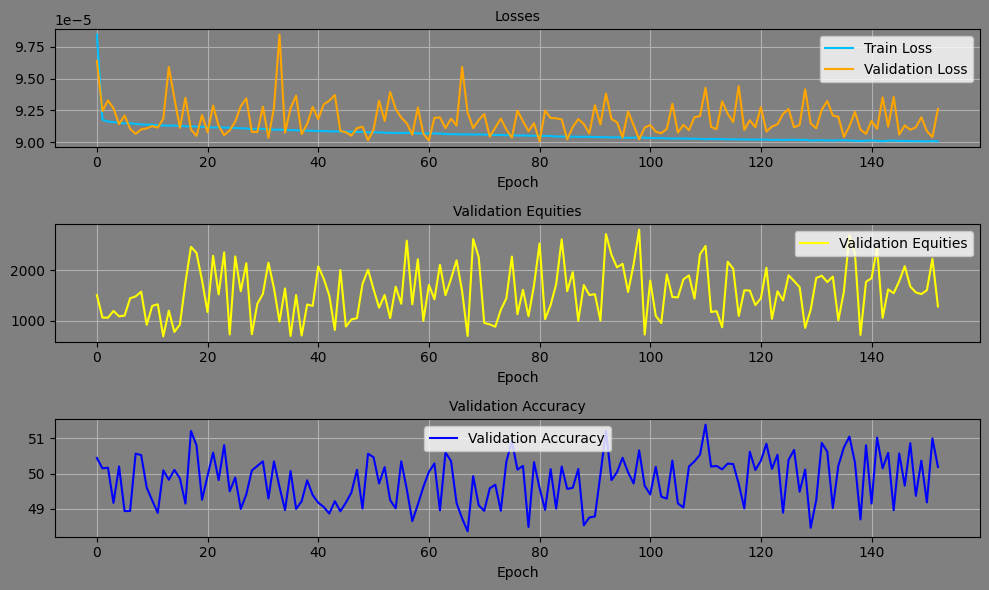

Epoch: 153, Val Equity: 1358.59, Val Accuracy: 50.43 train_losses: 0.0002822491873741189, val_losses: 9.06960922293365e-05, Duration: 0:01:08.176271


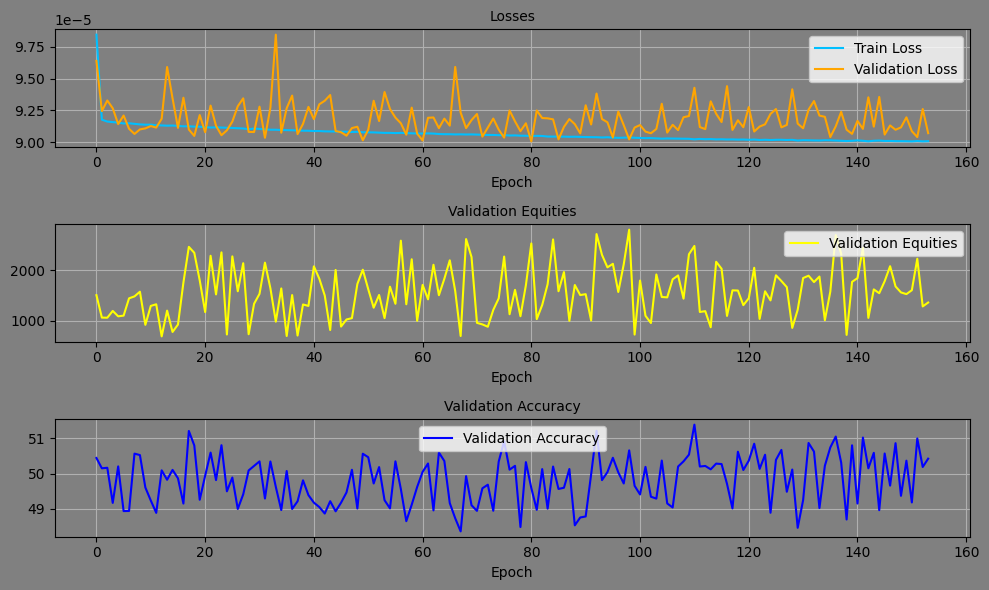

Epoch: 154, Val Equity: 1101.05, Val Accuracy: 50.19 train_losses: 0.00028229446995996617, val_losses: 9.12007235456258e-05, Duration: 0:01:08.337062


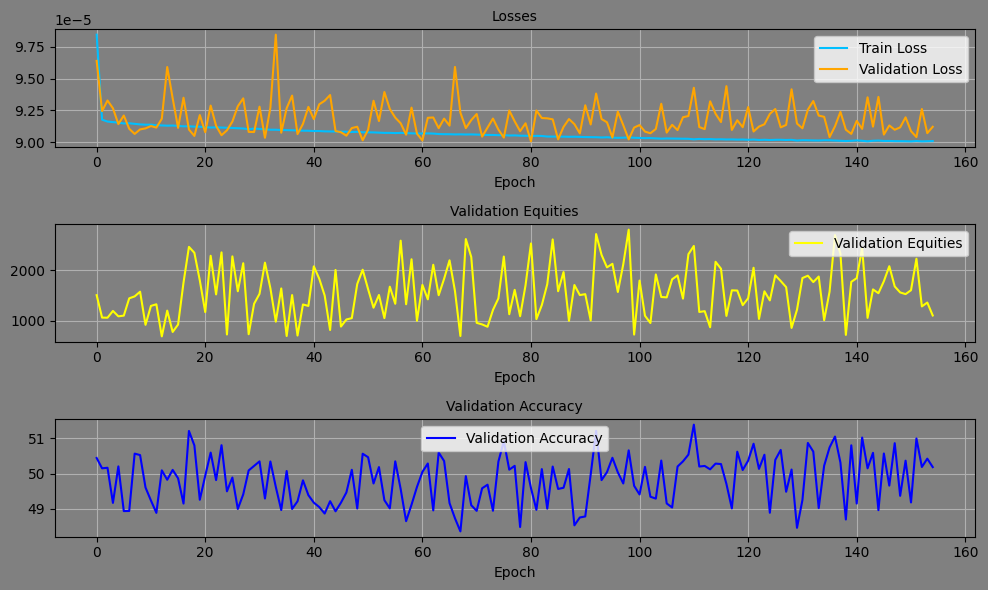

Epoch: 155, Val Equity: 1334.24, Val Accuracy: 50.61 train_losses: 0.00028213980556301976, val_losses: 9.108462108997628e-05, Duration: 0:01:08.096674


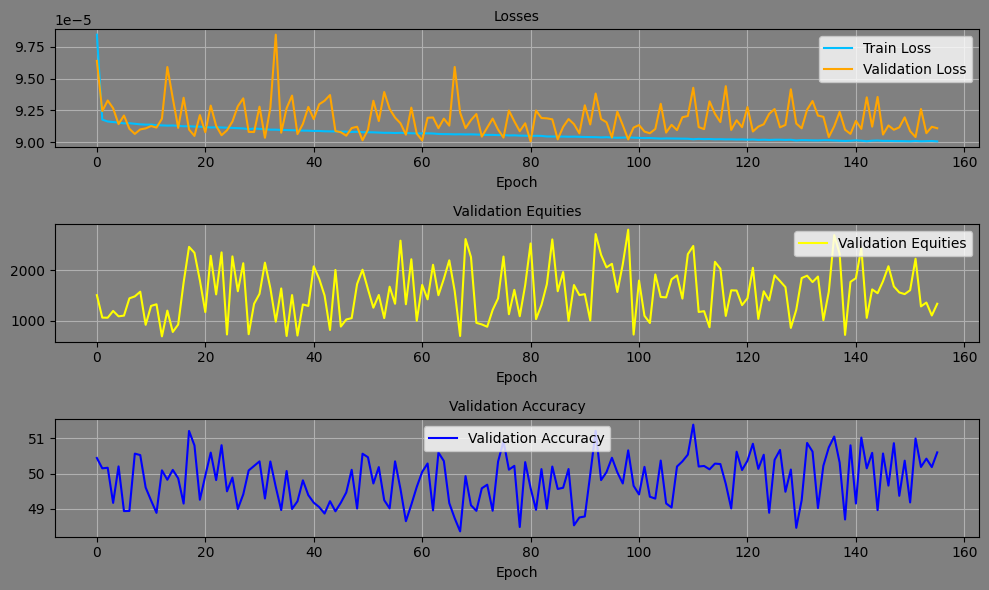

Epoch: 156, Val Equity: 1750.54, Val Accuracy: 49.45 train_losses: 0.00028221616851973653, val_losses: 9.187764226226136e-05, Duration: 0:01:07.726904


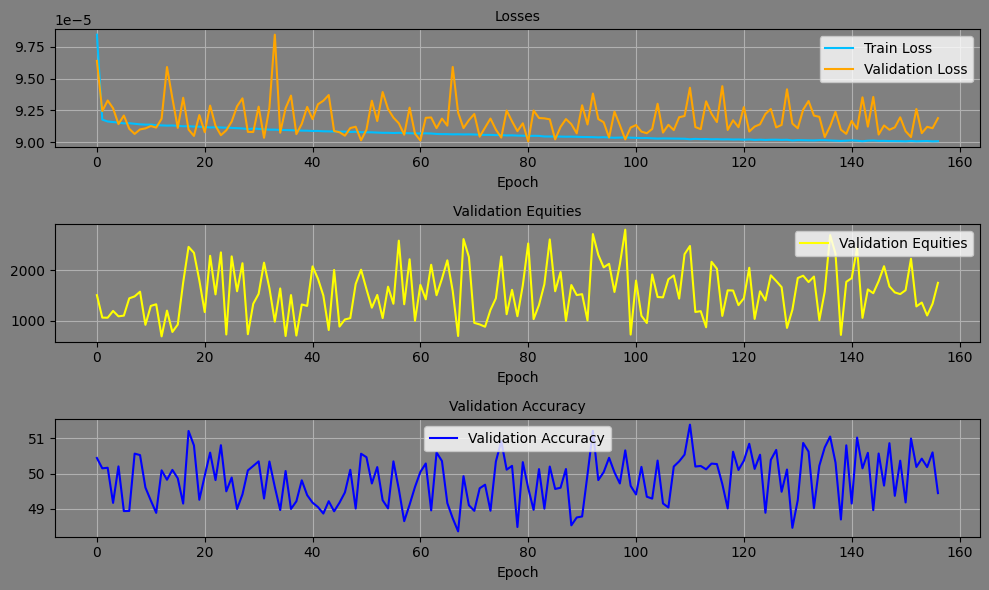

Epoch: 157, Val Equity: 2090.30, Val Accuracy: 51.57 train_losses: 0.0002820771933592945, val_losses: 9.09943992155604e-05, Duration: 0:01:08.093809


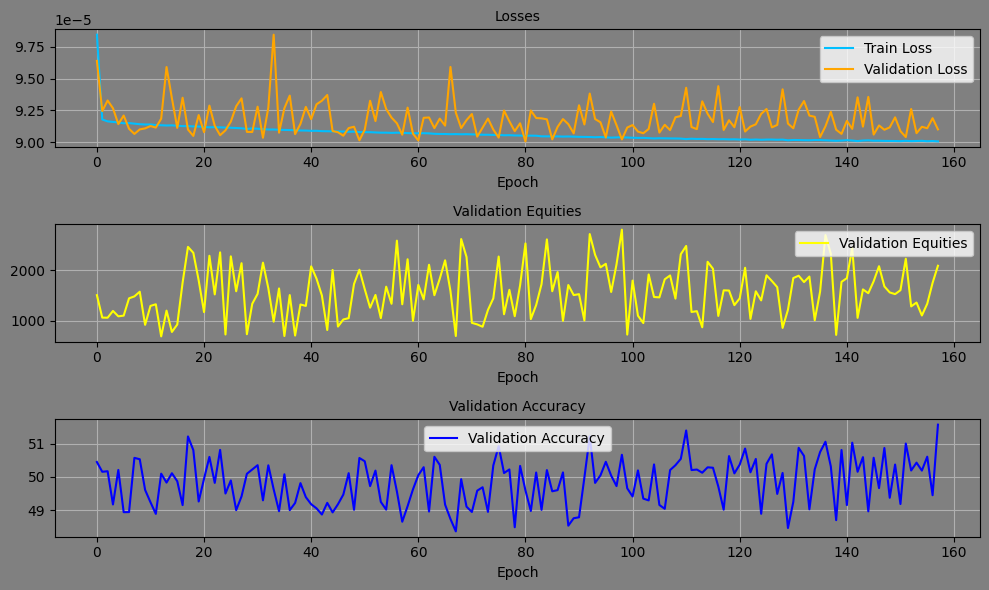

Epoch: 158, Val Equity: 1045.67, Val Accuracy: 50.27 train_losses: 0.00028215490523806936, val_losses: 9.114421845879406e-05, Duration: 0:01:10.692926


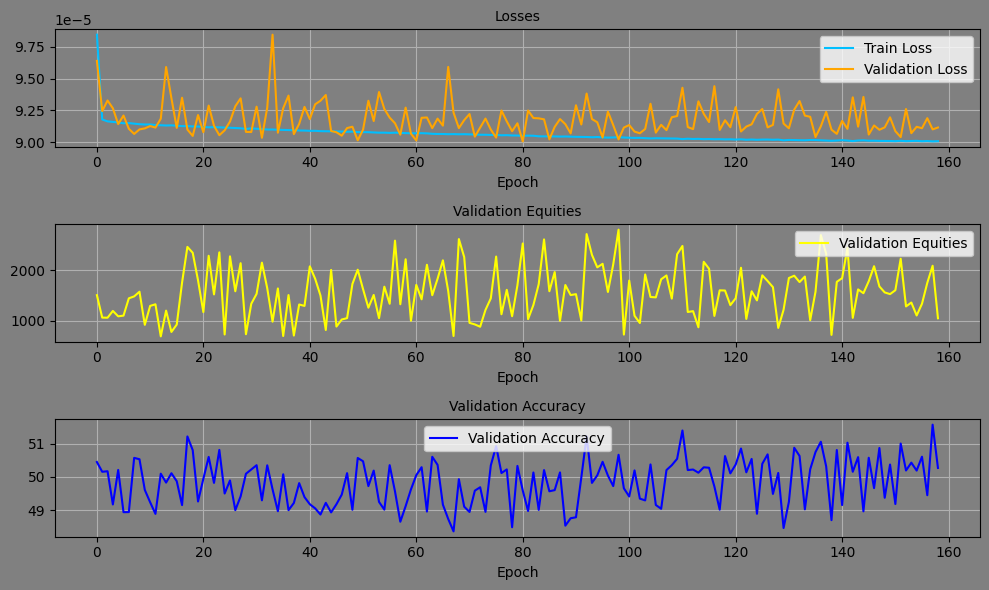

Epoch: 159, Val Equity: 1623.52, Val Accuracy: 50.77 train_losses: 0.0002819836514904674, val_losses: 9.282986866310239e-05, Duration: 0:01:08.106376


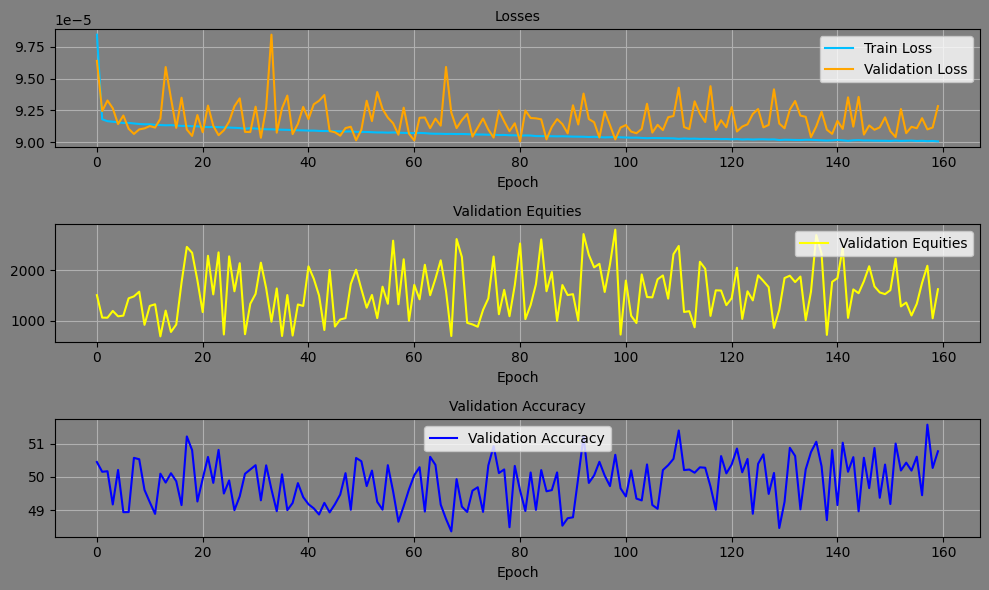

Epoch: 160, Val Equity: 1633.69, Val Accuracy: 49.20 train_losses: 0.00028207669707280657, val_losses: 9.276150376535952e-05, Duration: 0:01:07.692929


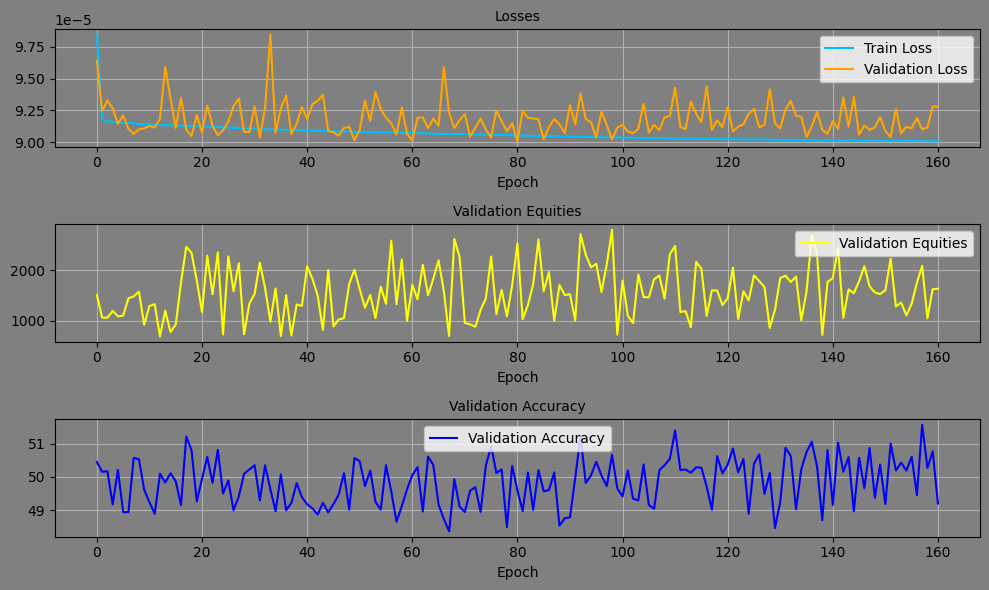

Epoch: 161, Val Equity: 1806.24, Val Accuracy: 51.16 train_losses: 0.0002820502146232869, val_losses: 9.043444879353046e-05, Duration: 0:01:08.675302


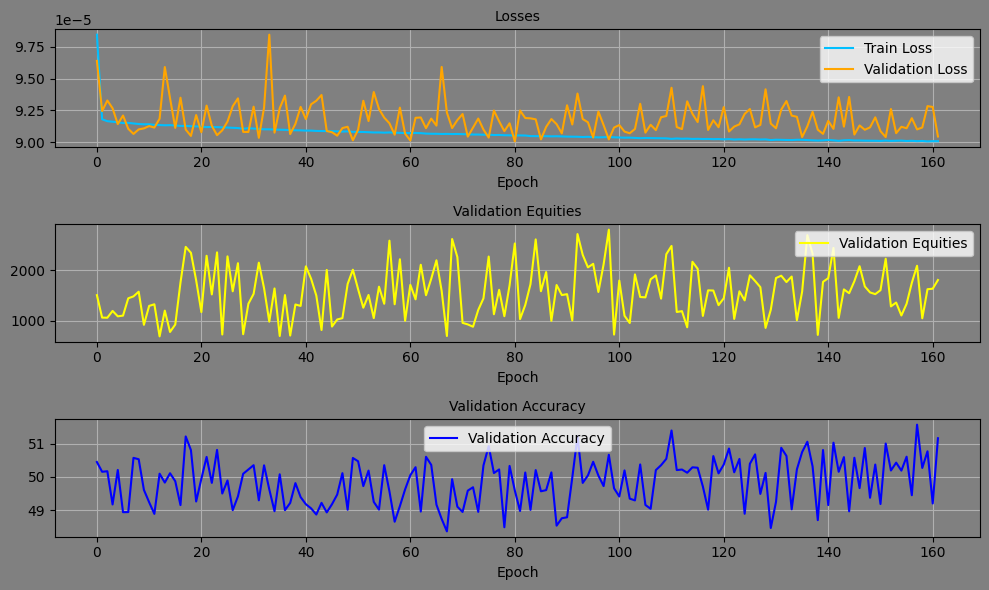

Epoch: 162, Val Equity: 1930.54, Val Accuracy: 50.85 train_losses: 0.000281986578774032, val_losses: 9.126568329520524e-05, Duration: 0:01:08.034686


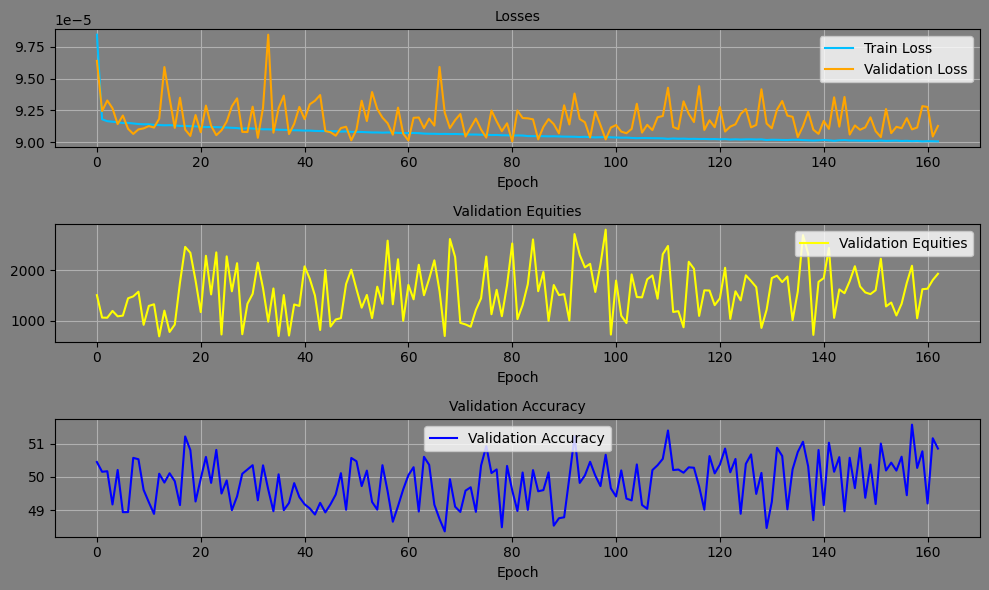

Epoch: 163, Val Equity: 2296.22, Val Accuracy: 50.70 train_losses: 0.0002819665196229872, val_losses: 9.082164615392685e-05, Duration: 0:01:07.863494


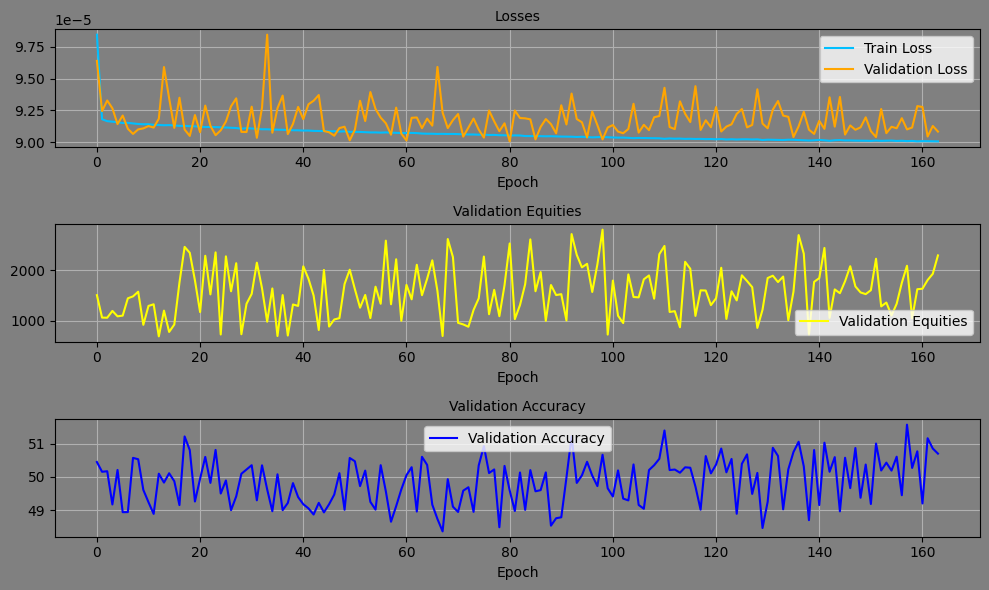

Epoch: 164, Val Equity: 737.67, Val Accuracy: 50.09 train_losses: 0.0002821385496284764, val_losses: 9.105326898861676e-05, Duration: 0:01:08.160160


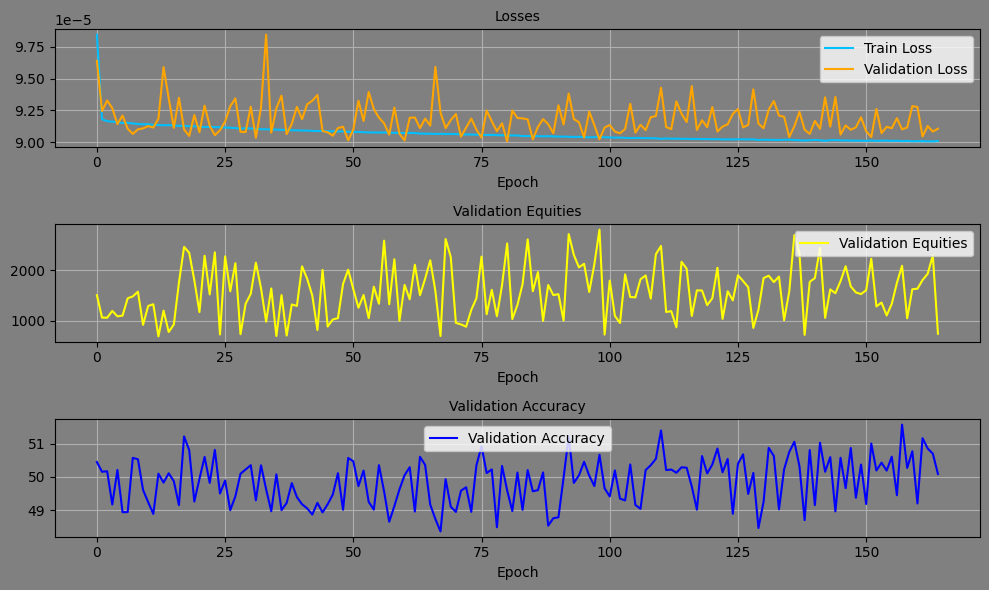

Epoch: 165, Val Equity: 1222.66, Val Accuracy: 50.20 train_losses: 0.0002820407309134983, val_losses: 9.340465476270765e-05, Duration: 0:01:08.042047


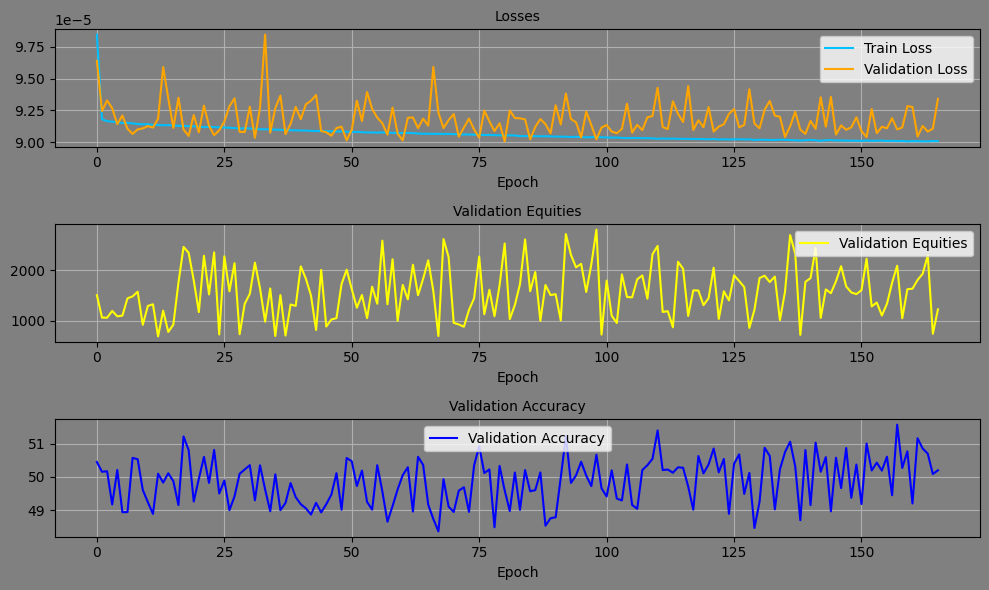

Epoch: 166, Val Equity: 712.26, Val Accuracy: 50.08 train_losses: 0.00028183105521931086, val_losses: 9.21629907679744e-05, Duration: 0:01:07.985034


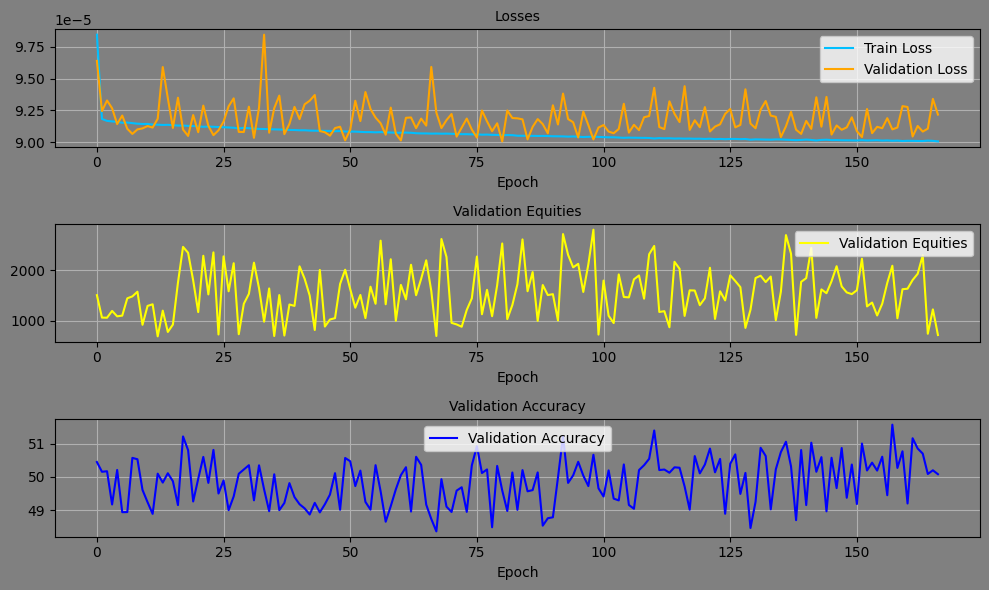

Epoch: 167, Val Equity: 2309.17, Val Accuracy: 51.43 train_losses: 0.00028194487251498947, val_losses: 9.021613368531689e-05, Duration: 0:01:07.665269


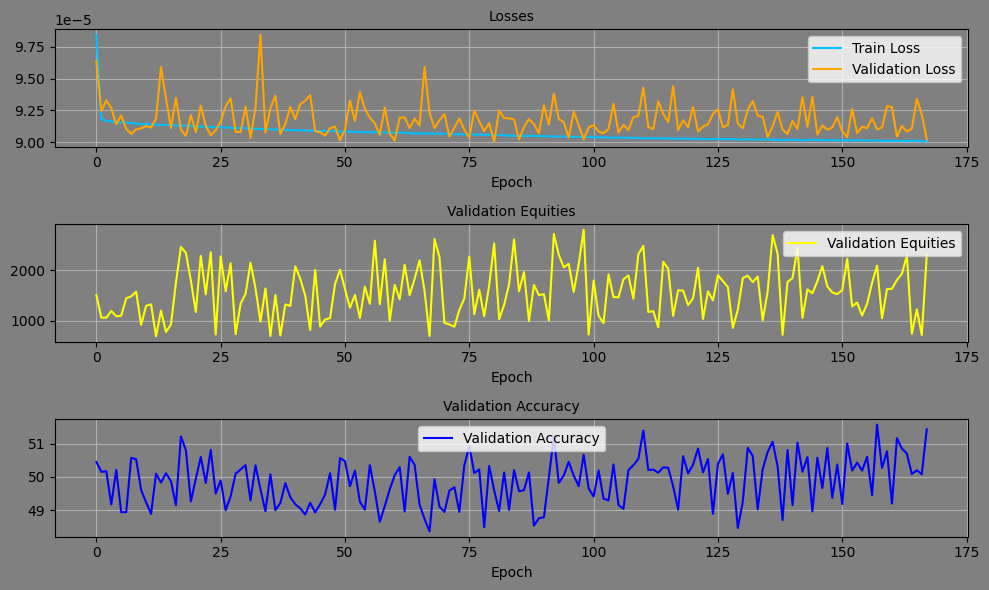

Epoch: 168, Val Equity: 2649.70, Val Accuracy: 51.10 train_losses: 0.00028198395865751435, val_losses: 9.212521399604157e-05, Duration: 0:01:07.603646


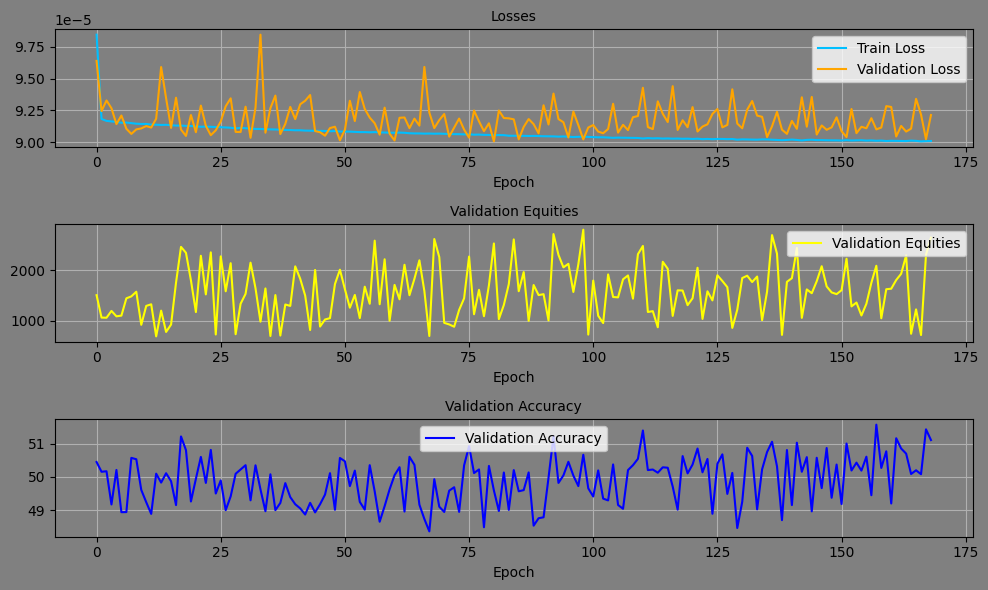

Epoch: 169, Val Equity: 2511.07, Val Accuracy: 50.96 train_losses: 0.0002818554005813443, val_losses: 9.091536048799753e-05, Duration: 0:01:08.277090


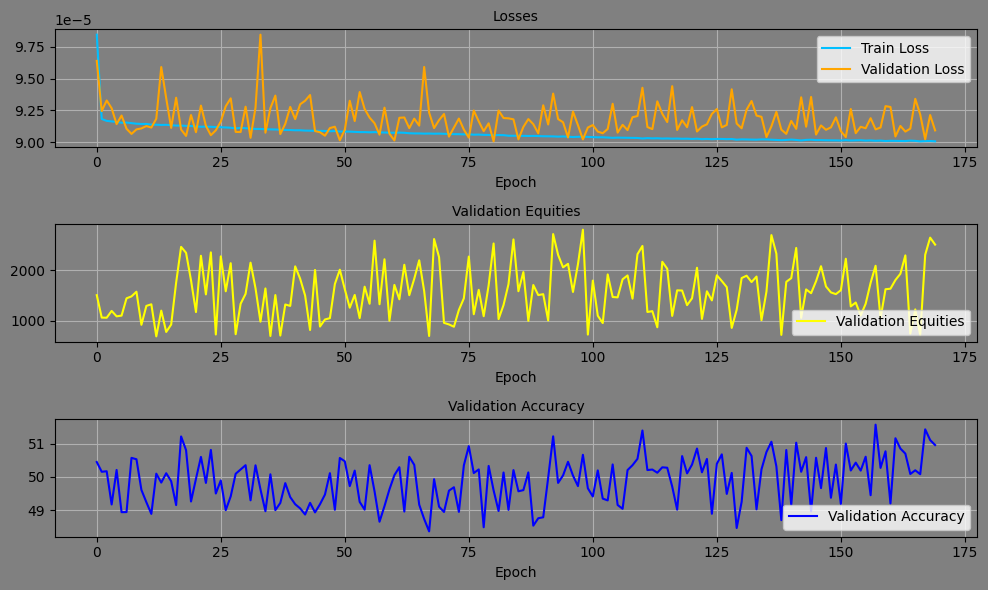

Epoch: 170, Val Equity: 1505.31, Val Accuracy: 50.50 train_losses: 0.00028192963070643705, val_losses: 9.146866796072572e-05, Duration: 0:01:09.124450


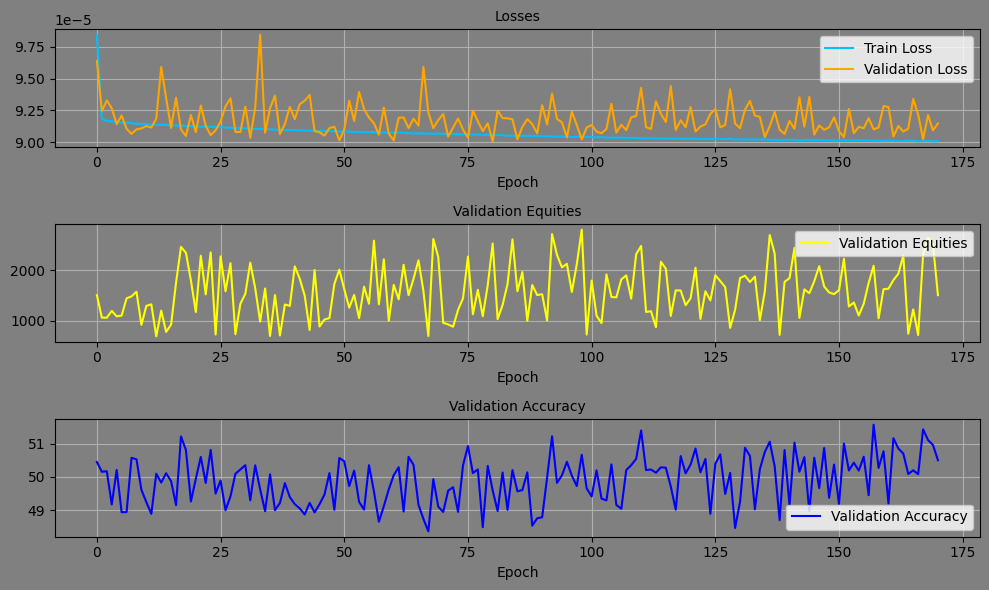

Epoch: 171, Val Equity: 1321.72, Val Accuracy: 50.36 train_losses: 0.00028191204069347864, val_losses: 9.222301741829142e-05, Duration: 0:01:07.935883


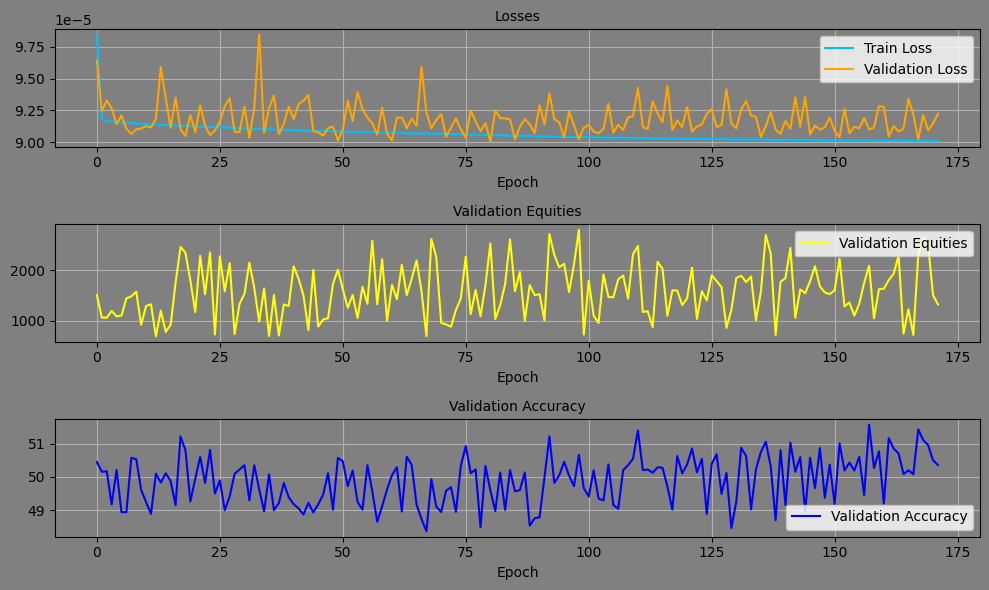

Epoch: 172, Val Equity: 1582.91, Val Accuracy: 49.23 train_losses: 0.0002819467273980081, val_losses: 9.243568638339639e-05, Duration: 0:01:08.297739


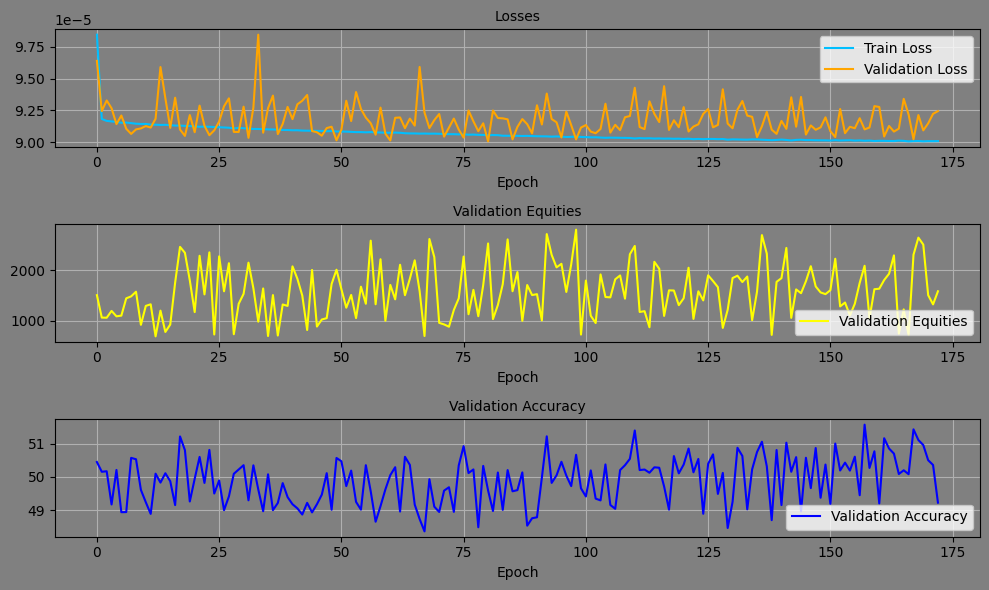

Epoch: 173, Val Equity: 2190.37, Val Accuracy: 51.24 train_losses: 0.0002818274574634615, val_losses: 9.135366417467594e-05, Duration: 0:01:07.996417


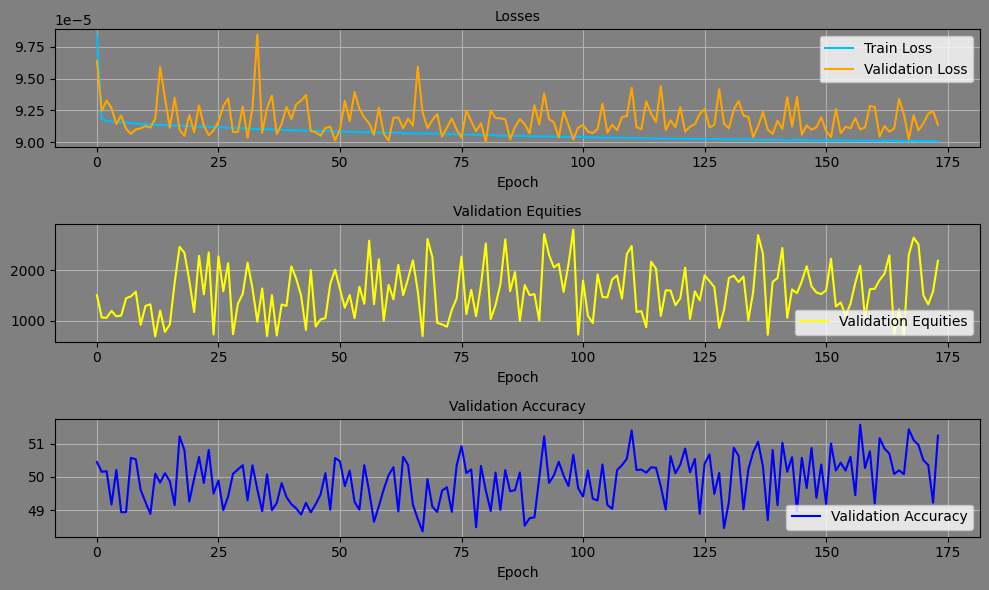

Epoch: 174, Val Equity: 2482.82, Val Accuracy: 50.53 train_losses: 0.00028186848735283014, val_losses: 9.087375656235963e-05, Duration: 0:01:07.727631


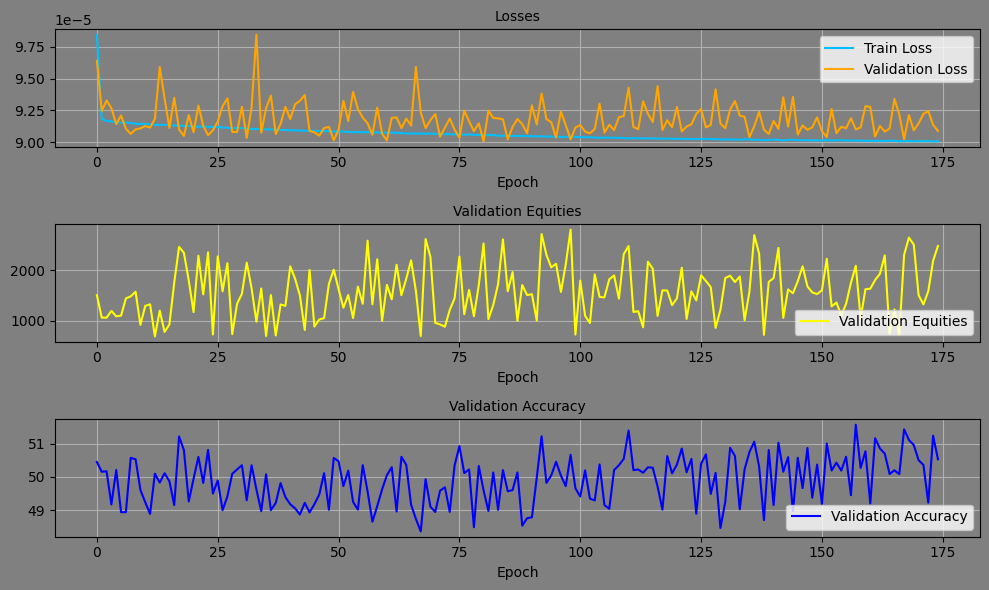

Epoch: 175, Val Equity: 860.12, Val Accuracy: 50.19 train_losses: 0.00028174643673851757, val_losses: 9.143037459580228e-05, Duration: 0:01:07.932182


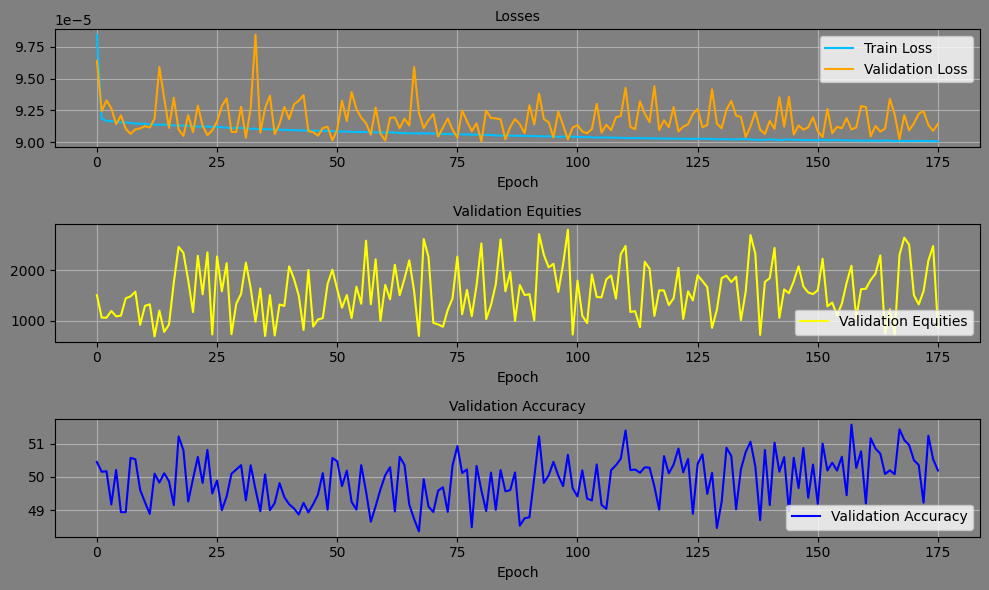

Epoch: 176, Val Equity: 1758.06, Val Accuracy: 49.80 train_losses: 0.00028183125179355825, val_losses: 9.112866973737255e-05, Duration: 0:01:08.244044


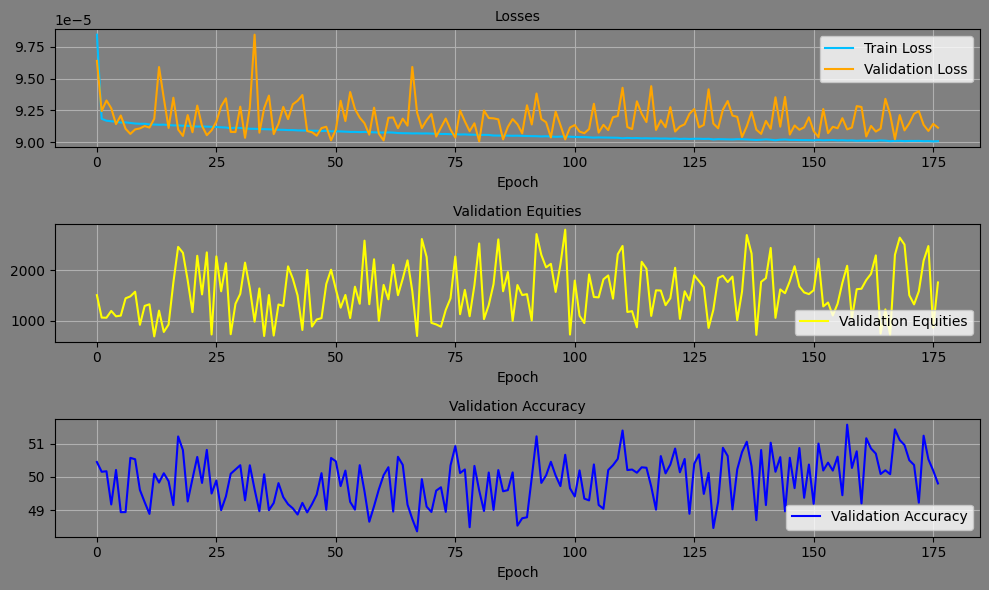

Epoch: 177, Val Equity: 1658.20, Val Accuracy: 49.23 train_losses: 0.00028170357391462216, val_losses: 9.032805974129587e-05, Duration: 0:01:07.988333


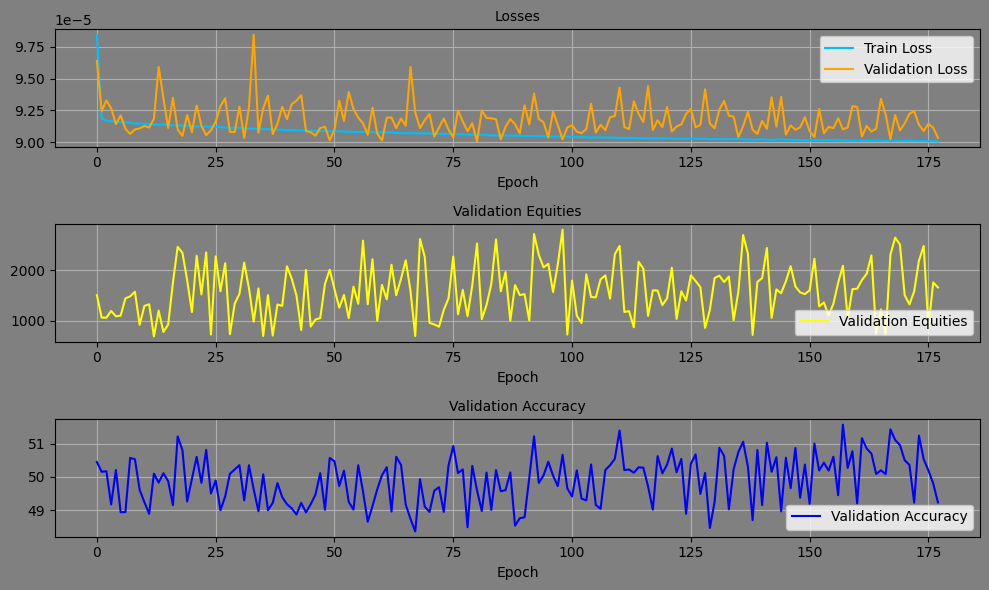

Epoch: 178, Val Equity: 1640.89, Val Accuracy: 49.64 train_losses: 0.0002817366890002912, val_losses: 9.138325549429283e-05, Duration: 0:01:07.811973


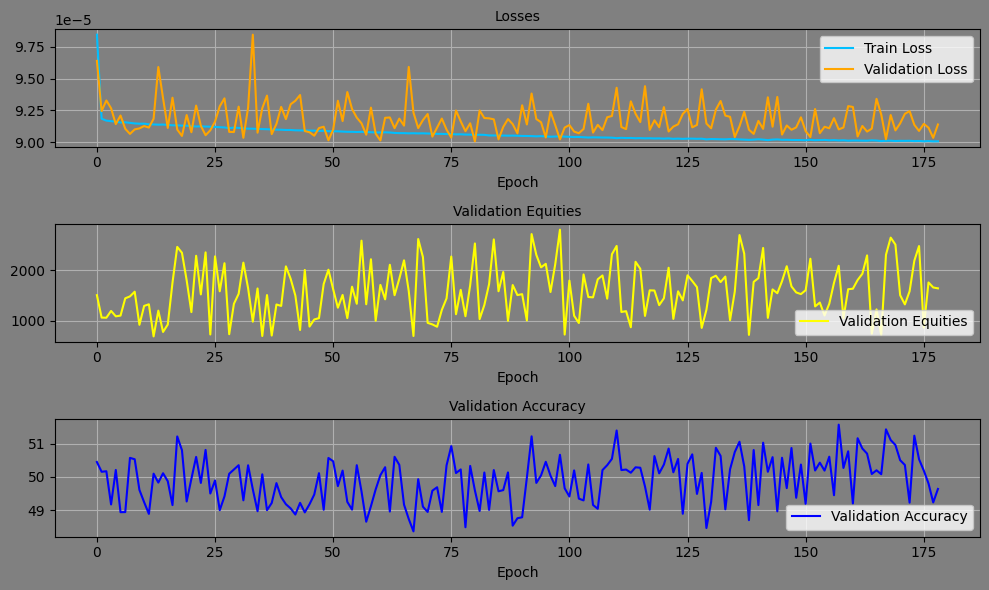

Epoch: 179, Val Equity: 1737.97, Val Accuracy: 50.13 train_losses: 0.0002817811085255778, val_losses: 9.062064054887742e-05, Duration: 0:01:07.966952


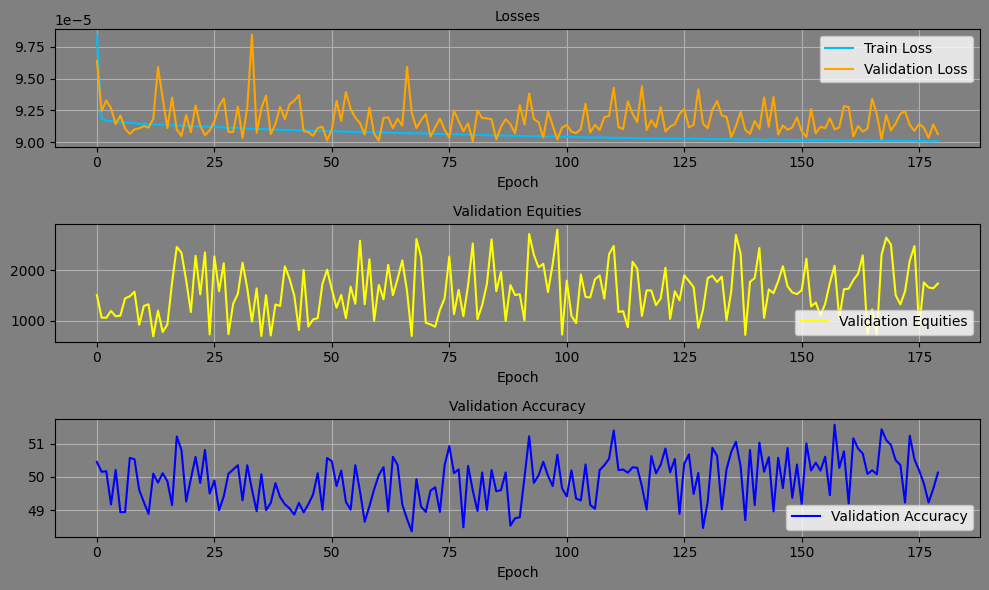

Epoch: 180, Val Equity: 853.68, Val Accuracy: 50.10 train_losses: 0.00028171535177257394, val_losses: 9.512050746707246e-05, Duration: 0:01:08.162120


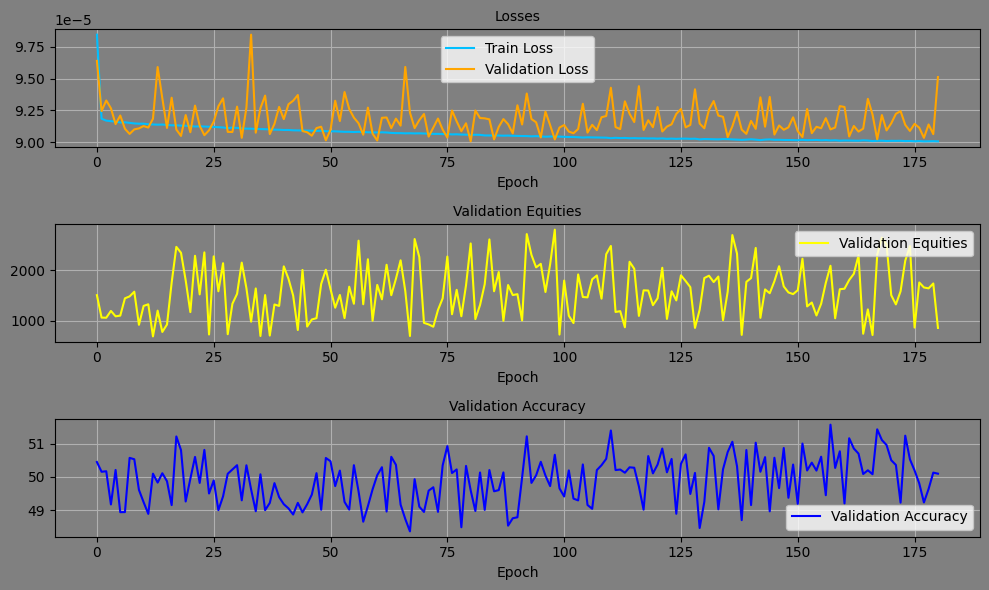

Epoch: 181, Val Equity: 2415.79, Val Accuracy: 50.16 train_losses: 0.0002817635655567874, val_losses: 9.342024713987485e-05, Duration: 0:01:07.469258


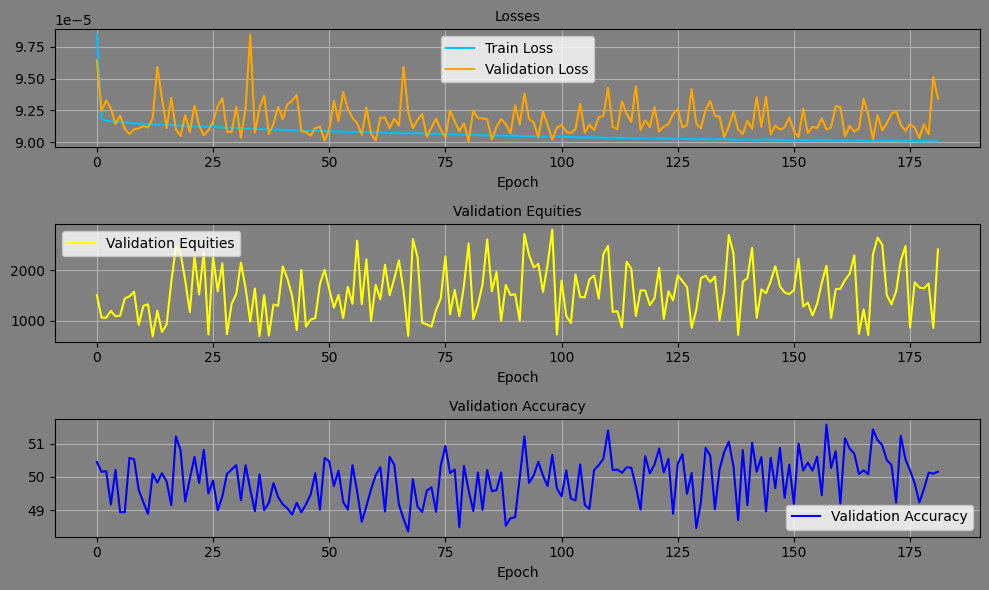

Epoch: 182, Val Equity: 2580.58, Val Accuracy: 51.25 train_losses: 0.00028173796899623785, val_losses: 9.071522072190419e-05, Duration: 0:01:08.161647


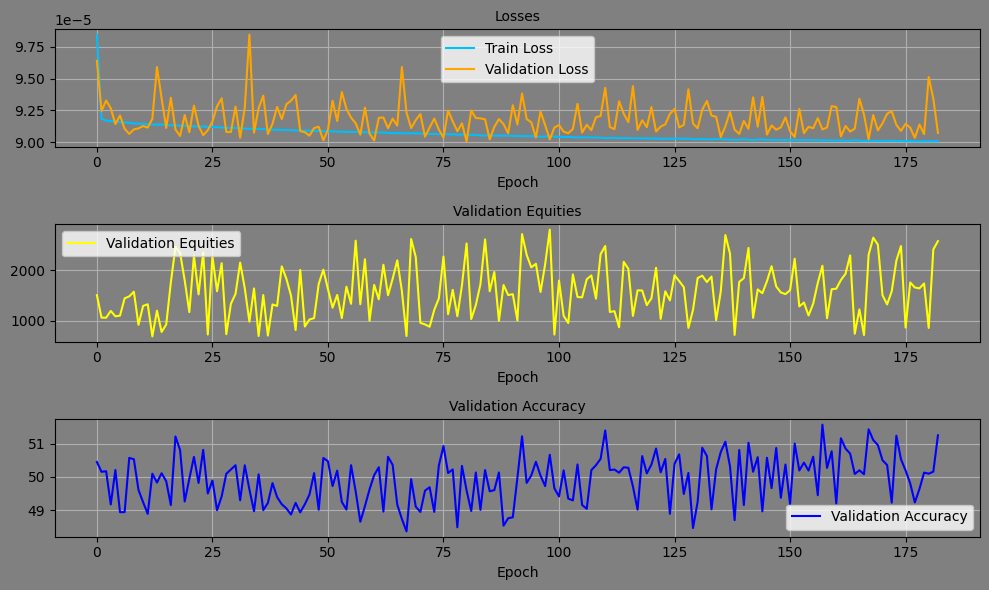

Epoch: 183, Val Equity: 2250.35, Val Accuracy: 51.15 train_losses: 0.0002816347281959605, val_losses: 9.04105618246831e-05, Duration: 0:01:07.952540


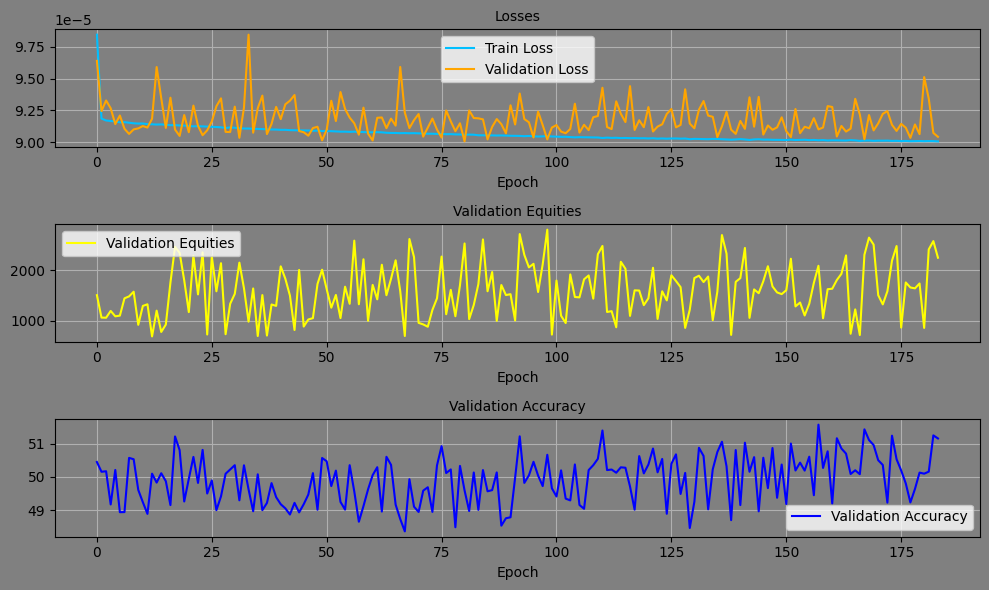

Epoch: 184, Val Equity: 1578.57, Val Accuracy: 50.62 train_losses: 0.00028171586519619733, val_losses: 9.114774729823694e-05, Duration: 0:01:07.942761


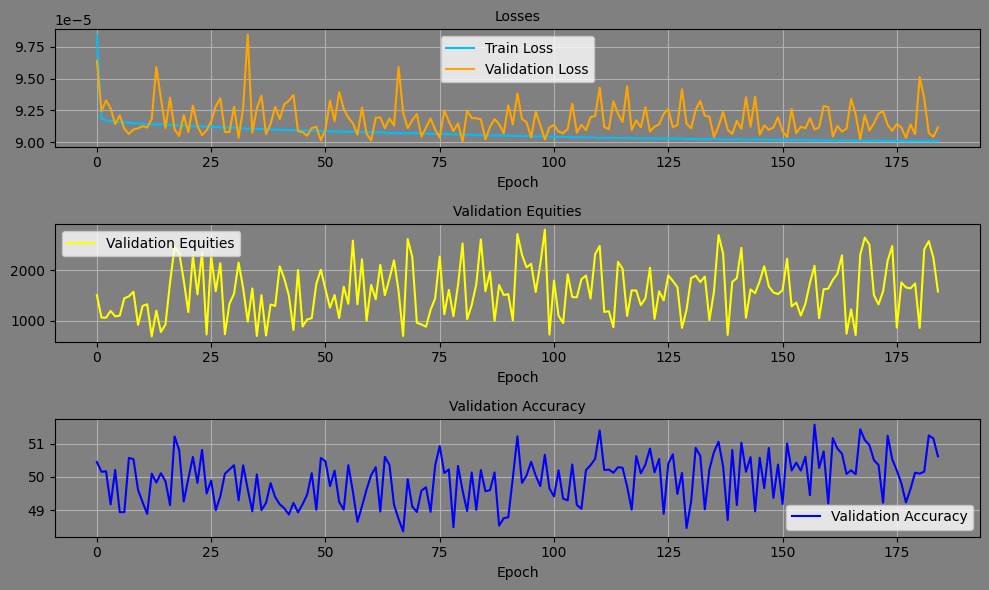

Epoch: 185, Val Equity: 637.61, Val Accuracy: 49.96 train_losses: 0.00028151200602656546, val_losses: 9.295839117839932e-05, Duration: 0:01:08.214057


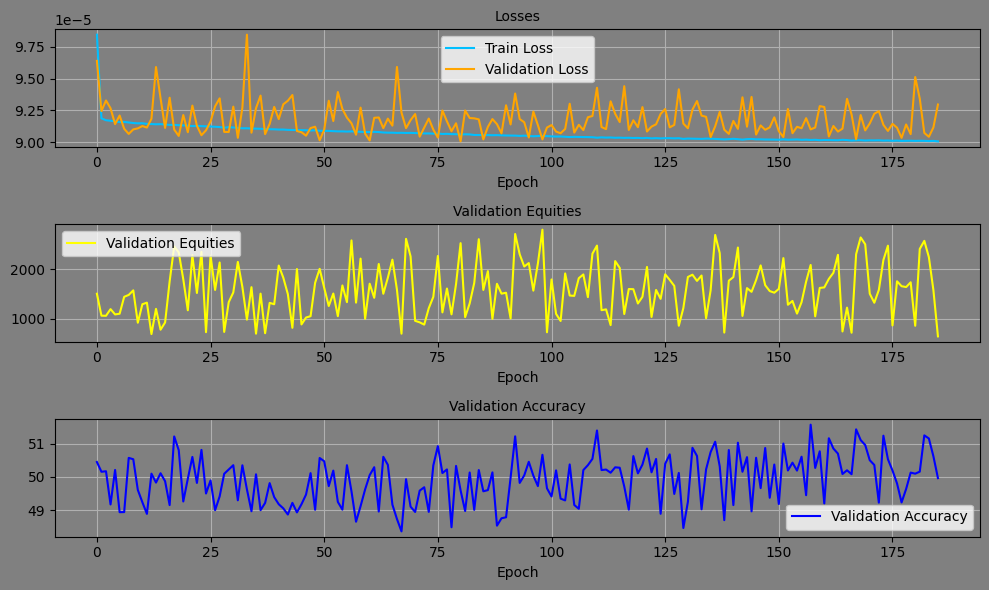

Epoch: 186, Val Equity: 2747.20, Val Accuracy: 51.19 train_losses: 0.0002816264048382754, val_losses: 9.098832379095256e-05, Duration: 0:01:07.806643


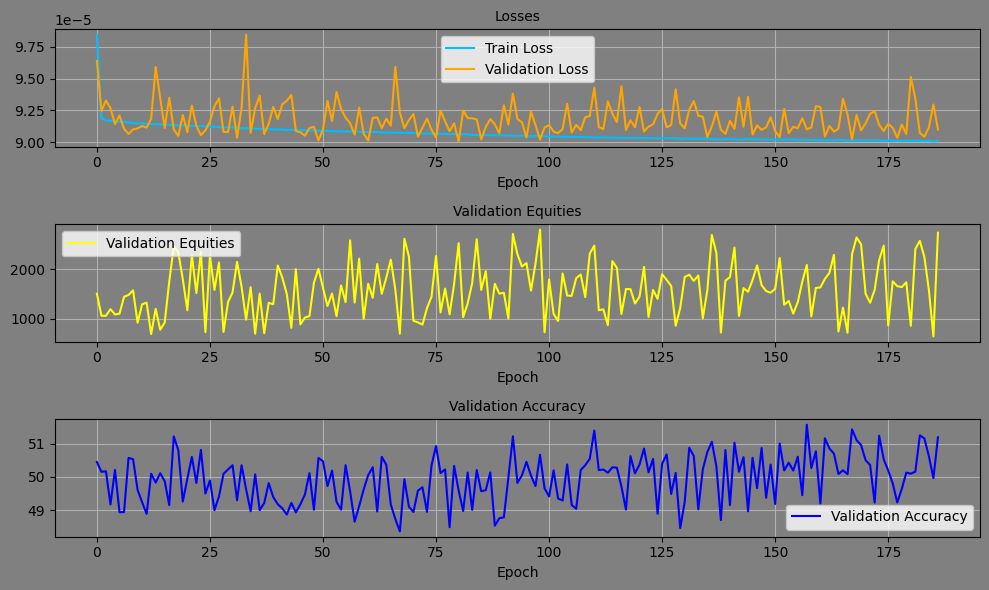

Epoch: 187, Val Equity: 1074.51, Val Accuracy: 50.22 train_losses: 0.0002816267405310137, val_losses: 9.127258090302348e-05, Duration: 0:01:07.923444


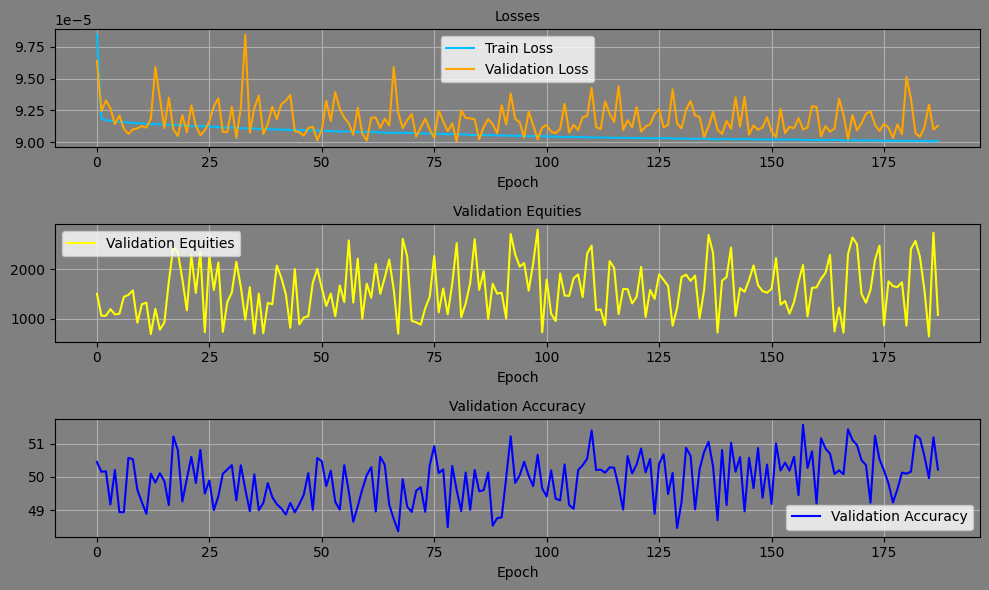

Epoch: 188, Val Equity: 2212.39, Val Accuracy: 50.57 train_losses: 0.00028164291013230304, val_losses: 9.048490755958483e-05, Duration: 0:01:08.187217


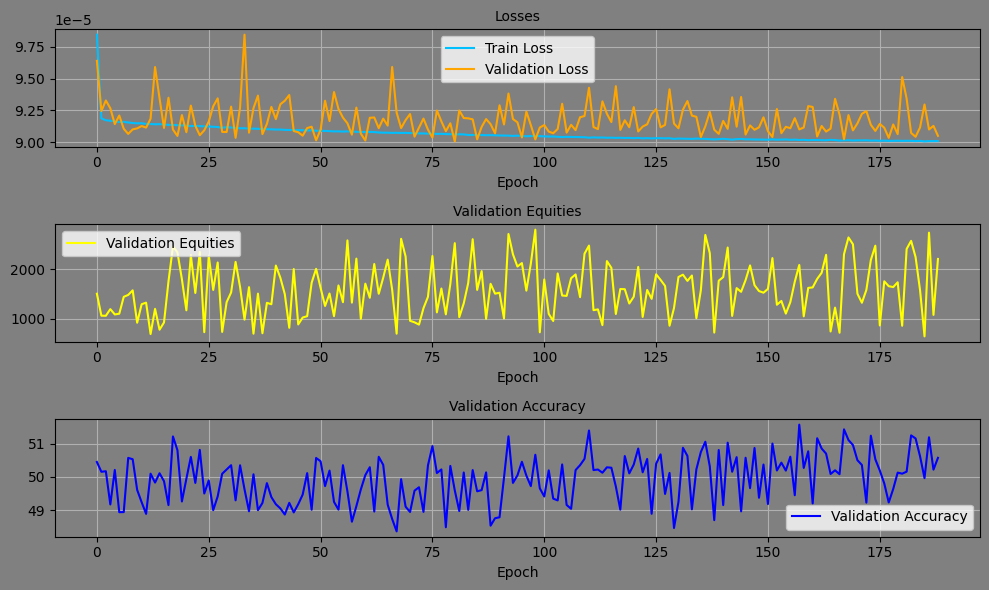

Epoch: 189, Val Equity: 947.21, Val Accuracy: 50.27 train_losses: 0.00028153932982199765, val_losses: 9.065429912880063e-05, Duration: 0:01:07.828374


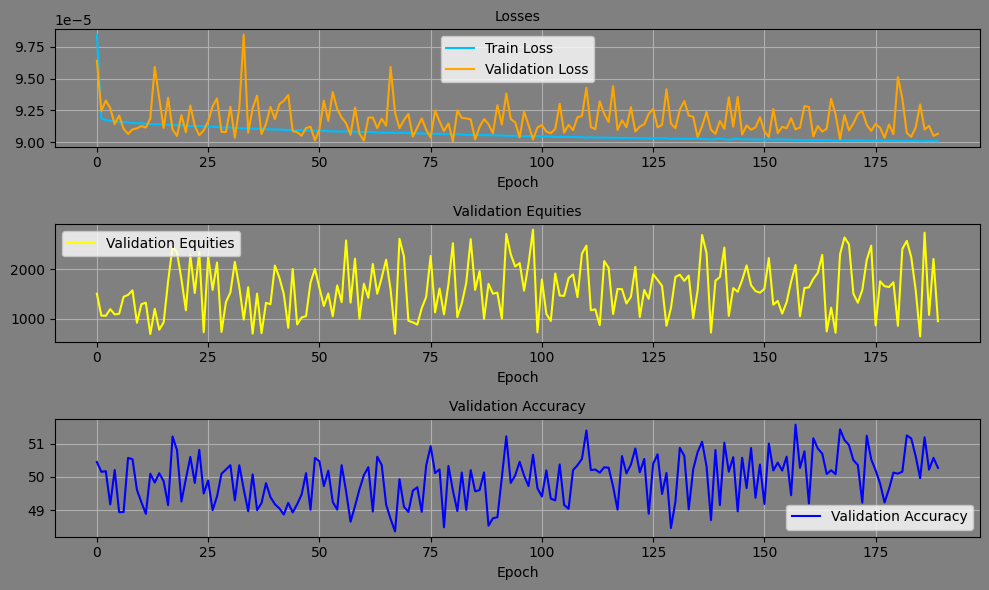

Epoch: 190, Val Equity: 1919.86, Val Accuracy: 49.98 train_losses: 0.00028151714410827984, val_losses: 9.069562656804919e-05, Duration: 0:01:07.638813


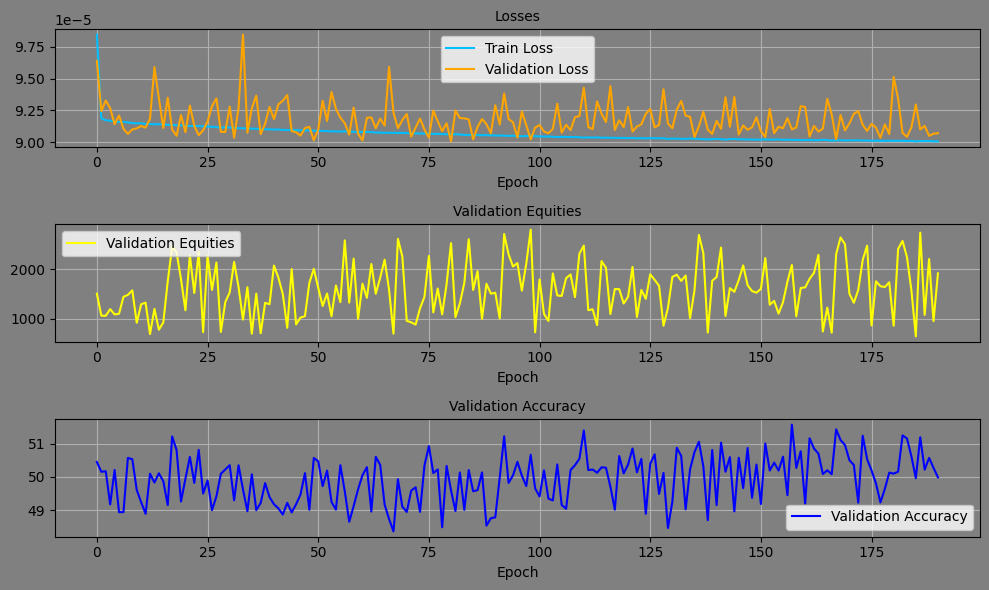

Epoch: 191, Val Equity: 626.06, Val Accuracy: 50.04 train_losses: 0.0002815358229869657, val_losses: 9.419151319889352e-05, Duration: 0:01:07.786008


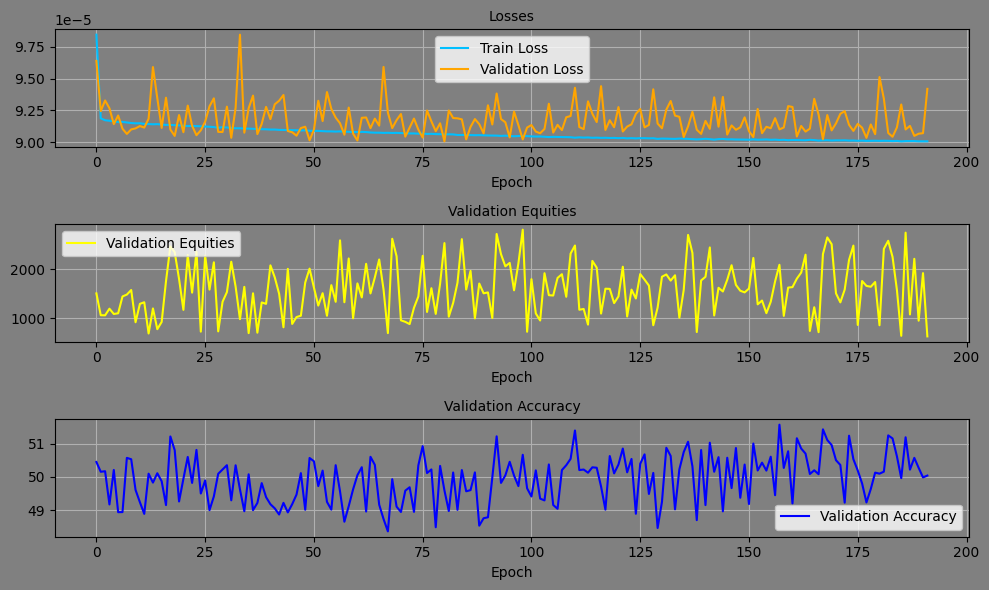

Epoch: 192, Val Equity: 2040.09, Val Accuracy: 50.79 train_losses: 0.0002816677233711307, val_losses: 9.068803046829998e-05, Duration: 0:01:07.557145


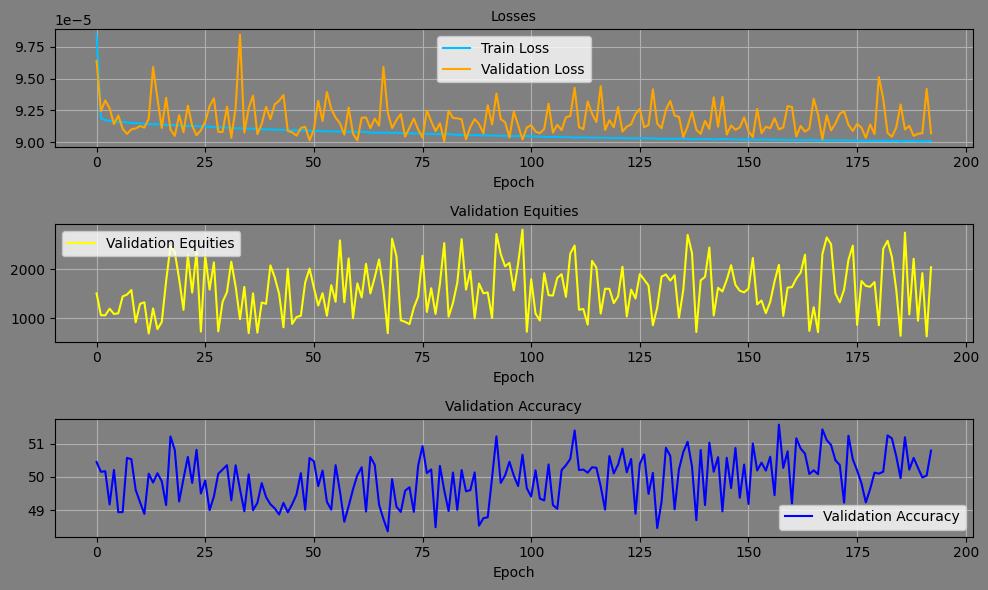

Epoch: 193, Val Equity: 2342.40, Val Accuracy: 50.66 train_losses: 0.0002814619182396104, val_losses: 9.336359653389081e-05, Duration: 0:01:07.972259


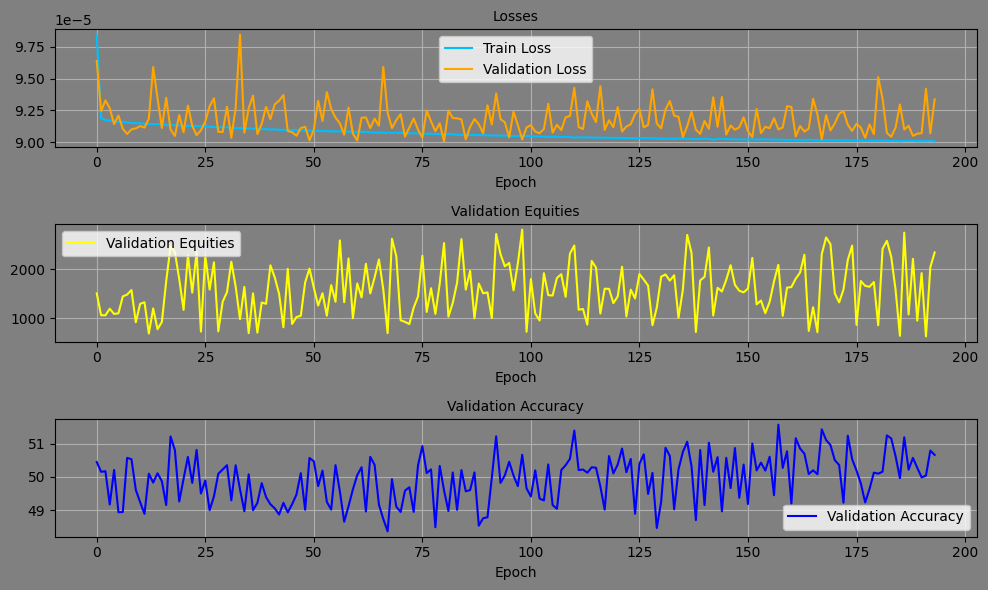

Epoch: 194, Val Equity: 944.82, Val Accuracy: 50.18 train_losses: 0.0002814593087703735, val_losses: 9.231776493834332e-05, Duration: 0:01:10.433050


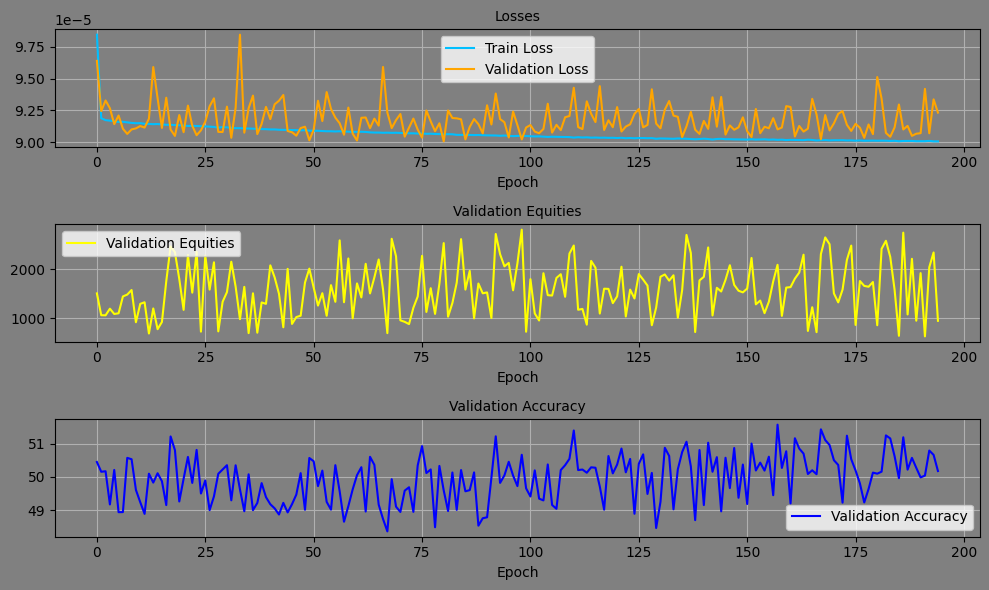

Epoch: 195, Val Equity: 1398.53, Val Accuracy: 48.58 train_losses: 0.00028150161684825284, val_losses: 9.056120325112715e-05, Duration: 0:01:08.168768


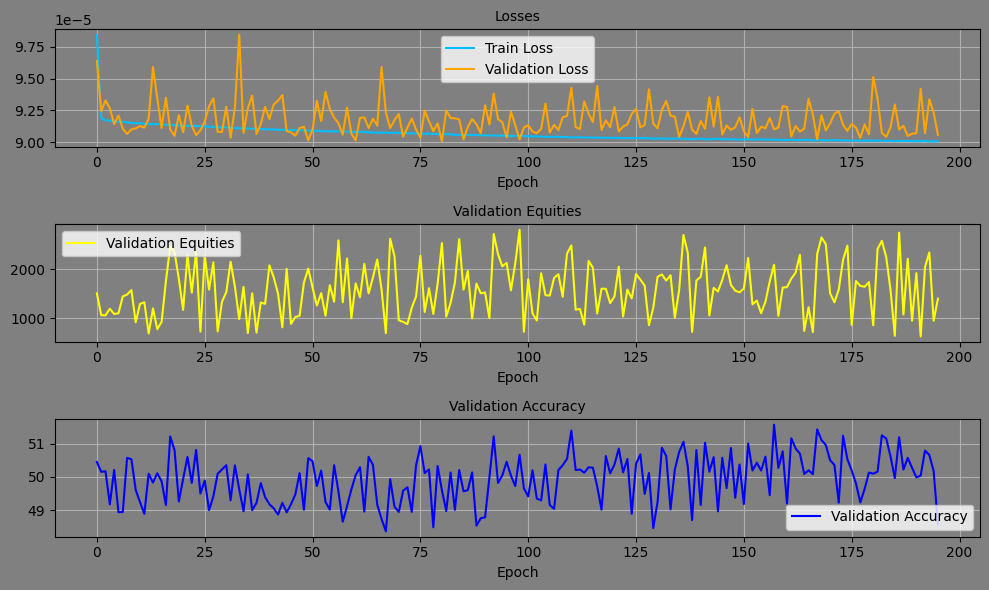

Epoch: 196, Val Equity: 1314.94, Val Accuracy: 48.76 train_losses: 0.00028145155501840596, val_losses: 9.06426357687451e-05, Duration: 0:01:08.158171


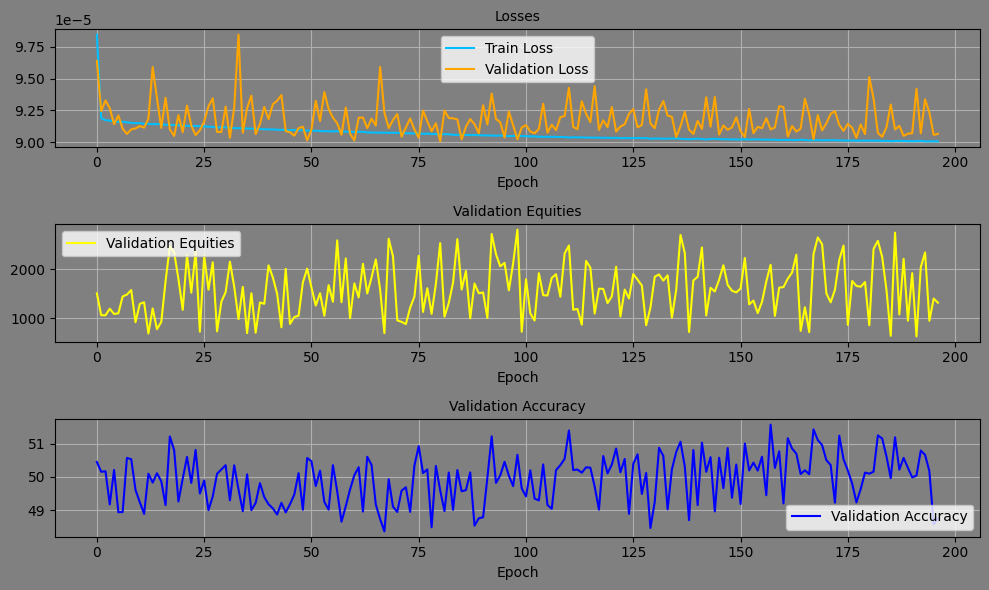

Epoch: 197, Val Equity: 1512.56, Val Accuracy: 51.19 train_losses: 0.00028140216592302704, val_losses: 9.162801870843396e-05, Duration: 0:01:16.119666


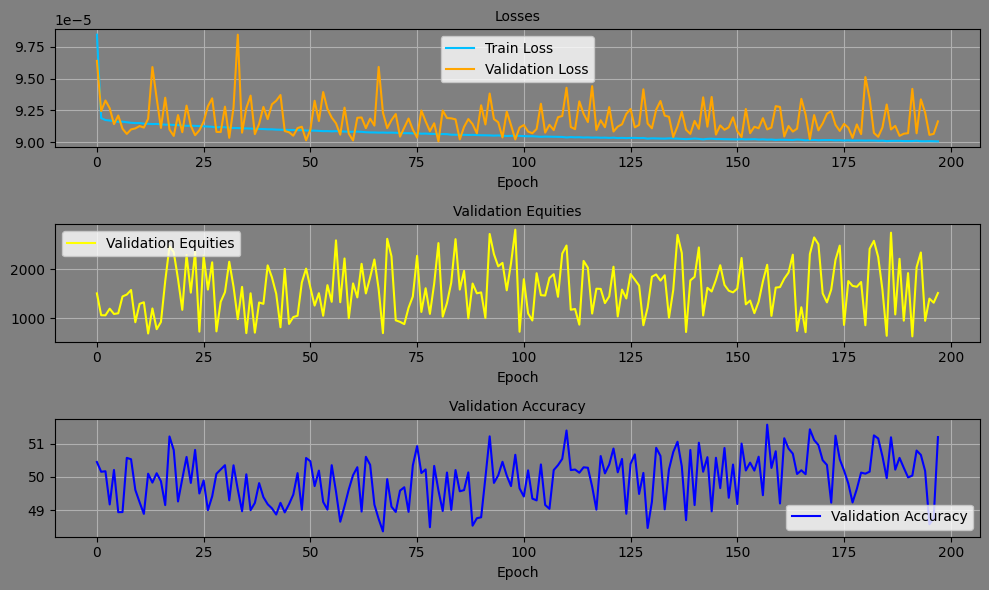

Epoch: 198, Val Equity: 2081.41, Val Accuracy: 49.78 train_losses: 0.0002813808440901713, val_losses: 9.068277722690254e-05, Duration: 0:01:11.496380


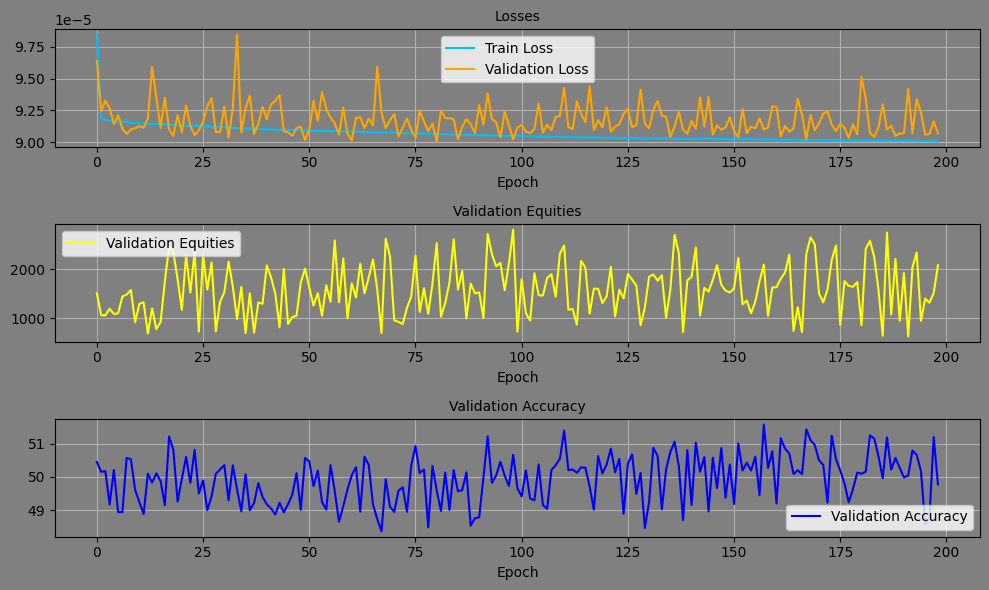

Epoch: 199, Val Equity: 2067.16, Val Accuracy: 50.82 train_losses: 0.00028146191781952366, val_losses: 9.108260564971715e-05, Duration: 0:01:10.589791


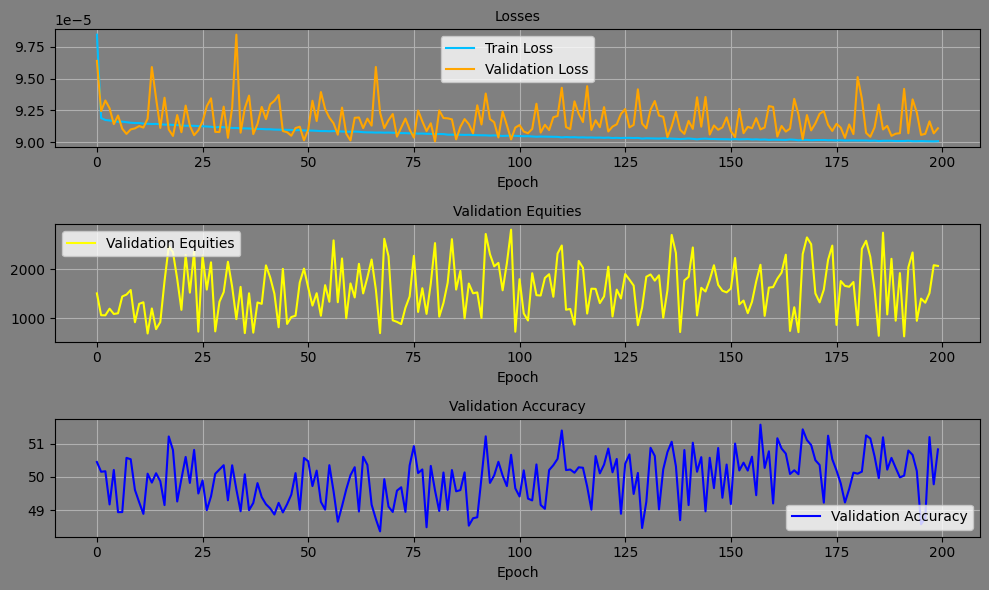

In [15]:
for epoch in range(epoch, num_epochs):

    # Track duration
    dt0_epoch = datetime.now()

    # Create mini batches
    mini_batches, seed = create_minibatches(X_train, Y_train, batch_size, seed, shuffle=True)

    train_losses_batch = []

    for X_train_batch, Y_train_batch in mini_batches:
        # Set train mode
        model.train()

        # Reset the gradients
        optimizer.zero_grad()

        # Forward propagation
        Y_hat_train = model(X_train_batch) # Shape: (batch_size, num_features)

        # Calculate loss (train)
        train_loss = criterion(Y_hat_train, Y_train_batch)

        # Backprop
        train_loss.backward()

        # Update optimizer
        optimizer.step()

        # Keep track of training losses
        train_losses_batch.append(train_loss.item())

    # Predict on validation data -- X_test is never touched here, only X_val.
    # This is the slice the loop is "allowed" to check every epoch to decide
    # when to stop / which checkpoint to keep.
    with torch.no_grad():

        # Set evaluation mode
        model.eval()

        # Forward propagation
        Y_pred_val = model(X_val)

        # Calculate validation loss
        val_loss = criterion(Y_pred_val, Y_val)

    # Convert 'Y_pred_val' to numpy
    Y_pred_val_cpu = Y_pred_val.detach().cpu().numpy()

    train_losses.append(np.mean(train_losses_batch))
    val_losses.append(val_loss.item())

    # ===================== Backtest (validation only) =====================
    equities = []    # Store equity (account value) over time
    pos_size = 1000  # Fixed position size ($1000 per trade)
    equity = 1000    # Starting capital
    correct_pred = 0 # Initialize correct prediction

    actions = Y_pred_val_cpu[:, 0] > 0 # Get model's buy/sell predictions

    for i in range(len(X_val)-1):
        curr_open = backtest_opens_val[i]   # the price we enter at.
        curr_close = backtest_closes_val[i] # the price we exit at.
        curr_action = actions[i]        # the model's signal (buy or sell).

        # Calculate percentage price change
        pct_change = (curr_close - curr_open) / curr_open

        # Profit or loss in dollars
        pnl = np.abs(pos_size * pct_change)

        # Update equity depending on action and price move
        if curr_action == 1:     # Long position (Buy side)
            if pct_change > 0:
                equity += pnl    # Price up -> profit
                correct_pred += 1
            elif pct_change < 0:
                equity -= pnl    # Price down -> loss

        elif curr_action == 0:   # Short position
            if pct_change > 0:
                equity -= pnl    # Price up -> loss
            elif pct_change < 0:
                equity += pnl    # Price down -> profit
                correct_pred += 1

        equities.append(equity) # Save current equity
    # ========================================================

    # Calculate percentage accuracy
    accuracy = correct_pred / len(X_val) * 100

    # Save final equity for each epoch
    val_equity_epochs.append(equity)
    val_accuracy_epochs.append(accuracy)

    print(f'Epoch: {epoch}, Val Equity: {equity:.2f}, Val Accuracy: {accuracy:.2f} train_losses: {train_losses[-1]}, val_losses: {val_losses[-1]}, Duration: {datetime.now() - dt0_epoch}')

    # Save training process
    torch.save({
        'epoch': epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'train_losses': train_losses,
        'val_losses': val_losses,
        'val_equity_epochs': val_equity_epochs,
        'val_accuracy_epochs': val_accuracy_epochs,
        'best_val_equity': best_val_equity,
        'seed': seed,
    }, 'training_process')

    # Manual-inspection checkpoints, same threshold convention as before, but
    # now scored on validation equity, not test equity.
    if equity > 3000:
        torch.save(model.state_dict(), f"models/valeq_{equity:.0f}_ep_{epoch}.pt")

    # The single best checkpoint by validation equity across every epoch run
    # so far -- this is the one file the final held-out test cell loads.
    if equity > best_val_equity:
        best_val_equity = equity
        torch.save(model.state_dict(), "models/best_by_validation.pt")

    # Plot training process
    fig, axs = plt.subplots(nrows=3, ncols=1, figsize=(10, 6))
    scaler_valloss = MinMaxScaler(feature_range=(np.min(val_losses)-0.0000000001, np.max(val_losses)))

    # Plot Train Loss and Validation Loss
    axs[0].set_title(f"Losses", fontsize=10)
    axs[0].plot(scaler_valloss.fit_transform(np.array(train_losses).reshape(-1,1)), label='Train Loss', color='deepskyblue')
    axs[0].plot(val_losses, label='Validation Loss', color='orange')
    axs[0].set_xlabel("Epoch")
    axs[0].legend()
    axs[0].grid()
    # Plot Equities
    axs[1].set_title(f"Validation Equities", fontsize=10)
    axs[1].plot(val_equity_epochs, label='Validation Equities', color='yellow')
    axs[1].set_xlabel("Epoch")
    axs[1].legend()
    axs[1].grid()
    # Plot Accuracy
    axs[2].set_title(f"Validation Accuracy", fontsize=10)
    axs[2].plot(val_accuracy_epochs, label='Validation Accuracy', color='blue')
    axs[2].set_xlabel("Epoch")
    axs[2].legend()
    axs[2].grid()
    # Set background color and paper color
    fig.patch.set_facecolor(mcolors.to_hex('grey'))  # Set paper color
    for ax in axs.flat:
        ax.set_facecolor(mcolors.to_hex('grey'))  # Set bg color
    # Display
    plt.tight_layout()
    plt.savefig(f'training_process.png')
    plt.show()
    plt.close()

**Final held-out test evaluation (run exactly once, after training is done)**

/var/folders/4f/6p47vdgn5_3dwdmxhs9cypqm0000gn/T/ipykernel_80658/885537652.py:10: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  test_model.load_state_dict(torch.load("models

HELD-OUT TEST (checked exactly once): final equity=161.70, accuracy=48.50%


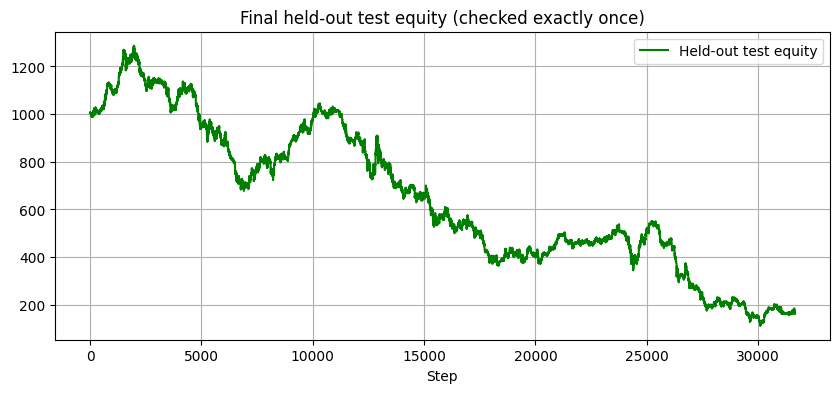

In [16]:
# ===================== FINAL, ONE-TIME TEST EVALUATION =====================
# The only cell in this notebook that touches X_test/Y_test. Runs exactly
# once, after training is completely finished, using
# models/best_by_validation.pt -- the single checkpoint that scored best on
# the VALIDATION set across every epoch. No decision anywhere above this
# cell was made by looking at test-set performance, so this is the first
# honest out-of-sample number in this project.

test_model = Model()
test_model.load_state_dict(torch.load("models/best_by_validation.pt", map_location=device))
test_model.to(device)
test_model.eval()

with torch.no_grad():
    Y_pred_test = test_model(X_test.to(device)).cpu()

Y_pred_test_cpu = Y_pred_test.detach().numpy()

pos_size = 1000
equity = 1000
correct_pred = 0
test_equities = []

actions = Y_pred_test_cpu[:, 0] > 0

for i in range(len(X_test) - 1):
    curr_open = backtest_opens_test[i]
    curr_close = backtest_closes_test[i]
    curr_action = actions[i]

    pct_change = (curr_close - curr_open) / curr_open
    pnl = np.abs(pos_size * pct_change)

    if curr_action == 1:
        if pct_change > 0:
            equity += pnl
            correct_pred += 1
        elif pct_change < 0:
            equity -= pnl
    elif curr_action == 0:
        if pct_change > 0:
            equity -= pnl
        elif pct_change < 0:
            equity += pnl
            correct_pred += 1

    test_equities.append(equity)

test_accuracy = correct_pred / len(X_test) * 100
print(f"HELD-OUT TEST (checked exactly once): final equity={equity:.2f}, accuracy={test_accuracy:.2f}%")

plt.figure(figsize=(10, 4))
plt.plot(test_equities, label="Held-out test equity", color="green")
plt.title("Final held-out test equity (checked exactly once)")
plt.xlabel("Step")
plt.legend()
plt.grid()
plt.savefig("test_equity_final.png")
plt.show()